( Previous: [**3.1 Resistive Diode Circuits**](../Chapter.3/chapter3.ipynb)( [**TOC**](../TOC.md) | Next: [**5.1 Transistor Models and Circuits**](../chapter.5/chapter5.ipynb) )

**Chapter 4**

## Rectification and Detection

**By Abbas Kohan and M. B. Ghaznavi-Ghoushchi**

## 4.1 Introduction

Rectification can be defined rather broadly as the process that modifies the direct component of a voltage or current. Since rectifica- tion can occur in any circuit that contains a nonlinear element, this process plays a very important role in electronic circuits. In some cases the effect is desired, as in converting an alternating current to a direct current. In others the effect is undesirable: for example, the distortion of voltage or current waveforms in circuits that are supposedly linear but contain unavoidable nonlinearities. Since nonlinearities will be represented in circuit models by diodes or diode approximations, the circuit concepts and methods of analysis introduced in this chapter (as well as those of the preceding chapter) apply to circuits using triodes, transistors, and other devices.
Rectifier circuits usually include energy-storage elements to smooth t.he ripples in the output voltage, thus producing a more effective con- version of alternating current to direct current. Such rectifier-filter circuits are used in most electronic systems. They serve to convert a-c voltages from the power distribution system to d-c voltages required for the operation of most electronic devices.
In rectifier circuits used for power conversion, the input a-c voltage amplitude is fixed, but the output power varies with the changing demands of the d-c load. Important design considerations for this case are: the ratio of d-c load power to a-c input power (efficiency), variation of output voltage with load current (regulation), and residual a-c fluctuations present in the output (ripple).
Where the speed of response of the rectifier is important (as it may be in a recording voltmeter), we are concerned with the detection problem. Detection (often called demodulation) is closely related to the rectification process. The amplitude of an a-c voltage may be time- varying, as is the case with the amplitude-modulated carrier of a broad- casting station. The amplitude varies in accordance with the sound level of the speech or music being broadcast. The demodulator or detector in an a-m receiver must produce an output that follows the audio-frequency variations faitfully.

Text(0.5, 1.0, 'Original')

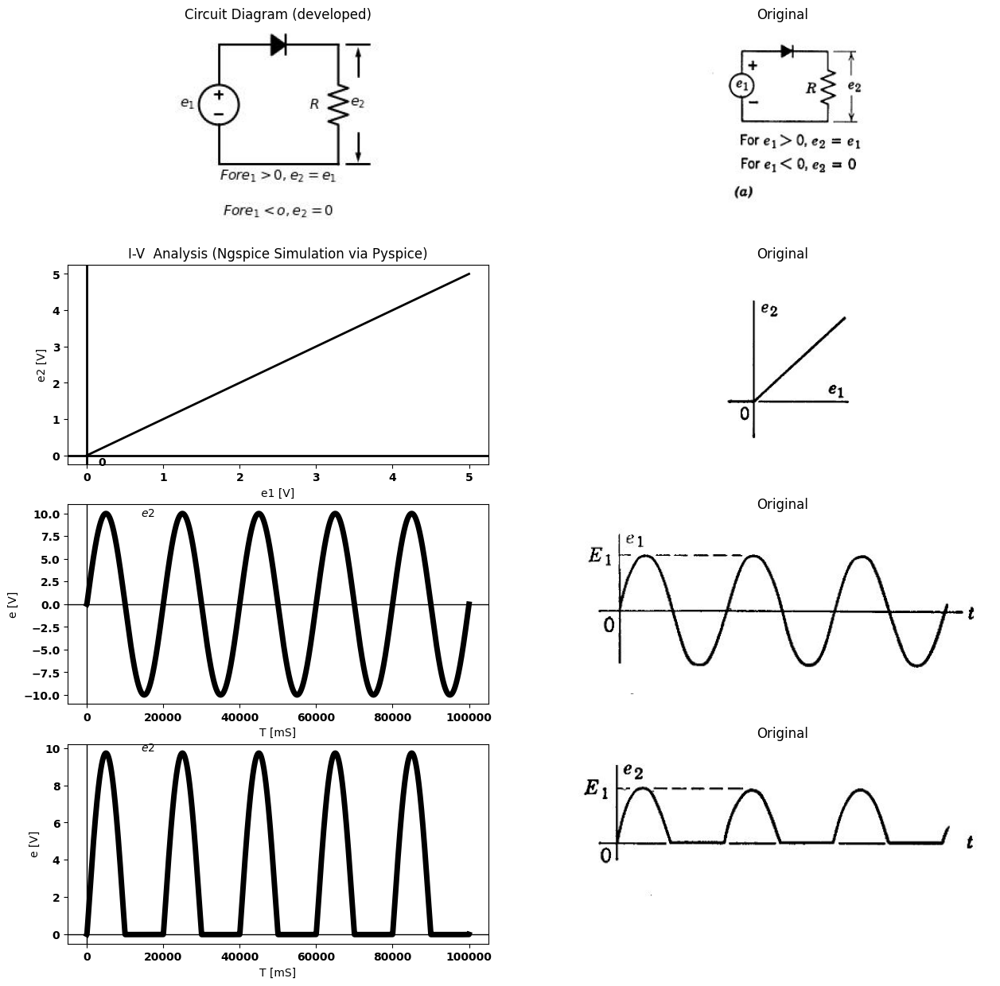

In [17]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (D := elm.Diode(fill=True))
d += (R1:= elm.Resistor().down().label('$R$' , 'bot', ofst=-1))
d += elm.Line().left().length(3).label('$For e_1>0, e_2=e_1$\n\n$For e_1 <o ,e_2=0$','bottom') 
d += elm.SourceV().up().label('$e_1$' , 'top')
d += elm.Arrow().down().at((3.5, -2.2)).length(0.75).color('black')
d += elm.Arrow().up().at((3.5, -0.8)).length(0.75).label('$e_2$', 'right', ofst=-1.6).color('black') 
d += elm.Line().right().length(0.6).at((3.2, 0))
d += elm.Line().right().length(0.6).at((3.2, -3))
d.save('Drawings/4-1a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-1a.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 1@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[1, 0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=2)
axs[1, 0].set_title('I-V  Analysis (Ngspice Simulation via Pyspice)')
axs[1, 0].set_ylabel('e2 [V]')
axs[1, 0].set_xlabel('e1 [V]')
axs[1, 0].text( 0.2, -0.2, '0', ha='center', va='center')

axs[1, 0].axhline(0, color='black', linewidth=2)
axs[1, 0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 1@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['1'],'black',linewidth=5)
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].text(16000, 10, '$e2$', ha='center', va='center')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 1@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['2'],'black',linewidth=5)
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].text(16000, 10, '$e2$', ha='center', va='center')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

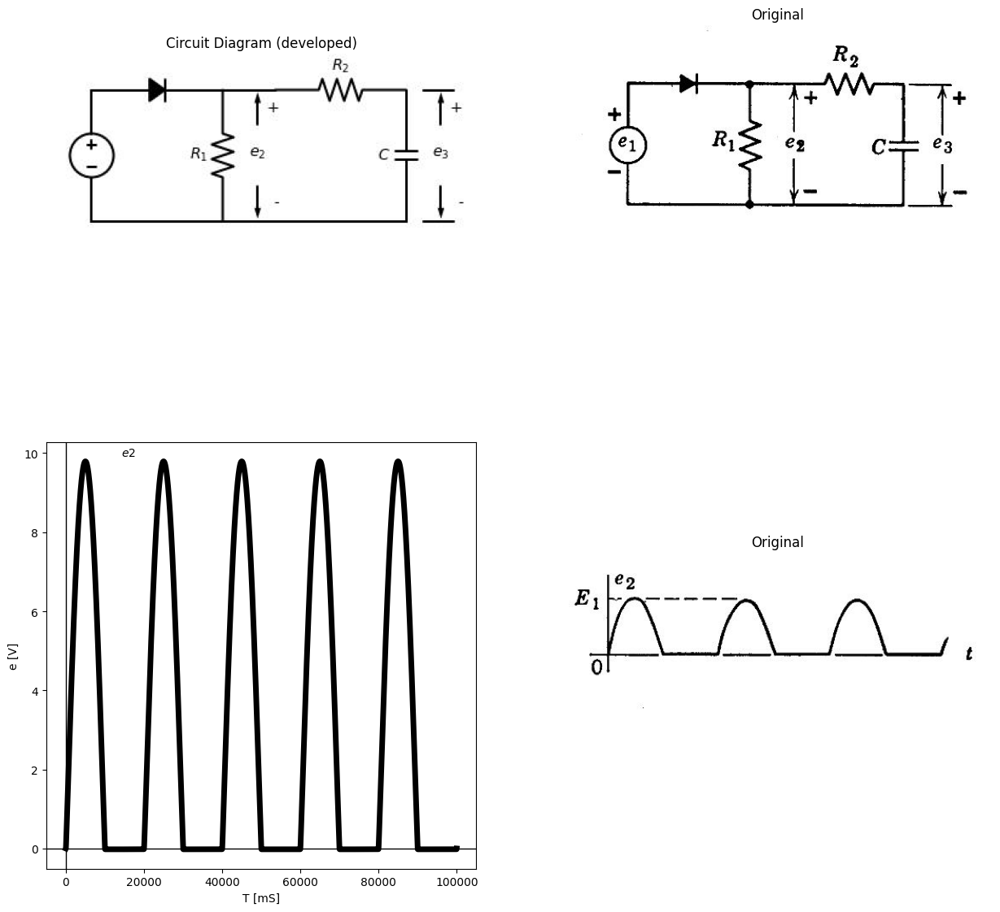

In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (D := elm.Diode(fill=True))
d += (R1:= elm.Resistor().down().label('$R_1$' , 'bot', ofst=-1))
d += elm.Line().left().length(3) 
d += elm.SourceV().up()
d += elm.Arrow().down().at((3.8, -2.2)).length(0.75).color('black').label('-', ofst=-0.5  )
d += elm.Arrow().up().at((3.8, -0.8)).length(0.75).label('$e_2$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.5 ) 
d += elm.Line().right().length(1.2).at((3, 0))
d += elm.Line().right().length(4.2).at((3, -3))
d += (R2:= elm.Resistor().right().label('$R_2$' , 'bot', ofst=-1)).at((4.2, 0))
d += (C1:= elm.Capacitor().down().at(R2.end)).label('$C$')
d += elm.Arrow().down().at((8, -2.2)).length(0.75).color('black').label('-', ofst=-0.5  )
d += elm.Arrow().up().at((8, -0.8)).length(0.75).label('$e_3$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.5 ) 
d += elm.Line().right().length(0.7).at((7.6, 0))
d += elm.Line().right().length(0.7).at((7.6, -3))
d.save('Drawings/4-1a2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-1a2.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1e.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 2@u_Ohm)
circuit.R(2, '2','3', 20000@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_nF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=5)
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].text(16000, 10, '$e2$', ha='center', va='center')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-1d.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')



### fig.4.1. Basic Rectifier Circuit

## 4.2	The Basic Rectifier Circuit

The resistive portion of the basic rectifier circuit, consisting of an ideal diode and a load resistance, is shown in Fig. 4.1(o), together with the voltage transfer curve $e_2$ vs. $e_1$ and output waveform $e_2$ for a sinus- oidal input waveform.
Although the circuit converts a sinusoidal input voltage to a unidirec- tional voltage consisting of half-sinusoids, the efficiency of conversion from a-c to d-c is poor (the ratio of peak a-c to average d-c is 1/π) and et would hardly be considered a usable d-c voltage. The waveform passes through the average value instantaneously, twice during each cycle, and obviously has a large time-varying component. However, there is a direct component or avera-,e value. We need only pass the waveform through a low-pass filter [$R_2$ and $C$ in Fig. 4.1($b$)] to enhance the unidirectional character of the output voltage and suppress the time-varying part. This smoothing or filtering may be considered to be a selective separation of alternating and direct components of voltage
and current. With $R_2$>>$R_1$  Ai the filter does not appreciably load the rectifier circuit, hence the waveform of voltage $e_2$ remains nearly unchanged. This condition permits us to analyze the circuit as a cascade of two separate units, the rectifier circuit and the filter circuit.


## 4.3	Capacitor Smoothing

A single capacitor alone may be connected as in Fig. 4.2 to smooth the output of the basic rectifier circuit, but in this case the capacitor greatly modifies the current and voltage waveforms of the basic circuit, hence the circuit must be analyzed as a unit. The output of the circuit is very nearly a smooth d-c voltage, and the conversion from a-c to d-c has been materially improved by the addition of the capacitor. The residual ripple or fluctuation of the output voltage, which is a function of $R$, $C$, and the period $T$, will be calculated quantitatively, together with the average value or d-c component of the output voltage.
The waveform of output voltage $e_2$ with $C$ disconnected is shown in the figure as a dotted line. This v aveform, determined by the resistive circuit, forms the skeleton or framework for the complete solution. The input voltage is zero for $t$ < 0.

The output voltage and capacitor current waveforms, with the capacitor connected to the circuit, are shown as solid lines. The current $i_r$ is nearly constant, since ct has very little ripple. The ideal diode conducts during the first quarter-cycle to charge capacitor $C$ to a voltage $E_1$ . As the input voltage falls below $E_1$ , the ideal diode opens. Capacitor $C$ then discharges slowly through the large resistance $R$ to the value designated as $E_2$.  This value is reached at an increment of time $δ$ before the peak of the next cycle. Since for small values of ripple the value of $δ$ is much less than $T$', we can approximate ($Z$ — $δ$) by $T$ to determine $E_2$, as indicated in Fig. 4.2.  This approximation

Text(0.5, 1.0, 'Original')

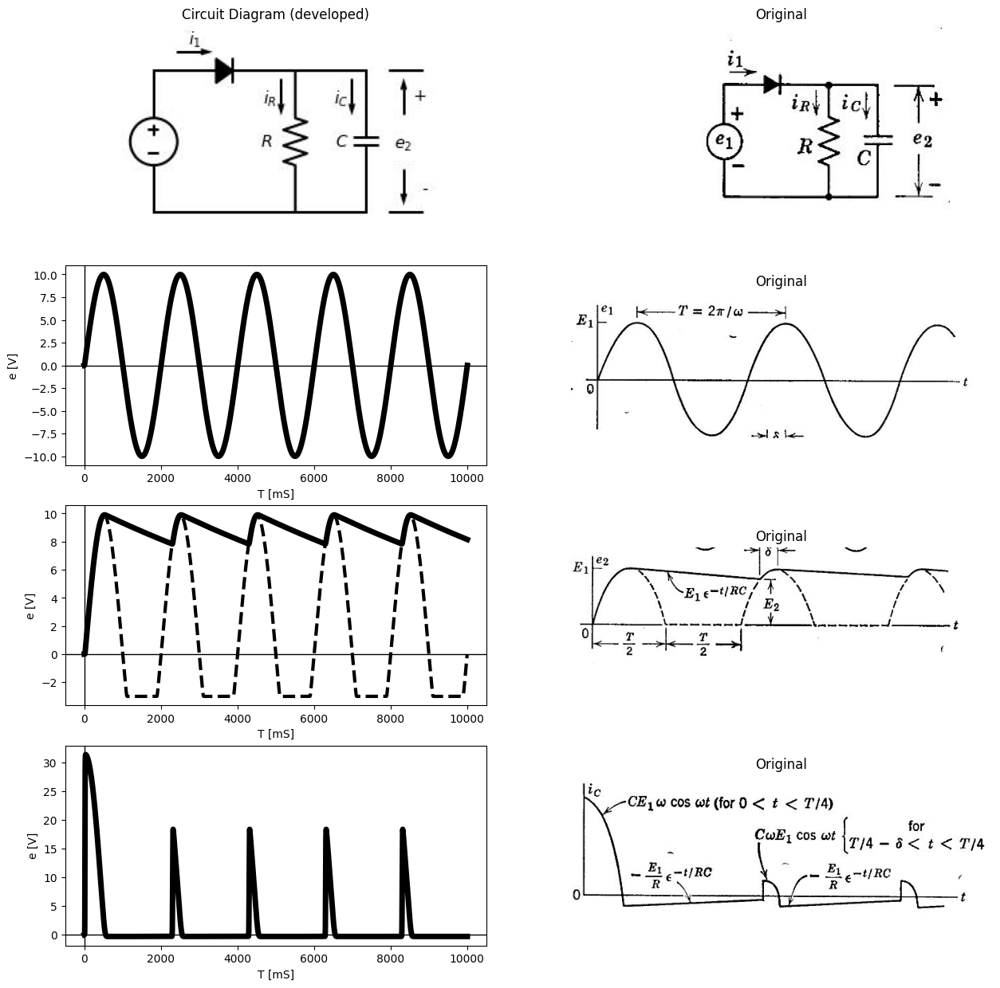

In [27]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up()
d += (D := elm.Diode(fill=True)).right()   
d += (R1:= elm.Resistor().down().label('$R$' , 'bot', ofst=-1))
d+= elm.Line().left().length(3) 
d+= elm.Line().right().length(1.5).at(N.end) 
d += (C1:= elm.Capacitor().down().label('$C$').at((4.5,3)))
d+= elm.Line().left().length(2).at((C1.end))
d += elm.Arrow().right().at((0.5, 3.4)).length(0.75).label('$i_1$', 'bottom', ofst=-0.5).color('black') 
d += elm.Arrow().down().at((2.7, 2.8)).length(0.75).label('$i_R$', 'bottom', ofst=-0.4).color('black')
d += elm.Arrow().down().at((4.2, 2.8)).length(0.75).label('$i_C$', 'bottom', ofst=-0.4).color('black')
d += elm.Arrow().down().at((5.3, 0.9)).length(0.75).color('black').label('-', ofst=-0.5  )
d += elm.Arrow().up().at((5.3, 2.1)).length(0.75).label('$e_2$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.5 ) 
d += elm.Line().right().length(0.7).at((5, 0))
d += elm.Line().right().length(0.7).at((5, 3))
d.save('Drawings/4-2a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-2a.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-2a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 1@u_Ohm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['1'],'black',linewidth=5)
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-2b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2'],'black',linewidth=5)
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
#circuit.C(1, '2',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2'],'black',linewidth=3,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-2c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot( u_mA(-analysis.V1),'black',linewidth=5)
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-2d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

In [1]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(C=widgets.IntSlider(min=.1, max=50, step=1, value=20))
def response(C=20@u_uF):
    rcParams['font.weight'] = 'bold'
    figure, ax1, = plt.subplots(figsize=(15, 5))

    circuit = Circuit('v-i curve')
    circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
    Vi = circuit.V('i', '1', circuit.gnd, 1@u_V)
    circuit.SinusoidalVoltageSource(1, '1', '2', amplitude=20@u_V)
    circuit.D(1, '2','3' , model = 'BAV21')
    circuit.R(1, '3', circuit.gnd, 10@u_kOhm)
    circuit.C(1, '3', circuit.gnd, C@u_uF)
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.dc(Vi=slice(-10,50, 0.1))
    analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
    ax1.plot(analysis['3'],'purple',linewidth=5)  
    ax1.plot(analysis['2'],'black',linewidth=2)
    #ax1.set_ylim(-20, 100)
    ax1.set_xlabel('T [s]')
    ax1.set_ylabel('V [v]')
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.tight_layout()
    plt.show()

    

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=20, description='C', max=50), Output()), _dom_classes=('widget-interact'…

D-C output = $e ̅ $ =$E_1$-$\frac{∆e_2}{2}$ = $\frac {1}{2}$($E_1$-$E_2$)= $E_1$[ 1-$\frac{T}{2RC}$ ]


Rectification efficiency = $η$ = $\frac {d-c output}{peak a-c input}$ = 1- $\frac {T}{2RC}$


Per-unit ripple = $\frac {E1 - E2}{e ̅ }$ ≈ $\frac {T}{RC}$


Fundamental ripple frequency = $ω$

### Fig.4.2 Basic rectifier circuit with smoothing capacitor

eliminates the need for solving a transcendental equation to find $δ$, and yields adequate accuracy for most purposes.
If the values of $R$ and $C$ are chosen so that $RC$ >>$T$, the exponential capacitor-discharge curve can be approximated by a linear relation that matches the initial slope.  Using these two approximations, we find that

$E_2$=$E_1$(1-$T$/$RC$) (4.1)

The ripple is thus a sawtooth voltage with a peak-to-peak amplitude


Δ$e_2$=$E_1$ $T$/$RC$   (4.2)

The average value of ct or the d-c voltage is


$e_2$=$E_1$-Δ$e_2$/2= $E_1$(1-$T$/2$RC$)  (4.3)


and the per-unit ripple is


$E_1$-$E_2$/$e_2$ ≈ $T$ /$RC$


The rectification efficiency ($η$) may be defined as the d-c output divided by the peak value of the a-c input ($E_1$). In terms of the input angular frequency ($w$= 2$πf$), it is apparent that the condition for small values of ripple and maximum efficiency will be $wRC$ >> 1.  In the limit the d-c output becomes equal to the peak value of the a-c input, and the circuit becomes a $perfect peo£ detector$.
An alternative approach to the calculation of the ripple voltage is based on the fact that the output voltage is very nearly constant and approximately equal to $E_1$ the peak value of the input voltage. The current through $R$, very nearly constant at $E_1$ /$R$, removes a total charge


Δ$Q$≈$E_1$($T$-$δ$)/2 ≈ $E_1$ $T$ / $R$



from the capacitor when the diode is off. When the capacitor voltage has reached a steady-state value, the charge added to the capacitor during the interval $δ$ in each cycle must equal the charge lost through $R$ during the remainder of each cycle. In order to add a given amount of charge ΔQ to the capacitor, the voltage must change in accordance with the relation Δ$Q$ = $C$Δ$e_2$. Substituting for Δ$Q$ in Eq. 4.5 leads to the same value of peak-to-peak ripple voltage obtained by the previous method (Eq. 4.2).

The results of Fig. 4.2 are substantially unchanged if a diode with nonzero forward and finite back resistance is substituted for the ideal diode, provided that the forward resistance is small, and the back resistance large, compared with the load resistance $R$.

Rectifiers intended for power applications cannot always be operated with a very large value of $R$.  With lower values of load resistance, the d-c output voltage drops further from the peak a-c input voltage and ripple voltage increases. Then a more elaborate smoothing circuit must be used in order to maintain low output ripple and good voltage regulation.

## 4.4	Rectifier Circuit with d-c and a-c Input Voltages

The analysis of nonlinear circuits with both a d-c source and an a-c source simultaneously applied is a problem of general interest. Whereas
the $individual sources$ can be considered separately in linear circuit analysis, and the solution obtained by superposition, the $total applied voltage$ must be considered (at least initially) in nonlinear or piecewise- linear circuits. The rectifier circuit under consideration will illustrate this fact.

Text(0.5, 1.0, 'Original')

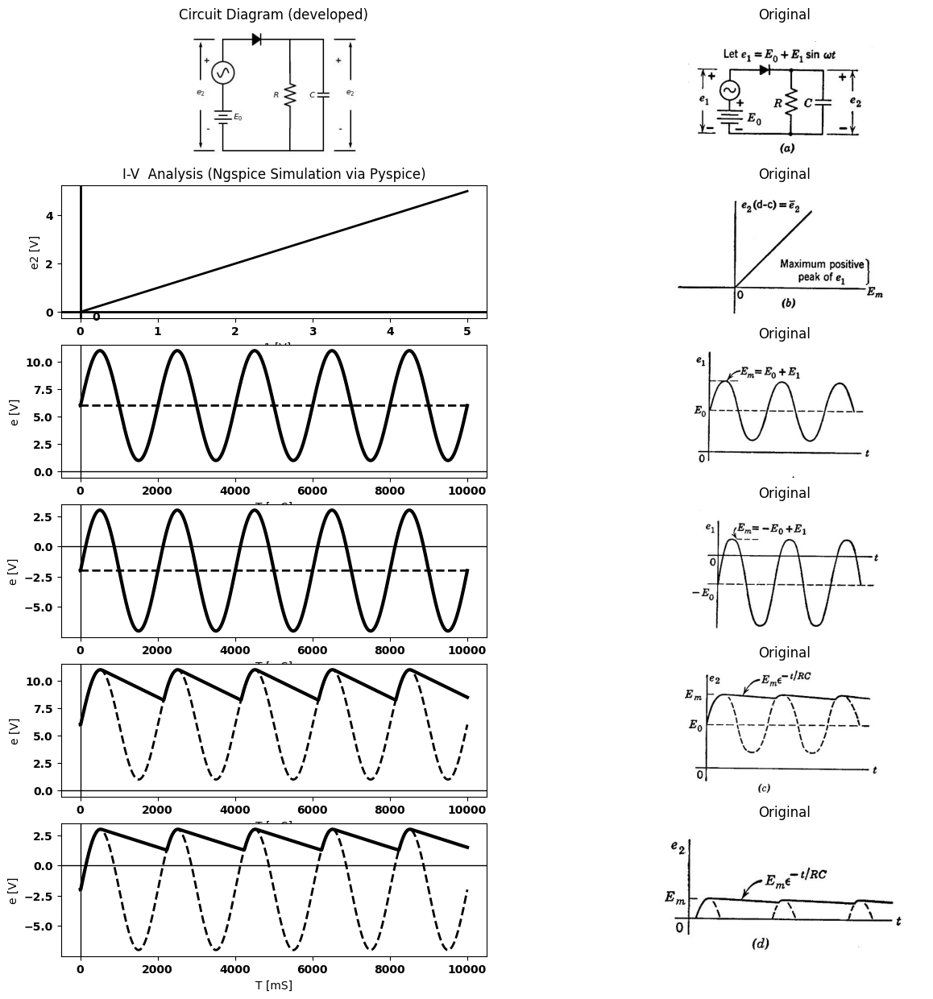

In [55]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceSin().up()
d += elm.Battery().down().at((0,1)).label('$E_0$','bottom' )
d += (D := elm.Diode(fill=True)).right().at((0,3))  
d += (R1:= elm.Resistor().down().label('$R$' , 'bot', ofst=-1).at((3,2)))
d+= elm.Line().right().length(4.5).at((0,-2))  
d+= elm.Line().down().length(1.5).at((D.end))
d+= elm.Line().right().length(1.5).at((D.end))
d+= elm.Line().up().length(1).at((C1.start))
d += (C1:= elm.Capacitor().down().label('$C$').at((4.5,2)))
d+= elm.Line().down().length(1).at((R1.end))
d+= elm.Line().down().length(1).at((C1.end))
d += elm.Arrow().down().at((5.7, -.2)).length(1.7).color('black').label('-', ofst=0.4  )
d += elm.Arrow().up().at((5.7, 1.2)).length(1.7).label('$e_2$', 'right', ofst=-2.5).color('black').label('+', ofst=0.4 ) 
d += elm.Line().right().length(0.9).at((5, 3))
d += elm.Line().right().length(0.9).at((5, -2)) 
d += elm.Arrow().down().at((-1, -.2)).length(1.7).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((-1, 1.2)).length(1.7).label('$e_2$', 'right', ofst=-2.5).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((-1.3, 3))
d += elm.Line().right().length(0.9).at((-1.3, -2))
d.save('Drawings/4-3a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-3a.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1 ,'1', circuit.gnd, 1@u_Ohm )
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 5, 0.1))

axs[1, 0].plot(analysis['1'], u_A(-analysis.Vi),'black',linewidth=2)
axs[1, 0].set_title('I-V  Analysis (Ngspice Simulation via Pyspice)')
axs[1, 0].set_ylabel('e2 [V]')
axs[1, 0].set_xlabel('e1 [V]')
axs[1, 0].text( 0.2, -0.2, '0', ha='center', va='center')

axs[1, 0].axhline(0, color='black', linewidth=2)
axs[1, 0].axvline(0, color='black', linewidth=2)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 6@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 6@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 30@u_kOhm)
circuit.C(1, '3',circuit.gnd, 60@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[4,0].plot(analysis['3'],'black',linewidth=3)
axs[4,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('e [V]')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3e.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 10@u_kOhm)
circuit.C(1, '3',circuit.gnd, 100@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[5,0].plot(analysis['3'],'black',linewidth=3)
axs[5,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[5,0].set_xlabel('T [mS]')
axs[5,0].set_ylabel('e [V]')
axs[5,0].axhline(0, color='black', linewidth=1)
axs[5,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-3f.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')

In [2]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(C=widgets.IntSlider(min=.1, max=50, step=1, value=20))
def response(C=20@u_uF):
    rcParams['font.weight'] = 'bold'
    figure, ax1, = plt.subplots(figsize=(15, 5))

    circuit = Circuit('v-i curve')
    circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
    Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
    circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=20@u_V)
    circuit.D(1, '2','3' , model = 'BAV21')
    circuit.R(1, '3', circuit.gnd, 1@u_kOhm)
    #circuit.R(2, '2', '3', 0@u_kOhm)
    circuit.C(1, '3', circuit.gnd, C@u_uF)
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    #analysis = simulator.dc(Vi=slice(-10,50, 0.1))
    analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
    ax1.plot(analysis['3'],'black',linewidth=5)  
    ax1.plot(analysis['2'],'black',linewidth=2,linestyle='--')
    #ax1.set_ylim(-20, 100)
    ax1.set_xlabel('T [s]')
    ax1.set_ylabel('V [v]')
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    plt.tight_layout()
    plt.show()

    

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=20, description='C', max=50), Output()), _dom_classes=('widget-interact'…

### Fig.4.3. Rectifier Circuit with d-c and a-c Input Voltages

The circuit shown in Fig. 4.3(o) is identical to the one in Fig. 4.2, except that the input voltage now has both a d-c and an a-c component. The a-c voltage waveform is again assumed to begin at $t$ = 0. From the considerations of the preceding article, the transfer curve of Fig. 4.3($b$) can be deduced. The unity slope shown for $e_2$ (the d-c component of $e_2$) vs. the positive peak of $e_1$ is an idealization which assumes negligibly small ripple, source resistance, and diode forward resistance. The output waveforms for particular input combinations of a-c and d-c components follow directly from this transfer curve. Two examples are shown in Flg. 4.3($c$) and ($d$).
In Fig. 4.3($c$), the d-c source $E_0$ exceeds the magnitude $E_1$ arid is so


polarized that e is never negative. Thus the resistive circuit operates entirely on the unity slope portion of its transfer curve. In the absence of the capacitor, the input sine wave would be reproduced at the output, as shown by the dotted curve in Fig. 4.3($c$). With the capacitor con- nected, the output voltage is nearly constant at $E_m$. Here $E_0$ may be assumed to apply a static charge to the capacitor, after which the circuit behaves like the one in Fig. 4.2. The reference level for the sine wave is +$E_0$ instead of zero.
With the polarity of <o reversed, the waveforms are as shown in Fig. 4.3 ($d$). The source A biases the sine wave negatively so that only the positive peaks cause diode conduction in the resistive case. Obviously,
if $E_0$ exceeds $E_1$ in magnitude, the diode will never conduct and the output will be zero. The capacitor smooths the waveform and produces a d-c voltage near the maximum positive peak $E_m$.


## 4.5 The Clamping Circuit

Suppose the voltage across the diode of the basic rectifier circuit is considered to be the output of the circuit. The circuit is rearranged as shown in Fig. 4.4($a$), to call attention to this fact, but it is still the same circuit. Results obtained previously can therefore be used directly. The waveform of diode voltage was not plotted in the previous figures, but it is readily deduced as the difference between the input voltage and the voltage across load resistance and capacitor. The voltage wave- forms for the circuit are shown in Fig. 4.4($a$), assuming that the sinus- oidal input voltage begins at $t$ = 0, and that the capacitor has no initial charge.

The output waveform consists of the input waveform pushed up by the d-c voltage across the capacitor. Since this voltage is approximately equal to the peak value of the input voltage ($E_1$), the $negative$ peak of the output waveform is held or clamped at reference level (zero potential). With an ideal rectifier in the circuit, e cannot be negative by even a small amount. Conduction of the diode immediately charges the capacitor to the value required to maintain the output voltage at zero as et goes to its negative peaks. With an actual diode in the circuit, the output voltage is very slightly negative when the capacitor is being recharged.
Reversing the direction of the diode reverses the polarity of the charge on the capacitor and depresses the output waveform by an amount approximately equal to $E_1$. In this case, Fig. 4.4($b$), the $positive$ peak of the output waveform is clamped to the reference potential.

Text(0.5, 1.0, 'Original')

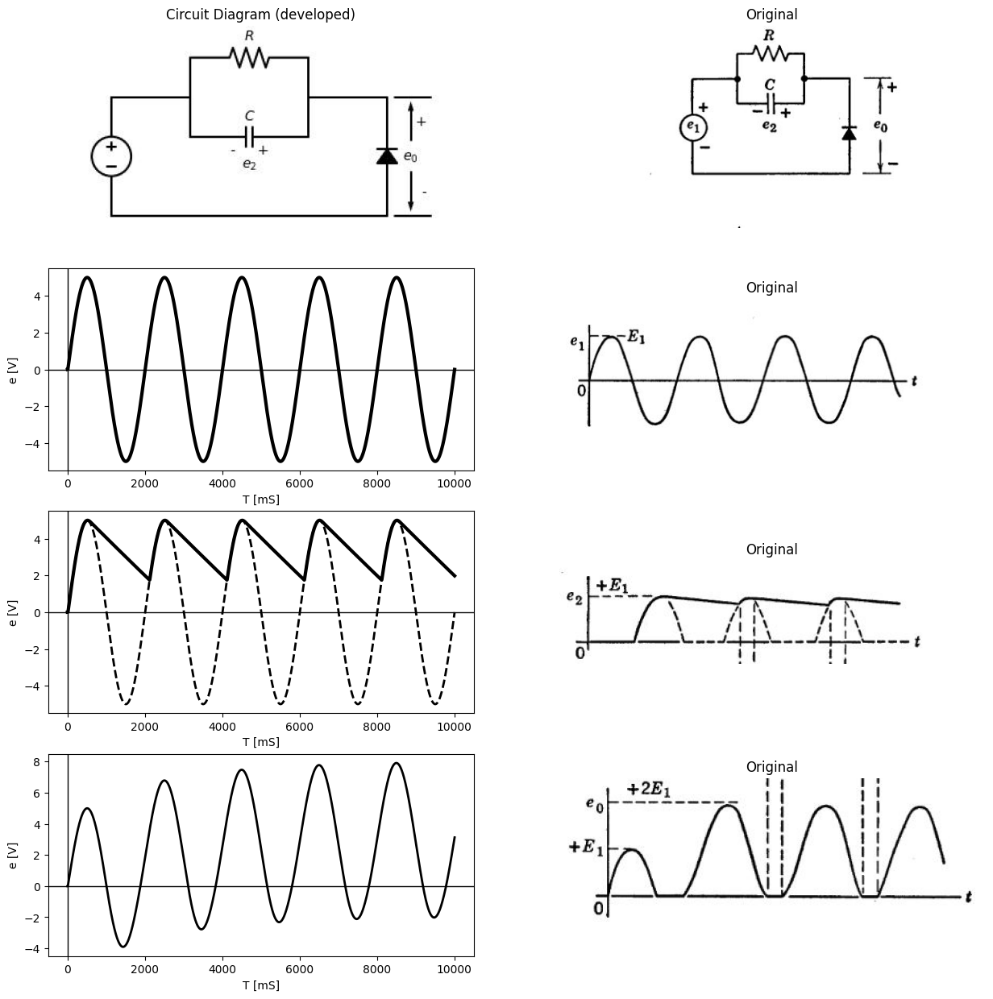

In [29]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up()
d+= elm.Line().right().length(2)
d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += (C1:= elm.Capacitor().right().label('$C$').at((2,2))).label('$e_2$', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
d+= elm.Line().up().length(2).at((C1.start))
d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).up().at((7,0))  
d+= elm.Line().left().length(7).at((N.start))
d+= elm.Line().left().length(2).at((N.end))
d += elm.Arrow().down().at((7.6, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((7.6, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.2, 3))
d += elm.Line().right().length(0.9).at((7.2,0))
d.save('Drawings/4-4a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-4a.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2',circuit.gnd, model = 'BAV21')
circuit.R(1, '1','2', 10@u_kOhm)
circuit.C(1, '1','2', 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1,circuit.gnd, '2', model = 'BAV21')
circuit.R(1, '1','2', .10@u_Ohm)
circuit.C(1, '1','2', 1@u_F)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
#axs[3,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['2'],'black',linewidth=2,linestyle='-')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

In [1]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
from matplotlib import rcParams
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
figure = plt.figure(figsize=(15, 10))


#@interact(Mode1=(True) , Mode2=(True),  Mode3=(True))
@interact(C=widgets.IntSlider(min=.1, max=50, step=1, value=20))
def response(C=20@u_uF):
    rcParams['font.weight'] = 'bold'
    figure, ax1, = plt.subplots(figsize=(15, 5))

    circuit = Circuit('v-i curve')
    circuit.model('BAV21','D' ,IS = 300@u_uA , N = 1.906  ,BV = 8100@u_V, IBV = 0.0001@u_V,  VJ = 20@u_V ,CJO = 7.048E-13 ,RS = 1@u_Ohm ,TT = 3.48E-9)
    Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
    circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=20@u_V)
    circuit.D(1, '2','3' , model = 'BAV21')
    circuit.R(1, '3', circuit.gnd, 1@u_kOhm)
    #circuit.R(2, '2', '3', 0@u_kOhm)
    circuit.C(1, '3', circuit.gnd, C@u_uF)
    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    #analysis = simulator.dc(Vi=slice(-10,50, 0.1))
    analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
    ax1.plot(analysis['3'],'black',linewidth=5)  
    #ax1.plot(analysis['2'],'black',linewidth=2,linestyle='--')
    #ax1.set_ylim(-20, 100)
    ax1.set_xlabel('T [s]')
    ax1.set_ylabel('V [v]')
    plt.axhline(0, color='black', linewidth=1)
    plt.axvline(0, color='black', linewidth=1)
    
    circuit = Circuit('inpu')
    circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =1@u_Ohm )
    circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=20@u_V)
    Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
    circuit.D(2, '2','3', model = 'BAV21')
    circuit.R(2, '3',circuit.gnd, 50@u_Ohm)

    simulator = circuit.simulator(temperature=25, nominal_temperature=25)
    analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
    ax1.plot(analysis['3'],'black',linewidth=3,linestyle='--')

    ax1.axhline(0, color='black', linewidth=1)
    ax1.axvline(0, color='black', linewidth=1)
    

    

<Figure size 1500x1000 with 0 Axes>

interactive(children=(IntSlider(value=20, description='C', max=50), Output()), _dom_classes=('widget-interact'…

Text(0.5, 1.0, 'Original')

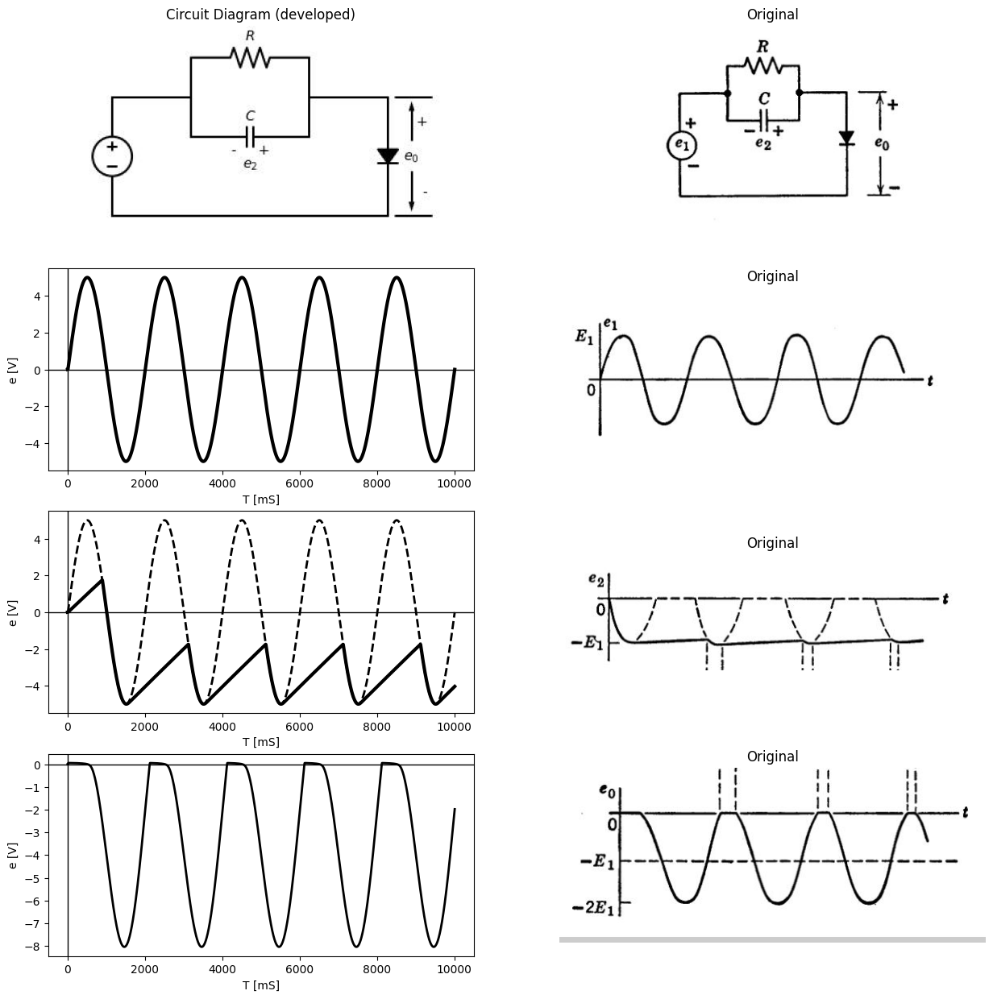

In [33]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up()
d+= elm.Line().right().length(2)
d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += (C1:= elm.Capacitor().right().label('$C$').at((2,2))).label('$e_2$', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
d+= elm.Line().up().length(2).at((C1.start))
d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).down().at((7,3))  
d+= elm.Line().left().length(2).at((N.start))
d+= elm.Line().left().length(7).at((N.end))
d += elm.Arrow().down().at((7.6, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((7.6, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.2, 3))
d += elm.Line().right().length(0.9).at((7.2,0)) 
d.save('Drawings/4-4a1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-4a1.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4e.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1,circuit.gnd, '2', model = 'BAV21')
circuit.R(1, '1','2', 10@u_kOhm)
circuit.C(1, '1','2', 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4g.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2',circuit.gnd, model = 'BAV21')
circuit.R(1, '1','2', 10@u_kOhm)
circuit.C(1, '1','2', 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
#axs[3,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['2'],'black',linewidth=2,linestyle='-')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4h.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig.4.4. Clamping circuit

The reference potential can be shifted up or down by putting a d-c source in series with the diode, as shown in Fig. 4.5($a$) and ($b$). The voltage level at which the output waveform is held depends on the

Text(0.5, 1.0, 'Original')

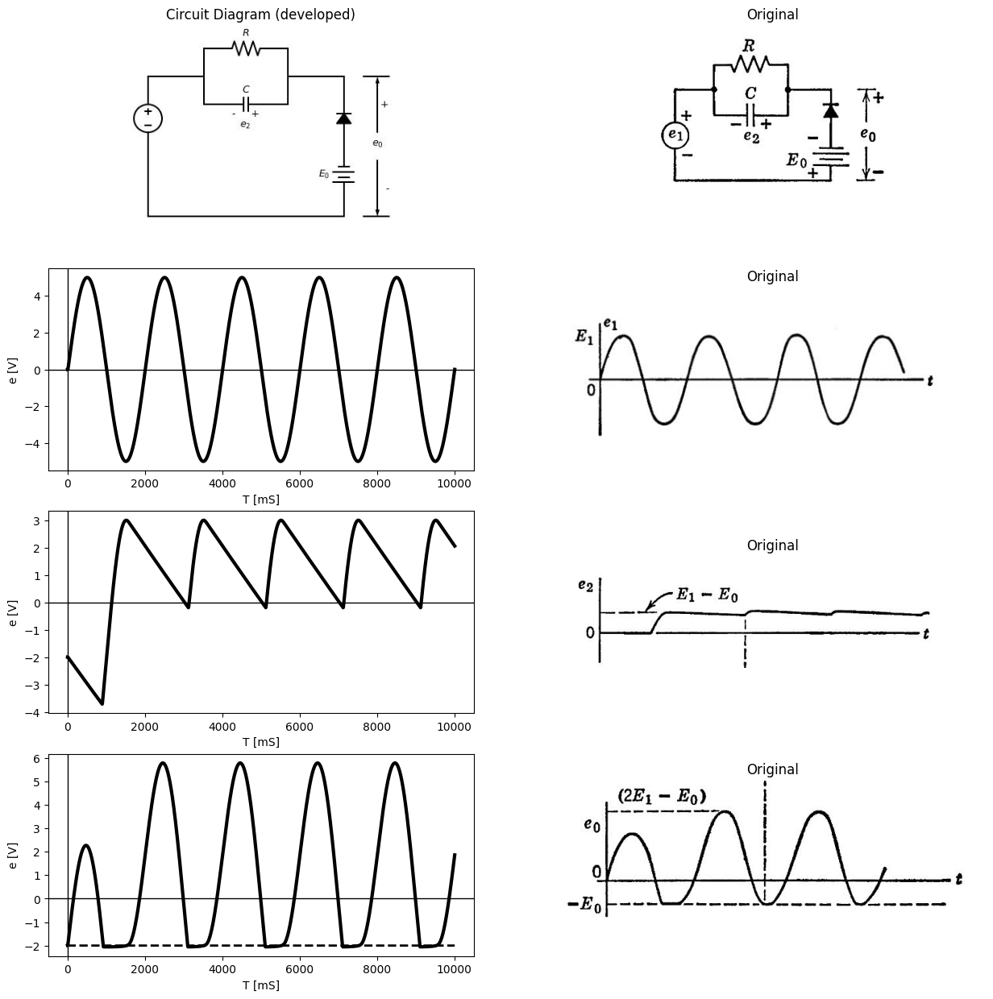

In [51]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up()
d+= elm.Line().right().length(2)
d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += elm.Battery().down().at((7,+1)).label('$E_0$ ','top' ).reverse()
d += (C1:= elm.Capacitor().right().label('$C$').at((2,2))).label('$e_2$ ', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
d+= elm.Line().up().length(2).at((C1.start))
d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).up().at((7,0))  
d+= elm.Line().up().length(2).at((0,-2))
d+= elm.Line().left().length(7).at((7,-2))
d+= elm.Line().left().length(2).at((N.end))
d += elm.Arrow().down().at((8.2, 0)).length(2).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((8.2, 1)).length(2).label('$e_0$', 'right', ofst=-2.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.7, 3))
d += elm.Line().right().length(0.9).at((7.7,-2)) 
d.save('Drawings/4-5a1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-5a1.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
Vi = circuit.V('i', circuit.gnd, '3', 2@u_V)
circuit.D(1, '3','2', model = 'BAV21')
circuit.R(1, '1','2', 10@u_kOhm)
circuit.C(1, '1','2', 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2']-analysis['1'],'black',linewidth=3)
#axs[2,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
Vi = circuit.V('i', circuit.gnd, '3', 2@u_V)
circuit.D(1, '3','2', model = 'BAV21')
circuit.R(1, '1','2', 1@u_kOhm)
circuit.C(1, '1','2',50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['3'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

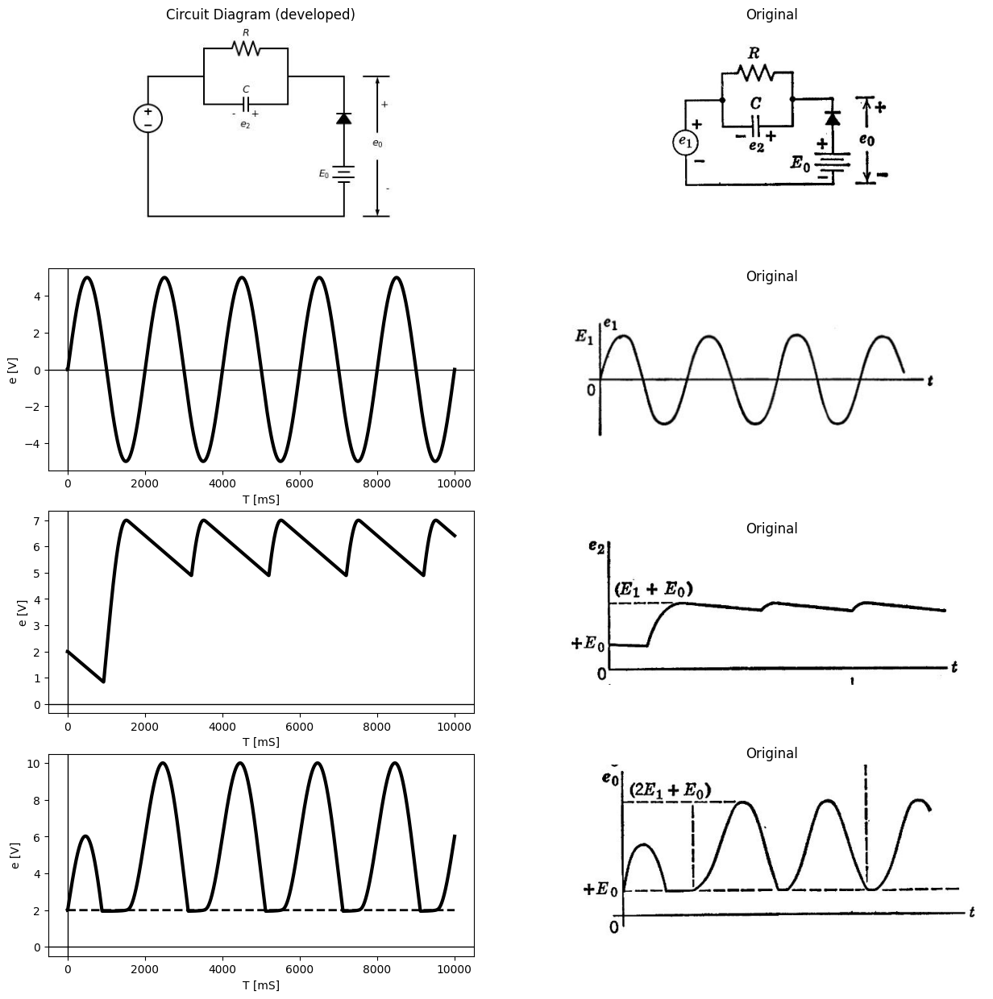

In [52]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up()
d+= elm.Line().right().length(2)
d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += elm.Battery().down().at((7,+1)).label('$E_0$ ','top' )
d += (C1:= elm.Capacitor().right().label('$C$').at((2,2))).label('$e_2$ ', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
d+= elm.Line().up().length(2).at((C1.start))
d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).up().at((7,0))  
d+= elm.Line().up().length(2).at((0,-2))
d+= elm.Line().left().length(7).at((7,-2))
d+= elm.Line().left().length(2).at((N.end))
d += elm.Arrow().down().at((8.2, 0)).length(2).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((8.2, 1)).length(2).label('$e_0$', 'right', ofst=-2.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.7, 3))
d += elm.Line().right().length(0.9).at((7.7,-2)) 
d.save('Drawings/4-5a2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-5a2.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5d.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
Vi = circuit.V('i', '3', circuit.gnd, 2@u_V)
circuit.D(1, '3','2', model = 'BAV21')
circuit.R(1, '1','2', 40@u_kOhm)
circuit.C(1, '1','2', 80@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2']-analysis['1'],'black',linewidth=3)
#axs[2,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5e.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
Vi = circuit.V('i', '3', circuit.gnd, 2@u_V)
circuit.D(1, '3','2', model = 'BAV21')
circuit.R(1, '1','2', 10@u_kOhm)
circuit.C(1, '1','2',50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['3'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5f.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

## Fig.4.5.  Clamper with d-c source included.

magnitude and polarity of the d-c. However, once equilibrium has been established, the shape of the output waveform is the same as before.
The circuit under discussion is commonly called a clamping circuit or clamper, since it holds one peak of a waveform at a fixed potential.


Such descriptive names are frequently used because they are helpful in discussing the functional behavior of complex electronic systems. However, descriptive names may obscure basic similarities. Recog-

Text(0.5, 1.0, 'Original')

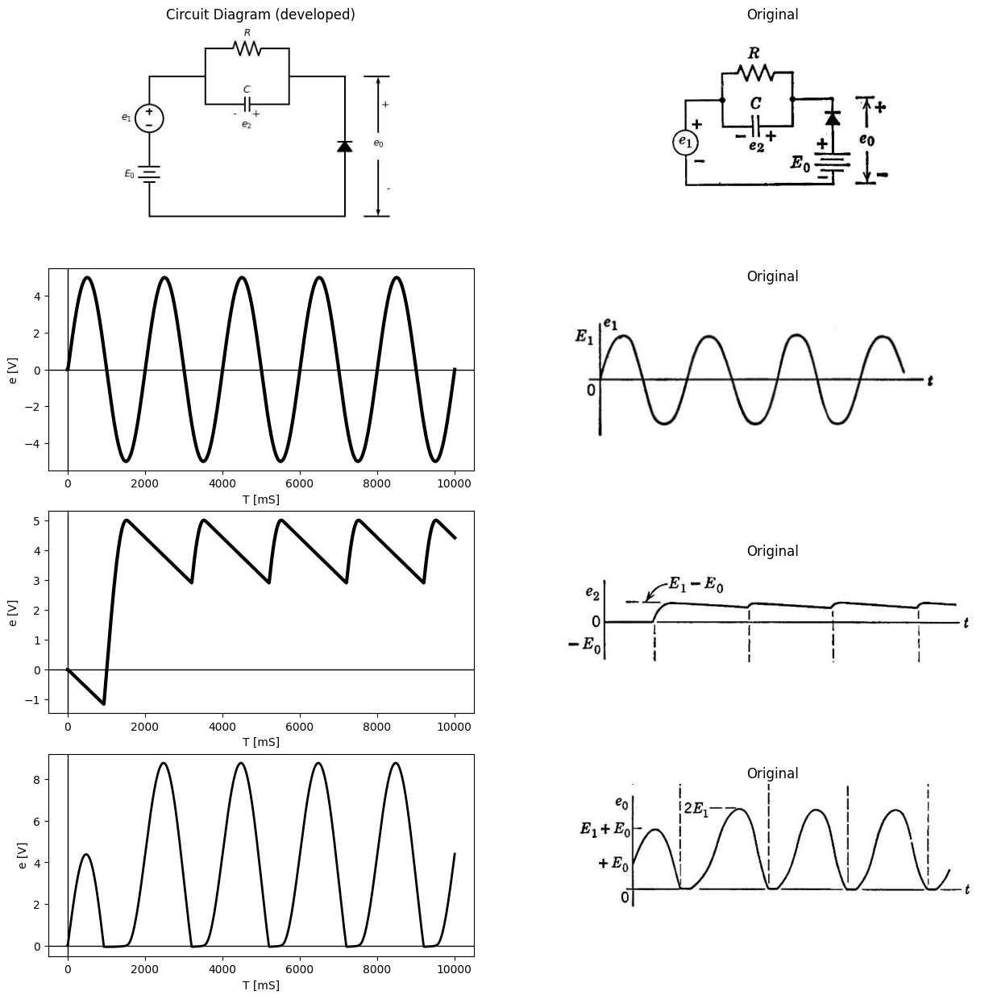

In [61]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up().label('$e_1$ ','top' )
d+= elm.Line().right().length(2)
d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += elm.Battery().down().at((0,+1)).label('$E_0$ ','top' )
d += (C1:= elm.Capacitor().right().label('$C$').at((2,2))).label('$e_2$ ', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
d+= elm.Line().up().length(2).at((C1.start))
d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).up().at((7,-1))  
#d+= elm.Line().up().length(2).at((0,-2))
d+= elm.Line().left().length(7).at((7,-2))
d+= elm.Line().up().length(1).at((N.end))
d+= elm.Line().down().length(1).at((N.start))
d+= elm.Line().left().length(2).at((7,3))
d += elm.Arrow().down().at((8.2, 0)).length(2).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((8.2, 1)).length(2).label('$e_0$', 'right', ofst=-2.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.7, 3))
d += elm.Line().right().length(0.9).at((7.7,-2)) 
d.save('Drawings/4-6a2.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-6a2.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-5d.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2','1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '2','3', 40@u_kOhm)
circuit.C(1, '2','3', 80@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
#axs[2,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-6b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2','1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '2','3', 40@u_kOhm)
circuit.C(1, '2','3', 80@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
#axs[3,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['3'],'black',linewidth=2,linestyle='-')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-6c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

Text(0.5, 1.0, 'Original')

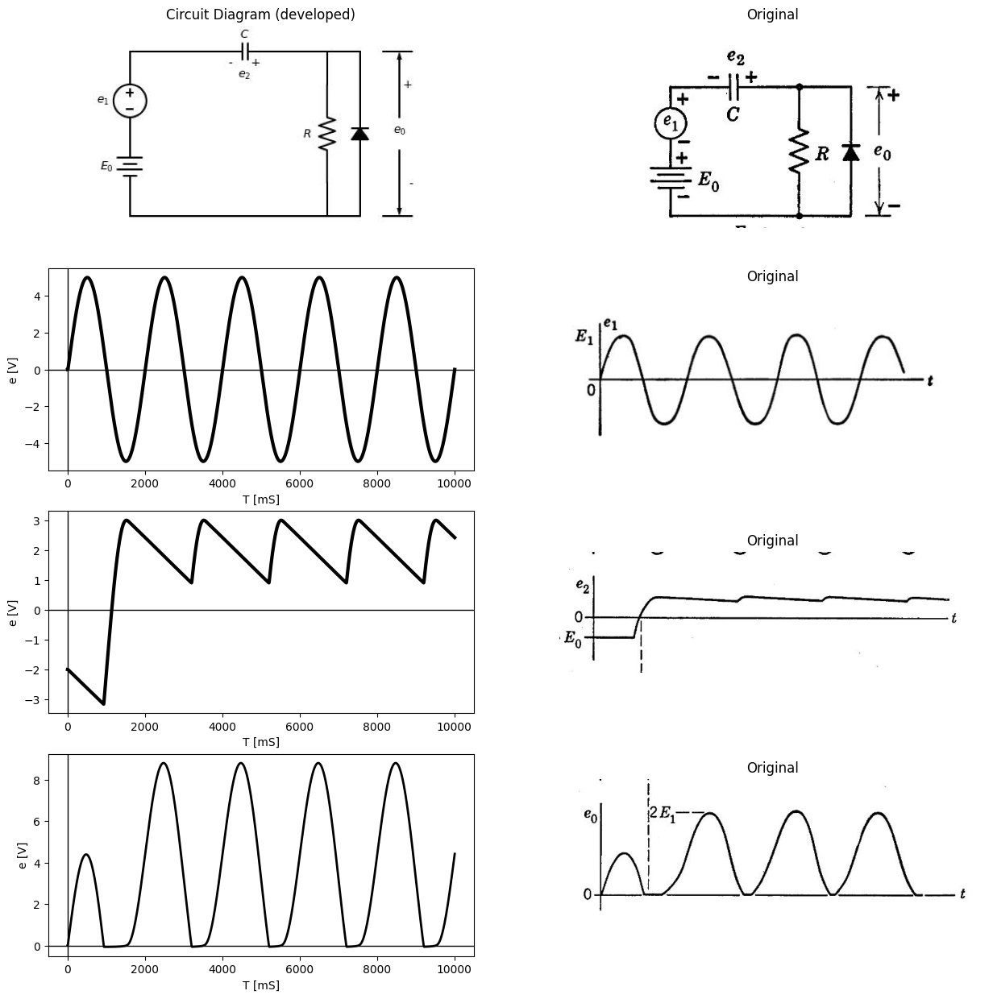

In [66]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up().label('$e_1$ ','top' )
d+= (l1:=elm.Line().right().length(2))
#d += (R1:= elm.Resistor().right().label('$R$' , 'bot', ofst=-1).at((2,4)))
d += elm.Battery().down().at((0,+1)).label('$E_0$ ','top' )
d += (C1:= elm.Capacitor().right().label('$C$').at(l1.end)).label('$e_2$ ', 'bottom', ofst=0.3).label('-     +', 'bottom', ofst=-0.1)
#d+= elm.Line().up().length(2).at((C1.start))
#d+= elm.Line().up().length(2).at((C1.end))
d += (N := elm.Diode(fill=True)).up().at((7,-1))  
d+= elm.Line().left().length(7).at((7,-2))
d+= elm.Line().up().length(1).at((N.end))
d+= elm.Line().down().length(1).at((N.start))
d+= elm.Line().left().length(2).at((7,3))
d += elm.Arrow().down().at((8.2, 0)).length(2).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((8.2, 1)).length(2).label('$e_0$', 'right', ofst=-2.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((7.7, 3))
d += elm.Line().right().length(0.9).at((7.7,-2)) 
d += (R2:= elm.Resistor().down().label('$R$' , 'bot', ofst=-1).at((6,2)))
d+= elm.Line().up().length(1).at((R2.start))
d+= elm.Line().down().length(1).at((R2.end))
d.save('Drawings/4-6a3.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-6a3.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-6d.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2','1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 40@u_kOhm)
circuit.C(1, '2','3', 80@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
#axs[2,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-6e.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2','1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 40@u_kOhm)
circuit.C(1, '2','3', 80@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
#axs[3,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
axs[3,0].plot(analysis['3'],'black',linewidth=2,linestyle='-')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-6f.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig.4.6. Variations of clamping circuit

nition of basic similarities between circuits, as in the case of the clamper and the basic rectifier, leads to a better understanding of both circuits and also saves analysis time. To emphasize this point, two other variations of the Hamper circuit are shown in Fig. 4.6. The circuit shown in Fig. 4.6($a$) has a d-S source in s9ries with the input sinusoid, a trivial variation of Fig. 4.5($a$). Obviously the output is clamped at zero, and the charge on the capacitor takes up the effect of the d-c source. The circuit shown in Fig. 4.6($b$) is a-c coupled. Since the capacitor blocks direct current, the d-c source cannot influence the output after a charge has been established.

## 4.6	The Voltage Doubler

The clamper of Fig. 4.6($b$) yields an a-c output voltage that reaches a maximum value very nearly equal to the peak-to-peak value of the a-c input. The basic rectifier circuit, Fig. 4.3, produces a d-c output nearly equal to the maximum peak of the input voltage (a-c plus d-c). If the rectifier circuit is connected to the output of the clamper, a d-c output voltage is obtained which is nearly equal to the peak-to-peak value of the a-c input. Since this is nearly twice the d-c voltage output from a single-diode rectifier and smoothing capacitor, the circuit is called a voltage doubler.

The voltage-doubler circuit shown in Fig. 4.7 is seen to consist of a Hamper followed by a basic rectifier circuit with a smoothing capacitor $C_2$.  The resistance $R_1$fit associated with the clamper is usually omitted from the complete circuit, since it tends to reduce the voltage across $C_1$. The waveforms shown in Fig. 4.7 depict the steady-state operation of the circuit. It is assumed that the rectifier circuit and smoothing capacitor $C_2$ constitute insufficient load to affect the operation of the clamper circuit. Thus voltage $e_0$$_1$ is assumed to be a sine wave of peak amplitude $E_1$ added to a d-c component of value $E_1$ as in Fig. 4.6(b). The rectifier circuit, with cor as an input, gives a nearly constant d-c voltage $e_2$, with a per-unit ripple equal to $T$/$R_2$ $C_2$.


If the load resistance $R_2$ in Fig. 4.7 corresponds to the high resistance of an ordinary d-c voltmeter, * the combination constitutes an a-c volt- meter which reads the peak-to-peak value of the a-c input wave directly and linearly in terms of the d-c output voltage.


One terminal of the input source $e_1$ in Fig. 4.7 is common to one terminal of the output voltage $e_0$ Such a common terminal or node is usually very desirable in a circuit, since it permits the establishment of a common reference potential.


By way of contrast, a variation of the voltage-doubler circuit is shown in Fig. 4.8. In this case there is no terminal common to the a-c input


###### * For example, a d-c milliammeter (0 to 1 ma) with a series resistance of 1000 ohms per volt of d-c voltage to be measured; or a 0 to 50 d-c microammeter in series with 20,000 ohms per volt.

Text(0.5, 1.0, 'Original')

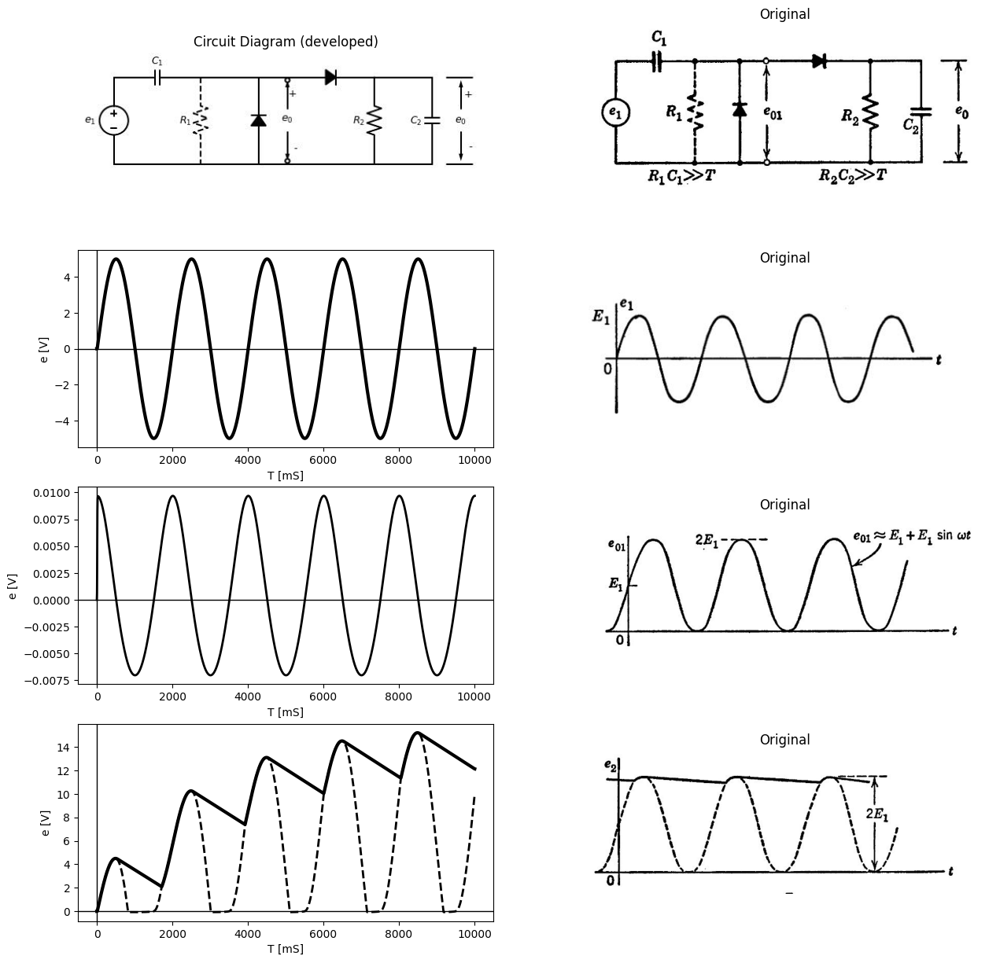

In [90]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up().label('$e_1$ ','top' )
d += (C1:= elm.Capacitor().right().label('$C_1$').at((0,3)))
d += (R1:= elm.Resistor().down().label('$R_1$' , 'bot', ofst=-1).at((3,3)).linestyle('--'))
d+= (N1 := elm.Diode(fill=True)).up().at((5,0))  
d+= (N2 := elm.Diode(fill=True)).right().at((6,3))
d += (R1:= elm.Resistor().down().label('$R_2$' , 'bot', ofst=-1).at((N2.end)))
d += (C2:= elm.Capacitor().down().label('$C_2$').at((11,3)))
d+= elm.Line().left().length(3).at((N2.start))
d+= elm.Line().left().length(5).at((N1.start))
d+= elm.Line().left().length(2).at((C2.start))
d+= elm.Line().left().length(6).at((C2.end))
d += elm.Arrow().down().at((12, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((12, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ) 
d += elm.Line().right().length(0.9).at((11.5, 3))
d += elm.Line().right().length(0.9).at((11.5,0))
d += elm.Arrow().down().at((6, 1.1)).length(1).color('black').label('-', ofst=-0.4  ).dot(open=True)
d += elm.Arrow().up().at((6, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ).dot(open=True)
d.save('Drawings/4-7.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-7.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-7a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=10@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 2@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.D(2, '2','3', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 1@u_kOhm)
circuit.R(2, '3',circuit.gnd, 40@u_kOhm)
circuit.C(1, '1','2', 1@u_uF)
circuit.C(2, '3',circuit.gnd, 5@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
#axs[2,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['2'],'black',linewidth=2,linestyle='-')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-7b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=10@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 2@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.D(2, '2','3', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 40@u_kOhm)
circuit.R(2, '3',circuit.gnd, 40@u_kOhm)
circuit.C(1, '1','2', 50@u_uF)
circuit.C(2, '3',circuit.gnd, 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['3'],'black',linewidth=3)
axs[3,0].plot(analysis['2'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-7c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig.4.7.  Voltage doubler

source and the d-c output voltage. The circuit of Fig. 4.8 has a sym- metrical appearance, and if $C_a$ = $C_b$ , the usual case, the circuit is also electrically symmetrical. The d-c potential difference is the same between input terminal ($B$) and either output terminal. Since one diode conducts only on the positive peak of the a-c voltage, and the other conducts on the negative peak, input terminal {A} is alternately “connected” to the positive and negative output terminals. Thus $e_0$ has a magnitude approaching the peak-to-peak value of the input sine wave, but the output voltage relative to the input terminal $pB$) extends from +$E_1$ to -$E_1$

Text(0.5, 1.0, 'Original')

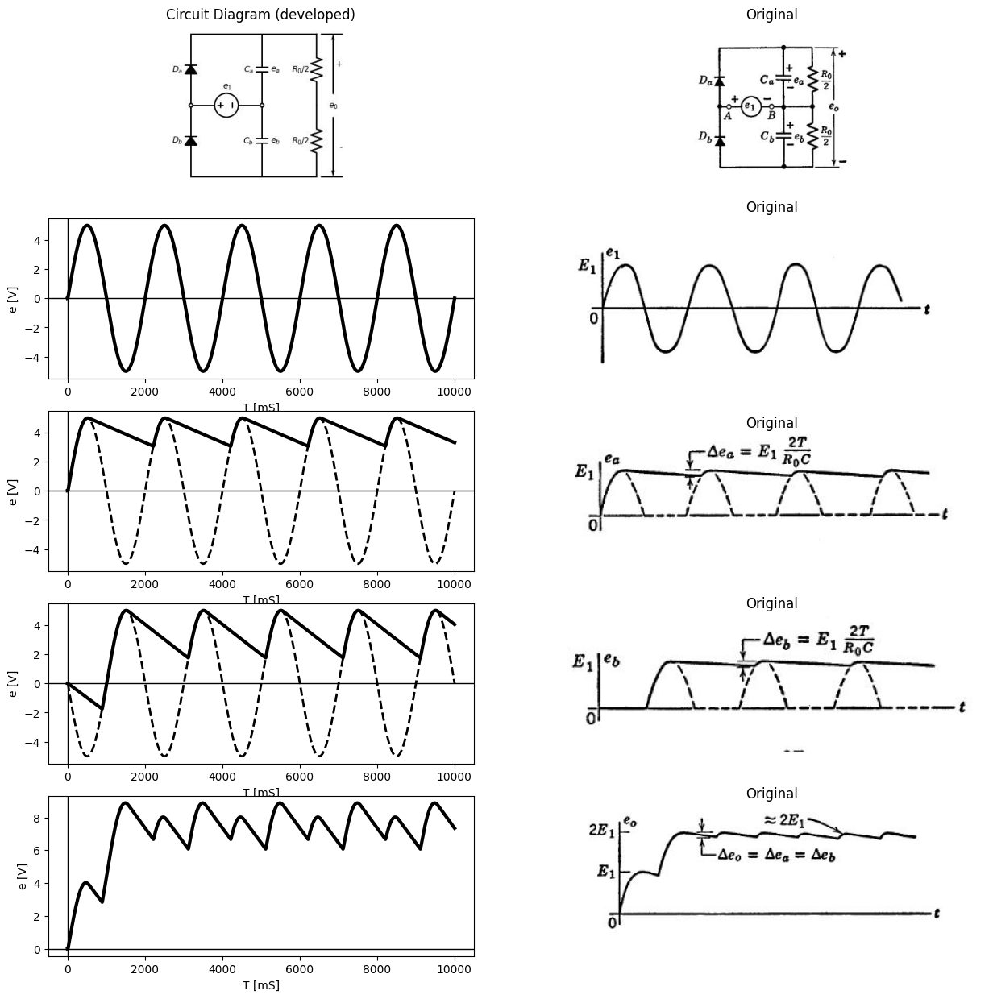

In [34]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d+= (N1 := elm.Diode(fill=True)).up().at((3,0)).label('$D_b$') .dot(open=True)
d+= (N2 := elm.Diode(fill=True)).up().at((N1.end)).label('$D_a$') 
d += elm.SourceV().right().label('$e_1$ ','top' ).at((N1.end)).reverse().dot(open=True)
d += (C1:= elm.Capacitor().up().label('$C_a$').at((6,3))).label('$e_a$' , 'bot', ofst=0.1)
d += (C2:= elm.Capacitor().down().label('$C_b$').at((6,3))).label('$e_b$' , 'bot', ofst=0.1)
d += (R1:= elm.Resistor().up().label('$R_0/2$' , 'bot', ofst=-1.3).at((8.3,3)))
d += (R2:= elm.Resistor().down().label('$R_0/2$' , 'bot', ofst=-1.3).at((8.3,3)))
d+= elm.Line().left().length(5.3).at((R1.end))
d+= elm.Line().left().length(5.3).at((R2.end))
d += elm.Line().right().length(0.9).at((8.5, 6))
d += elm.Line().right().length(0.9).at((8.5,0))
d += elm.Arrow().down().at((9, 2.5)).length(2.5).color('black').label('-', ofst=-0.4  )
d += elm.Arrow().up().at((9, 3.5)).length(2.5).label('$e_0$', 'right', ofst=-3.2).color('black').label('+', ofst=-0.4 )
d.save('Drawings/4-8.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-8.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-8.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-4f.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 90@u_uF)
circuit.D(2,'1', '3', model = 'BAV21')
circuit.R(2, '3',circuit.gnd, 10@u_kOhm)
circuit.C(2, '3',circuit.gnd, 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2'],'black',linewidth=3)
axs[2,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-8a.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 90@u_uF)
circuit.D(2,'3', '1', model = 'BAV21')
circuit.R(2, '3',circuit.gnd, 10@u_kOhm)
circuit.C(2, '3',circuit.gnd, 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(-analysis['3'],'black',linewidth=3)
axs[3,0].plot(-analysis['1'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-8b.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.R(1, '2',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 90@u_uF)
circuit.D(2,'3', '1', model = 'BAV21')
circuit.R(2, '3',circuit.gnd, 10@u_kOhm)
circuit.C(2, '3',circuit.gnd, 50@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[4,0].plot(analysis['2']-analysis['3'],'black',linewidth=3)
#axs[3,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('e [V]')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-8c.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

### Fig. 4.8.  Balanced voltage doubler.

The circuit consists of two basic rectifiers connected back to back. The sum of waveforms $e_a$ and ebyields the output waveform $e_0$ Because $e_a$and $e_b$ are “out of step” by half a cycle, the output ripple is the same as the ripple on either $e_a$ or $e_b$. The per-unit ripple is


$\frac {2E_1 .T/R_o.C}{2E_1}$ =$\frac {T}{R_o.C} $ 


identical to that obtained for the unbalanced doubler. However, the fundamental ripple frequency is twice the input frequency in this case, whereas in the circuit of Fig. 4.7 the ripple frequency is equal to the input frequency.

In [4]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode_1=(True),Mode_2=(True),Mode_3=(True))
def response( Mode_1=True,Mode_2=True,Mode_3=True):

    with schemdraw.Drawing() as d:
        if (Mode_1):
            d += elm.SourceV().up().label('$e_1$ ','top' )
            d += (C1:= elm.Capacitor().right().label('$C_1$').at((0,3)).label('+    $e_2$   -','bottom'))
    
            d+= (N1 := elm.Diode(fill=True)).up().at((3,0)).label('$D_1$') 
            d+= (N2 := elm.Diode(fill=True)).right().at((3,3)).label('$D_2$')
            d += (R:= elm.Resistor().down().label('$R$' , 'bot', ofst=-1).at((9,3)).linestyle('--'))
            d += (C2:= elm.Capacitor().down().label('$C_2$').at((6,3)))
            d+= elm.Line().left().length(3).at((N1.start))
            d+= elm.Line().left().length(3).at((C2.end))
            d += elm.Arrow().down().at((9.8, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
            d += elm.Arrow().up().at((9.8, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ) 
            d += elm.Line().right().length(0.9).at((9.3, 3))
            d += elm.Line().right().length(0.9).at((9.3,0))
            d += elm.Line().left().length(3).at((R.start)).linestyle('--')
            d += elm.Line().left().length(3).at((R.end)).linestyle('--')

        if (Mode_2):
           d.move(6,0) 
           d += elm.SourceV().up().label('$e_1$ ','top' )
           d += (C1:= elm.Capacitor().right().label('$C_1$','bottom').label('$D_1 open$\n$D_2 close$' ,'top'))
           d += (C2:= elm.Capacitor().down().label('$C_2$'))
           d+= elm.Line().left().length(3).at((C2.end))
           d += elm.Line().right().length(0.9).at((16, 3))
           d += elm.Line().right().length(0.9).at((16,0))
           d += elm.Arrow().down().at((16.5, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
           d += elm.Arrow().up().at((16.5, 1.9)).length(1).label('$e_0$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 ) 
        if (Mode_3): 
           d.move(2,-3)
           d += elm.SourceV().up().label('$e_1$ ','top' )
           d += (C1:= elm.Capacitor().right().label('$C_1$','bottom').label('$D_2 open$\n$D_1 close$' ,'top'))
           d+= (N1 := elm.Diode(fill=True).down().reverse().label('$D_1$'))
           d+= elm.Line().left().length(3)
           d += elm.Line().right().length(0.9).at((22, 3))
           d += elm.Line().right().length(0.9).at((22,0))
           d += elm.Arrow().down().at((22.5, 1.1)).length(1).color('black').label('-', ofst=-0.4  )
           d += elm.Arrow().up().at((22.5, 1.9)).length(1).label('$e_3$', 'right', ofst=-1.6).color('black').label('+', ofst=-0.4 )
        
            

interactive(children=(Checkbox(value=True, description='Mode_1'), Checkbox(value=True, description='Mode_2'), …

![](images/p4-9.JPG)

Text(0.5, 1.0, 'Original')

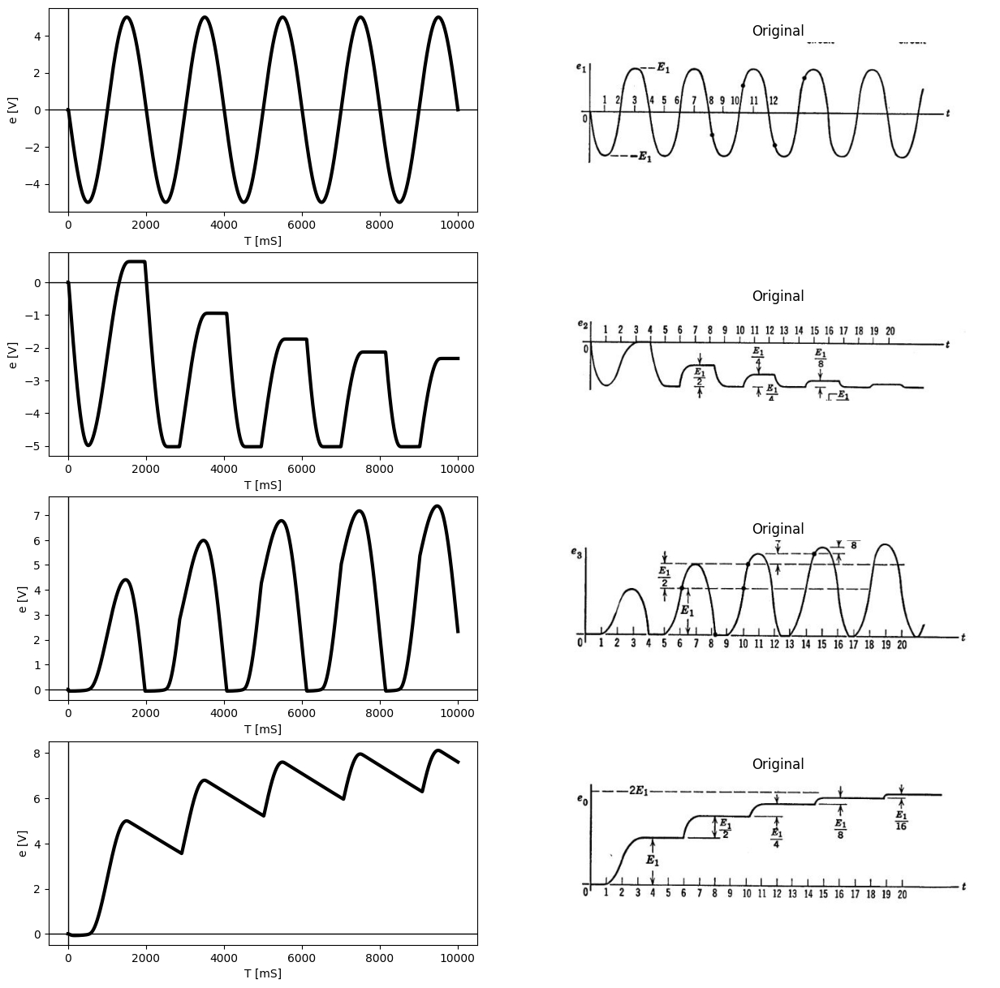

In [58]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=5@u_V)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 1@u_Ohm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[0,0].plot(-analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[0,0].set_xlabel('T [mS]')
axs[0,0].set_ylabel('e [V]')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-9a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1,circuit.gnd, '1', amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 80@u_uF)
circuit.C(1, '1','2', 80@u_uF)
circuit.D(2, '2','3', model = 'BAV21')
#circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[1,0].plot(analysis['1']-analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('e [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-9c.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1,circuit.gnd, '1', amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 80@u_uF)
circuit.C(1, '1','2', 80@u_uF)
circuit.D(2, '2','3', model = 'BAV21')
#circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-9d.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1,circuit.gnd, '1', amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 100@u_uF)
circuit.C(1, '1','2', 120@u_uF)
circuit.D(2, '2','3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 10@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['3'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-9e.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig. 4.9. Voltage doubler build-up.

## 4.7	Voltage-Doubler Build-Up

As indicated by the waveforms of Fig. 4.8, the transient build-up of voltage at the output of the balanced voltage doubler is very simple. The first positive half-cycle of e applied to the circuit charges capacitor $C_a$ to a voltage of about $E_1$ volts. The first negative half-cycle does the same for $C_b$; after that the circuit is in a steady-state condition. Only the small charge lost through the load resistances must be supplied by successive cycles.

For the unbalanced voltage-doubler circuit of Fig. 4.7, the transient build-up proceeds more or less stepwise toward the final value, as indicated in Fig. 4.9. Initially, let us assume the load resistance to be so large that the current through it can be neglected. Two of the four possible diode states are shown in the figure. A third state, that with both diodes non-conducting, occurs twice every cycle. The state with both diodes closed does not occur. With the input waveform shown, the circuit alternates between the two states for which the simplified
circuits apply. The waveforms are drawn for the special case of $C_1$ = $C_2$ As is often the case for nonlinear circuits, the build-up transient of $e_0$ is simpler to analyze if a square wave is applied to the circuit instead of a sine wave.


## 4.8	Step-Charging Circuit with Rectangular-Wave Input

Suppose the input voltage $e_1$ of the voltage doubler consists of a d-c component $E_a$ and a rectangular waveform $e_b$ having a peak-to-peak value $E_b$ and an average value $e_b$ equal to $e_b$ $_b$ $δ_1$/ ($δ_1$ + $δ_2$) as shown in Fig. 4.10. The total direct component of input voltage $e_1$ , the sum of the d-c source voltage $e_a$ and $e_b$, influences the d-c component of waveform $e_2$ but has no effect on $e_3$ or $e_0$. For the waveforms shown, $e_b$ is assumed to start from a positive peak, with a voltage $E_a$ + $E_b$ on $C_1$. The waveforms are again drawn for $C_1$ = $C_2$, but are labeled for the general case.


The sequence of events (diodes opening and closing) proceeds in the same manner as with the sine wave input. On the negative-going steps of the input waveform, diode $D_1$ closes and capacitance $C_1$ is charged

The sequence of events (diodes opening and closing) proceeds in the same manner as with the sine wave input. On the negative-going steps of the input waveform, diode $D_1$ closes and capacitance $C_1$ is charged
to the voltage $E_a$.  On the positive-going steps of $e_1$, diode $D_2$ closes, $D_1$ opens, and a portion of the charge on $C_1$ is placed on $C_2$. With ideal rectangular waves, the events on each rise or fall occur at the same time. Since the transitions are instantaneous, the capacitors are charged or discharged instantaneously in the absence of resistance. This requires an impulse of current (an infinite amplitude, zero duration pulse). The effective area of the impulse corresponds to the charge Δ$Q$ = $C$Δ$E$
added to or subtracted from the effective capacitance $C$ by a voltage change Δ$E$.

The waveforms of Fig. 4.10 show considerable similarity to those of Fig. 4.9, aside from the effects of the d-c component. The time of opening and closing of diodes, in this case, will coincide with the switching instants of the rectangular wave. As in the case here, the square-wave response of a circuit can often be determined and sketched more easily


Text(0.5, 1.0, 'Original')

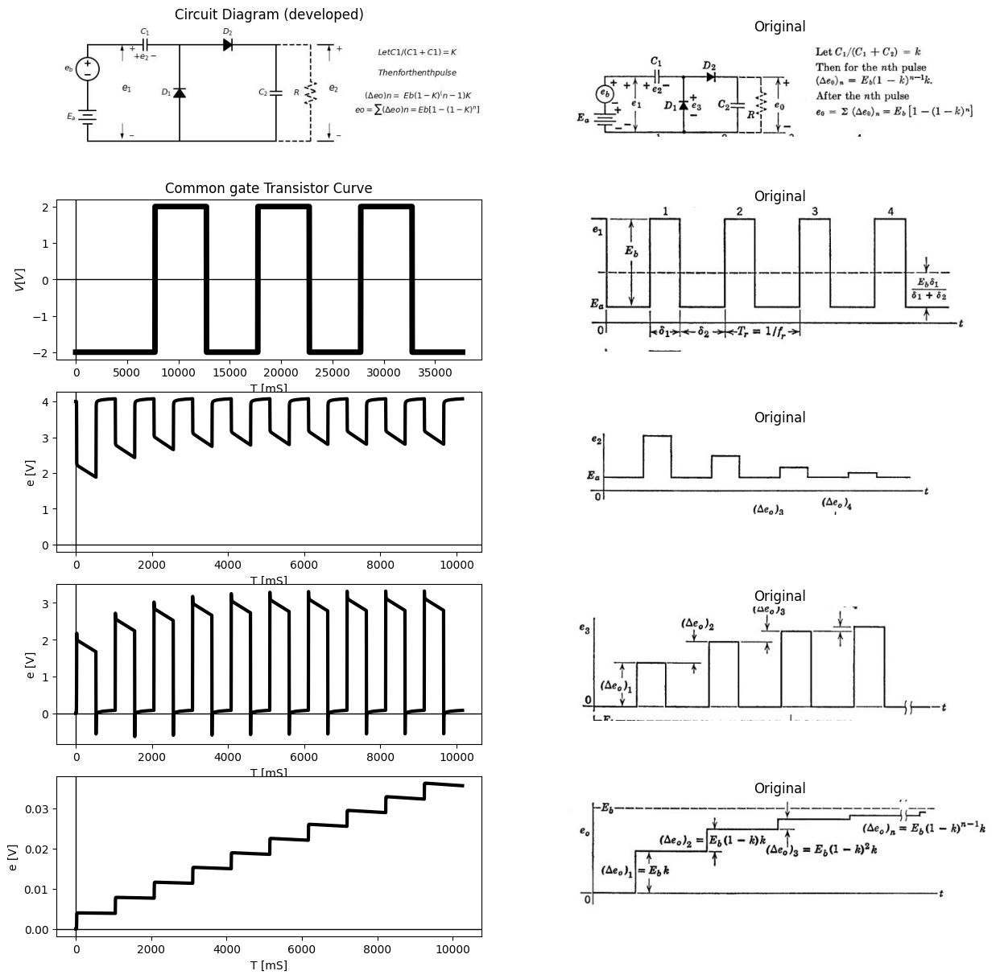

In [103]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.Battery().up(d.unit*.7).label('$E_a$ ','top' ).reverse()
d += elm.SourceV().up(d.unit*.7).label('$e_b$ ','top' )
d+= elm.Line().right().length(1)
d += (C1:= elm.Capacitor().right().label('$C_1$','top').label('$+    e_2    -$','bottom'))
d+= (D1 := elm.Diode(fill=True)).down(d.unit*1.4).label('$D_1$').reverse()
d+= elm.Line().left().length(4)
d+= (D2 := elm.Diode(fill=True)).right(d.unit*1.4).label('$D_2$').at(D1.start)
d += (C2:= elm.Capacitor().down(d.unit*1.4).label('$C_2$','top'))
d+= elm.Line().left().length(4.2)
d+= elm.Line().right().length(1.5).linestyle('--').at(C2.start)
d += (R:= elm.Resistor().down(d.unit*1.4).label('$R$' , 'bot', ofst=-1).linestyle('--'))
d+= elm.Line().left().length(1.5).linestyle('--')
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((1.5,3.5))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((1.5,.8))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((0,1))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10.5,3.5))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10.5,.8))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((9,1))
d+= elm.Line().right().length(.7).at((10,4.2))
d+= elm.Line().right().length(.7).at((10,0))
d+= elm.Line().right().length(.7).at((14,4.2)).color('white').label('$Let C1/(C1+C1)=K$\n\n$Then for the nth pulse$\n\n $(∆eo)n=$ $Eb(1-K)^(n-1)  K$\n$eo= ∑(∆eo)n=Eb[1-(1-K)^n]$','bottom',color='black')
d.save('Drawings/4-10.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-10.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-10.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=-2@u_V,pulsed_value=2@u_V,delay_time=90@u_us ,pulse_width=5@u_ms, period=10@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=.001@u_ms, end_time=30@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
#axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].set_title('Common gate Transistor Curve') 
#axs[1,0].text( 4800, -2, '$D$', ha='center', va='center')
#axs[1,0].text( 500, -0.1, '$B$', ha='center', va='center')
#axs[1,0].text( 4800, -0.1, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$V [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p4-10a.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
pulse1 = circuit.PulseVoltageSource(1, '2', '1', initial_value=-2@u_V,pulsed_value=2@u_V,delay_time=90@u_us ,pulse_width=5@u_ms, period=10@u_ms)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.C(2, '4',circuit.gnd, 80@u_uF)
circuit.C(1, '2','3', 100@u_uF)
circuit.D(2, '3','4', model = 'BAV21')
circuit.R(1, '4',circuit.gnd, 1@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['3']-analysis['2'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('e [V]')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-10c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
pulse1 = circuit.PulseVoltageSource(1, '2', '1', initial_value=-2@u_V,pulsed_value=2@u_V,delay_time=90@u_us ,pulse_width=5@u_ms, period=10@u_ms)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.C(2, '4',circuit.gnd, 80@u_uF)
circuit.C(1, '2','3', 80@u_uF)
circuit.D(2, '3','4', model = 'BAV21')
circuit.R(1, '4',circuit.gnd, 10@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[3,0].plot(analysis['3'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[3,0].set_xlabel('T [mS]')
axs[3,0].set_ylabel('e [V]')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-10d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
pulse1 = circuit.PulseVoltageSource(1, '2', '1', initial_value=-2@u_V,pulsed_value=2@u_V,delay_time=90@u_us ,pulse_width=5@u_ms, period=10@u_ms)
Vi = circuit.V('i', '1', circuit.gnd, -2@u_V)
circuit.D(1, circuit.gnd,'3', model = 'BAV21')
circuit.C(2, '4',circuit.gnd, 80@u_mF)
circuit.C(1, '2','3', 80@u_uF)
circuit.D(2, '3','4', model = 'BAV21')
circuit.R(1, '4',circuit.gnd, 1@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.1@u_s)
axs[4,0].plot(analysis['4'],'black',linewidth=3)
#axs[1,0].plot(analysis['1'],'black',linewidth=2,linestyle='--')
axs[4,0].set_xlabel('T [mS]')
axs[4,0].set_ylabel('e [V]')
axs[4,0].axhline(0, color='black', linewidth=1)
axs[4,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-10e.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

### Fig. 4.10. Step-charging circuit with rectangular input waveform.

than the sine-wave response. In such cases it is not amiss to consider the square wave as a rough approximation to a sine wave. If a better straight-line or piecewise-linear approximation to a sine wave is desired, a trapezoidal waveform can be used. The trapezoidal waveform separates diode events in time, and also results in constant charge or discharge current, since $d$ $e_1$/$dt$ is constant during the rise or fall.

## 4.9	An Electronic Frequency Meter

In discussing the voltage doubler, the use of the circuit as a voltmeter to read peak-to-peak a-c voltages was suggested. This application requires a very high value of load resistance to approach the true reading.  The capacitors $C_1$ and $C_2$ were logically, but not necessarily,
equal.  In the step-charging application, a ratio $C_1$/$C_2$ less than one
yields smaller step increments and therefore a slower rise. Ratios of the order of 0.1 to 0.5 are common in practical circuits.


Let us now consider the same circuit, with $C_2$ very large ($C_1$/$C_2$ small) and with the output load resistance small. Let this resistance include the resistance of a 0—1 ma d-c milliammeter, as shown in Fig. 4.11. Since there can be no average current through $C_2$, the milliammeter registers the average value of charging current supplied to $C_2$ through diode $D_2$ and capacitor $C_1$.


If the discharge of $C_1$ goes to completion during the time the input
voltage is at a minimum, then virtually the entire peak-to-peak change
of voltage et occurs across $C_1$.	Actually, the change Δ$e_2$ equals $e_b$ $C_1$/( $C_1$ + $C_2$) which is somewhat less than one per cent of $E_b$ if $C_2$ ≥ 100$C_1$.  Thus each positive-going change increases the charge on
$C_1$ and $C_2$ by a fixed amount


ΔQ = $E_b$[ $C_1$ $C_2$ / ($C_1$ + $C_2$) ] ≈ $E_b$ $C_1$


This amount of charge is added once during each cycle of the input wave. Thus the average current through the meter (assuming $e_0$ << $E_b$) is I = ΔQ/$τ_r$ = ΔQ$f_r$; hence $f_r$ = $I$/$E_b$ $C_1$. So long as ΔQ remains constant, $I$ is proportional to $f_r$ and the instrument can be calibrated to read $f_r$ directly. The charge ΔQ per cycle is constant so long as peak- to-peak voltage is constant; hence the circuit is often preceded by an amplitude limiter. The reading is independent of waveform, provided the charge or discharge of $C_1$ has time to reach completion each time the voltage swings positive or negative. It is also assumed that the meter reading is not aflected by the pulsations of the current. The current could be further smoothed by another large capacitor connected directly across the milliammeter.


Deviation from linearity in the relation $f_r$ vs. $I$ may be expected for very low values of $I$. Contact potentials, increase in actual diode resistances, or a variety of stray effects influence the behavior near zero current.	At the upper end of the scale, the curve will deviate from linearity if output voltage $e_0$ becomes comparable to Δ$e_1$.


Text(0.5, 1.0, 'Original')

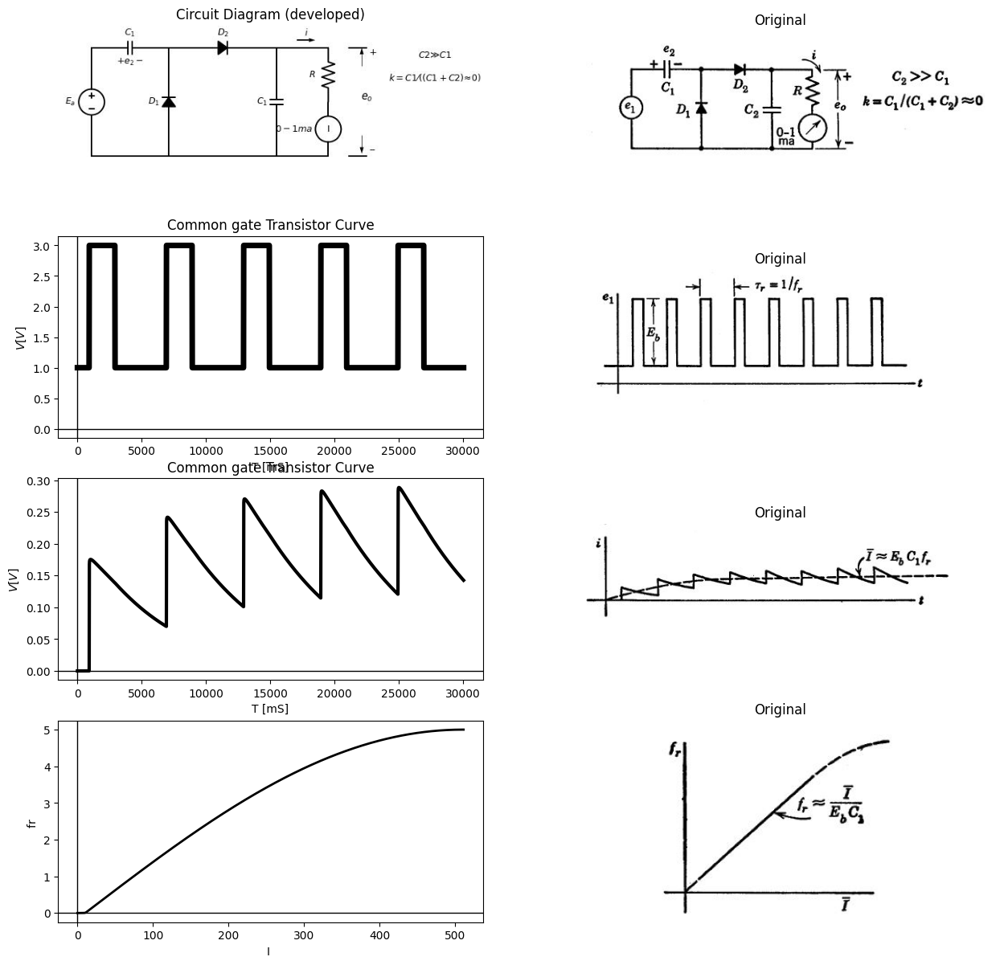

In [133]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += elm.SourceV().up(d.unit*1.4).label('$E_a$ ','top' )
d += (C1:= elm.Capacitor().right().label('$C_1$','top').label('$+    e_2    -$','bottom'))
d+= (D1 := elm.Diode(fill=True)).down(d.unit*1.4).label('$D_1$').reverse()
d+= elm.Line().left().length(3)
d+= (D2 := elm.Diode(fill=True)).right(d.unit*1.4).label('$D_2$').at(D1.start)
d += (C2:= elm.Capacitor().down(d.unit*1.4).label('$C_1$','top'))
d+= elm.Line().left().length(4.2)
d+= elm.Line().right().length(2).at(C2.start)
d += (R:= elm.Resistor().down(d.unit*.7).label('$R$' , 'bot', ofst=-1))
I = d.add(elm.MeterI().down(d.unit*.7).label('$0-1 ma$', 'top'))
l1 = d.add(elm.Line().left(d.unit*.9))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10.5,3.5))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10.5,.8))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((9,1))
d+= elm.Line().right().length(.7).at((10,4.2))
d+= elm.Line().right().length(.7).at((10,0))
d += elm.Arrow().right().length(.7).color('black').label('$i$', loc='top', color='black'). at((8,4.5))
d+= elm.Line().right().length(.7).at((13,4.2)).label('$C2≫C1$\n\n$k=C1⁄((C1+C2)≈0)$', 'bottom',color='black').color('white')
d.save('Drawings/4-11.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-11.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-11.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, 'e1', circuit.gnd, initial_value=1@u_V,pulsed_value=3@u_V,delay_time=900@u_us ,pulse_width=2@u_ms, period=6@u_ms)
circuit.model('2N7000', 'NMOS', L=0.18E-6, W=2E-6,LAMBDA = 1 ,Kp=0.007, Vto=.5)
circuit.MOSFET(1, 'eb', 'e1', circuit.gnd,circuit.gnd, model='2N7000')
circuit.R(1, 'Ebb', 'eb', 4@u_Ohm)
circuit.MOSFET(2, 'n1', 'e2', circuit.gnd,circuit.gnd, model='2N7000')
circuit.C(1, 'eb', 'e2', 2@u_mF)
circuit.R(2, 'e2', circuit.gnd, 40@u_Ohm)
circuit.R(3, 'n1', 'Ebb', 40@u_Ohm)
circuit.V(2, 'Ebb', circuit.gnd, 1.8@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=.001@u_ms, end_time=30@u_ms)

axs[1,0].plot(analysis['e1'],'black',linewidth=5)
#axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[1,0].set_title('Common gate Transistor Curve') 
#axs[1,0].text( 4800, -2, '$D$', ha='center', va='center')
#axs[1,0].text( 500, -0.1, '$B$', ha='center', va='center')
#axs[1,0].text( 4800, -0.1, '$C$', ha='center', va='center')
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('$V [V]$')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p4-11a.JPG')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
circuit = Circuit('NMOS')
pulse1 = circuit.PulseVoltageSource(1, '1', circuit.gnd, initial_value=1@u_V,pulsed_value=3@u_V,delay_time=900@u_us ,pulse_width=2@u_ms, period=6@u_ms)
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.R(1, '3', circuit.gnd, 4@u_Ohm)
circuit.D(2, '2','3', model = 'BAV21')
circuit.C(1, '1', '2', 200@u_uF)
circuit.C(2, '3', circuit.gnd, 2@u_mF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=.001@u_ms, end_time=30@u_ms)

axs[2,0].plot( analysis['3'],'black',linewidth=3)
#axs[1,0].text( 500, -2, '$A$', ha='center', va='center')
axs[2,0].set_title('Common gate Transistor Curve') 
#axs[1,0].text( 4800, -2, '$D$', ha='center', va='center')
#axs[1,0].text( 500, -0.1, '$B$', ha='center', va='center')
#axs[1,0].text( 4800, -0.1, '$C$', ha='center', va='center')
axs[2,0].set_xlabel('T [mS]')
axs[2,0].set_ylabel('$V [V]$')
axs[2,0].axhline(0, color='black', linewidth=1)
axs[2,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p4-11b.JPG')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
circuit = Circuit('inpu')
circuit.model('BAV21','D' ,IS = 10@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS =0.01@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',circuit.gnd, amplitude=5@u_V)
#Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.D(1, circuit.gnd,'2', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 80@u_uF)
circuit.C(1, '1','2', 80@u_uF)
circuit.D(2, '2','3', model = 'BAV21')
#circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.005@u_s)
#axs[3,0].plot(analysis['1'],'black',linewidth=3)
axs[3,0].plot(analysis['1'],'black',linewidth=2,linestyle='-')
axs[3,0].set_xlabel('I ')
axs[3,0].set_ylabel('fr ')
axs[3,0].axhline(0, color='black', linewidth=1)
axs[3,0].axvline(0, color='black', linewidth=1)
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-11c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### fig. 4.11.  An electronic frequency meter.

## 4.10	Full-Wove Rectifier with Smoothing Capacitor

The analysis of the full-wave rectifier circuit poses no new problems, but this class of circuits is sufficiently important to justify consideration. The transfer curves for several variations of the full-wave rectifier circuit were presented in Chapter 3. The addition of a smoothing capacitor to the circuit yields results similar to those obtained for the basic rectifier circuit. With a given capacitor, load resistance, and input frequency, the ripple is smaller for the full-wave rectifier, since each half-cycle recharges the smoothing capacitor. The capacitor discharge involves an interval approximating $T$/2, compared with $T$ for the half-wave rectifier.

Text(0.5, 1.0, 'Original')

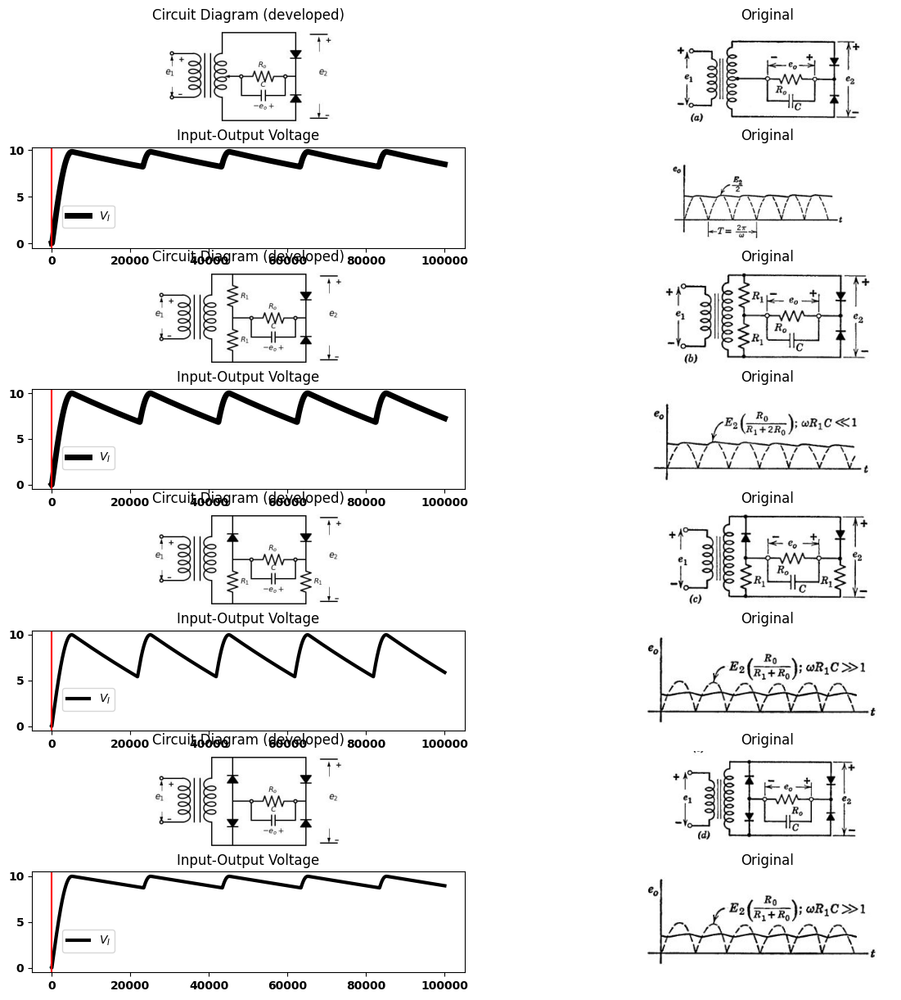

In [17]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(8, 2, figsize=(15, 15))
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(3.5)
d+= (D1 := elm.Diode(fill=True)).down(d.unit*.7)
d+= (D2 := elm.Diode(fill=True)).down(d.unit*.7).reverse()
d+= elm.Line().left().length(3.5)
d+= elm.Line().up().length(1.1)
d+= elm.Line().left().length(.5).dot(open=True).at(D1.end)
d += (R1:= elm.Resistor().left(d.unit*.7).label('$R_o$' , 'bot', ofst=-1).dot(open=True))
d+= elm.Line().down().length(.9).at(R1.start)
d += (C1:= elm.Capacitor().left(d.unit*.7).label('$C$','top').label('$-    e_o    +$','bottom'))
d+= elm.Line().up().length(.9)
d+= elm.Arrow().left().length(.8)
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6,2.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6,-.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.5,-.1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-1,1.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-1,.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-2.8,-.1))
d+= elm.Line().right().length(.8).at((5.6,3))
d+= elm.Line().right().length(.8).at((5.6,-1))
d.save('Drawings/4-12.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-12.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','o', model = 'BAV21')
circuit.R(1, 'o',circuit.gnd, 10@u_Ohm)
circuit.C(1, 'o',circuit.gnd, 10@u_mF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[1, 0].plot(analysis['1'],'blue',linewidth=5)
axs[1, 0].plot(analysis['o'],'black',linewidth=5) 
axs[1, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[1, 0].axvline(x=0, color='red') 
axs[1, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12a1.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(4.5)
d+= (D1 := elm.Diode(fill=True)).down(d.unit*.7)
d+= (D2 := elm.Diode(fill=True)).down(d.unit*.7).reverse()
d+= elm.Line().left().length(4.5)
d+= elm.Line().up().length(1.1)
d+= elm.Line().left().length(.5).dot(open=True).at(D1.end)
d += (R1:= elm.Resistor().left(d.unit*.7).label('$R_o$' , 'bot', ofst=-1).dot(open=True))
d+= elm.Line().down().length(.9).at(R1.start)
d += (C1:= elm.Capacitor().left(d.unit*.7).label('$C$','top').label('$-    e_o    +$','bottom'))
d+= elm.Line().up().length(.9)
d+= elm.Line().left().length(.9)
d += (R2:= elm.Resistor().up(d.unit*.7).label('$R_1$' , 'bot', ofst=.1))
d += (R3:= elm.Resistor().down(d.unit*.7).label('$R_1$' , 'bot', ofst=.1).at(R2.start))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((7,2.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((7,-.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.5,-.1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-1,1.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-1,.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-2.8,-.1))
d+= elm.Line().right().length(.8).at((6.6,3))
d+= elm.Line().right().length(.8).at((6.6,-1))
d.save('Drawings/4-12-1.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-12-1.jpg')
axs[2, 0].imshow(img)
axs[2, 0].axis('off')  # Hide axes for image display
axs[2, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','o', model = 'BAV21')
circuit.R(1, 'o',circuit.gnd, 10@u_kOhm)
circuit.C(1, 'o',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[1, 0].plot(analysis['1'],'blue',linewidth=5)
axs[3, 0].plot(analysis['o'],'black',linewidth=5) 
axs[3, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[3, 0].axvline(x=0, color='red') 
axs[3, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(4.5)
d+= (D1 := elm.Diode(fill=True)).down(d.unit*.7)
d += (R3:= elm.Resistor().down(d.unit*.7).label('$R_1$' , 'bot', ofst=.1))
d+= elm.Line().left().length(4.5)
d+= elm.Line().up().length(1.1)
d+= elm.Line().left().length(.5).dot(open=True).at(D1.end)
d += (R1:= elm.Resistor().left(d.unit*.7).label('$R_o$' , 'bot', ofst=-1).dot(open=True))
d+= elm.Line().down().length(.9).at(R1.start)
d += (C1:= elm.Capacitor().left(d.unit*.7).label('$C$','top').label('$-    e_o    +$','bottom'))
d+= elm.Line().up().length(.9)
d+= elm.Line().left().length(.9)
d+= (D1 := elm.Diode(fill=True)).up(d.unit*.7)
d += (R3:= elm.Resistor().down(d.unit*.7).label('$R_1$' , 'bot', ofst=.1).at(R2.start))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((7,2.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((7,-.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.5,-.1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-1,1.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-1,.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-2.8,-.1))
d+= elm.Line().right().length(.8).at((6.6,3))
d+= elm.Line().right().length(.8).at((6.6,-1))
d.save('Drawings/4-12-3.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-12-3.jpg')
axs[4, 0].imshow(img)
axs[4, 0].axis('off')  # Hide axes for image display
axs[4, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12e.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '2','1', model = 'BAV21')
circuit.D(2, '1','3', model = 'BAV21')
circuit.D(3, '1',circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 10@u_kOhm)
circuit.C(1, '3',circuit.gnd, 10@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[5, 0].plot(analysis['2'],'blue',linewidth=5)
axs[5, 0].plot(analysis['3'],'black',linewidth=3) 
axs[5, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[5, 0].axvline(x=0, color='red') 
axs[5, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12g.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(4.5)
d+= (D1 := elm.Diode(fill=True)).down(d.unit*.7)
d+= (D2 := elm.Diode(fill=True)).down(d.unit*.7).reverse()
d+= elm.Line().left().length(4.5)
d+= elm.Line().up().length(1.1)
d+= elm.Line().left().length(.5).dot(open=True).at(D1.end)
d += (R1:= elm.Resistor().left(d.unit*.7).label('$R_o$' , 'bot', ofst=-1).dot(open=True))
d+= elm.Line().down().length(.9).at(R1.start)
d += (C1:= elm.Capacitor().left(d.unit*.7).label('$C$','top').label('$-    e_o    +$','bottom'))
d+= elm.Line().up().length(.9)
d+= elm.Line().left().length(.9)
d+= (D3 := elm.Diode(fill=True)).up(d.unit*.7)
d+= (D4 := elm.Diode(fill=True)).down(d.unit*.7).at(D3.start)
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((7,2.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((7,-.3))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5.5,-.1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((-1,1.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((-1,.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-2.8,-.1))
d+= elm.Line().right().length(.8).at((6.6,3))
d+= elm.Line().right().length(.8).at((6.6,-1))
d.save('Drawings/4-12-4.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-12-4.jpg')
axs[6, 0].imshow(img)
axs[6, 0].axis('off')  # Hide axes for image display
axs[6, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12h.jpg')  # Load the PNG file
axs[6,1].imshow(img_sample)
axs[6,1].axis('off')  # Hide axes for image display
axs[6,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '2','1', model = 'BAV21')
circuit.D(2, '1','3', model = 'BAV21')
circuit.D(3, '1',circuit.gnd, model = 'BAV21')
circuit.D(4, circuit.gnd,'3', model = 'BAV21')
circuit.R(1, '3',circuit.gnd, 100@u_kOhm)
circuit.C(1, '3',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[5, 0].plot(analysis['2'],'blue',linewidth=5)
axs[7, 0].plot(analysis['3'],'black',linewidth=3) 
axs[7, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[7, 0].axvline(x=0, color='red') 
axs[7, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-12g.jpg')  # Load the PNG file
axs[7,1].imshow(img_sample)
axs[7,1].axis('off')  # Hide axes for image display
axs[7,1].set_title('Original')

For each circuit $e_2$= $E_2$ sin$wt$  , $wR_o.C>>1$

### fig. 4.l2. Full-wave reetifier cimuits with smoothing capacitor.

A very common form of the circuit is shown in Fig. 4.12(a$$). Here, half of the voltage available from the transformer secondary is applied to each half of the circuit. If the transformer center tap is not used, or if the source has no center tap available, the circuit may take the form shown in Fig. 4.12($b$) or ($c$). These two forms are not well suited to power-rectifier applications because of the power lost in the resistors $R_1$ . The circuit of Fig. 4.12($c$) produces a slightly larger d-c voltage than the circuit of ($b$). When no center tap is available, the bridge circuit shown in Fig. 4.12($d$) is preferable for power-rectifier applications. Of the circuits ($b$), ($c$), and ($d$), this one is unique in providing an output that approaches the peak of the a-c supply voltage without wasting power in resistances ($R_1$).

## 4.11	Ripple Filter with Capacitance Input

A single smoothing capacitor used in conjunction with a rectifier is usually adequate for low-current loads such as those encountered in instrument applications, but when a d-c source is required to supply larger currents, additional filtering may be necessary. Typical examples are the power supplies that provide the d-c operating voltages for vacuum-tube electrodes in electronic systems. Voltages of 100 to 300 volts and currents of the order of 100 ma or more are common for low- power triode and pentode circuits. The effects of a poorly filtered power supply on an audio system can be heard directly in the form of an objectionable hum. The effects of ripple on the behavior of other types of circuits can be equally serious.

When ripple reduction is important, a full-wave rectifier — such as the one shown in Fig. 4.12($a$) — is the logical choice.	Consider the rectifier and filter circuit shown in Fig. 4.13, where an inductor and a capacitor have been added between the original smoothing capacitor and the resistive load.	With these energy-storage elements in the circuit, a general solution is lengthy.	However, in the design of a power-supply ripple filter we are obviously interested in making the ripple output very small compared with the d-c output. Using this as an assumption, we can reduce the problem to much simpler proportions. It is convenient to resolve each current and voltage into a steady component (d-c) and a ripple component (a-c), as indicated in Fig.
4.13. This is possible for any periodic time function, regardless of the relative amplitudes of the d-c and a-c components.

We can establish the d-c condition by inspection. Because the capacitors cannot pass d-c


$i_1$=$i_2$=$e_3$/$R$


If we assume that the inductor $L$ has zero resistance, then there can be no d-c drop across it, and


$e_2$=$e_3$


The ripple waveforms can be readily derived if the assumption of small percentage ripple is carefully exploited. First, $C_1$, must be large enough to make $e_2$ $_r$, much smaller than $E_1$, in which case the current $i_1$ will consist of brief pulses occurring every half period. Since there are

Text(0.5, 1.0, 'Original')

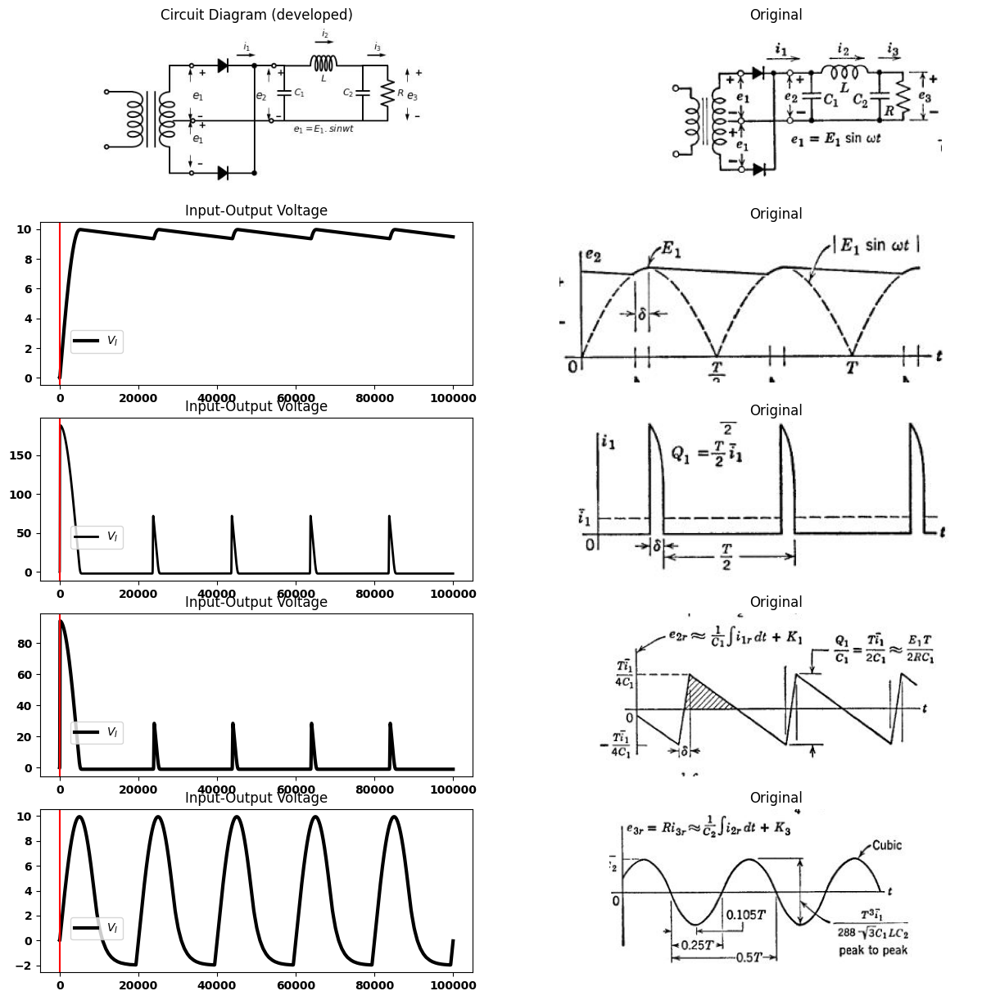

In [47]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(0.85).dot(open=True)
d+= (D1 := elm.Diode(fill=True)).right(d.unit*.8).dot()
d+= (l1 := elm.Line().right().length(0.75).dot(open=True))
d+= elm.Line().down().length(1).at(x.s2)
d+= elm.Line().right().length(0.85).dot(open=True)
d+= (D2 := elm.Diode(fill=True)).right(d.unit*.8).dot()
d+= elm.Line().up().length(4)
d+= (l2 := elm.Line().right().length(.4).at(l1.end))
d += (C1:= elm.Capacitor().down(d.unit*.7).label('$C_1$','bottom').at(l2.end))
d+= elm.Line().left().length(0.5).dot(open=True)
d+= elm.Line().left().length(3).dot(open=True)
d+= elm.Line().left().length(.75)
d += (L1:= elm.Inductor2().right(d.unit*1).label('$L$','bottom').at(C1.start))
d += (C2:= elm.Capacitor().down(d.unit*.7).label('$C_2$','top'))
d+= elm.Line().left().length(3).label('$e_1=E_1.sinwt$','bottom')
d+= elm.Line().right().length(.95).at(C2.start)
d += (R1:= elm.Resistor().down(d.unit*.7).label('$R$' , 'bot', ofst=.1))
d+= elm.Line().left().length(.95)
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((2.2,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2.2,1.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((.8,.65))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((2.2,.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2.2,-.3))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((.8,-1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((5.2,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.2,1.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.2,.65))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10.5,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10.5,1.5))
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((9,.65))
d += elm.Arrow().right().length(.7).color('black').label('$i_1$', loc='top', color='black'). at((4,3.5))
d += elm.Arrow().right().length(.7).color('black').label('$i_2$', loc='top', color='black'). at((7,4))
d += elm.Arrow().right().length(.7).color('black').label('$i_3$', loc='top', color='black'). at((9,3.5))
d.save('Drawings/4-13.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-13.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-13a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
#circuit.D(2, '1','3', model = 'BAV21')
#circuit.C(2, '3',circuit.gnd, 30@u_uF)
#circuit.L(1,'2', '3', 30@u_mH)
#circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
circuit.C(1, '2',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[5, 0].plot(analysis['2'],'blue',linewidth=5)
axs[1, 0].plot(analysis['2'],'black',linewidth=3) 
axs[1, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[1, 0].axvline(x=0, color='red') 
axs[1, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-13b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
circuit.D(2, '1','3', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 30@u_uF)
circuit.L(1,'2', '3', 30@u_mH)
circuit.R(1, '3',circuit.gnd, 10@u_kOhm)
circuit.C(1, '2',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

axs[2, 0].plot(u_mA(-analysis.V1), 'black', linestyle='-',linewidth=2)
#axs[2, 0].plot(analysis['2'],'black',linewidth=3) 
axs[2, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[2, 0].axvline(x=0, color='red') 
axs[2, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-13c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
#circuit.D(2, '1','3', model = 'BAV21')
#circuit.C(2, '3',circuit.gnd, 30@u_uF)
#circuit.L(1,'2', '3', 30@u_mH)
#circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
circuit.C(1, '2',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[5, 0].plot(analysis['2'],'blue',linewidth=5)
axs[3, 0].plot(u_mA(-analysis.V1),'black',linewidth=3) 
axs[3, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[3, 0].axvline(x=0, color='red') 
axs[3, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-13d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
circuit.D(2, '1','3', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 1@u_uF)
circuit.L(1,'2', '3', 30@u_mH)
circuit.R(1, '3',circuit.gnd, 1@u_kOhm)
circuit.C(1, '2',circuit.gnd, 1@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

#axs[4, 0].plot(u_mA(-analysis.V1), 'black', linestyle='-',linewidth=2)
axs[4, 0].plot(analysis['3'],'black',linewidth=3) 
axs[4, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[4, 0].axvline(x=0, color='red') 
axs[4, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-13g.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

### Fig. 4.13.  Ripple filter with capacitance input.

two pulses in the period $T$ the charge conducted during each pulse is related to the average current as follows:

$Q_1$ = $T$ $i_1$ / 2


The amplitude of the equivalent rectangular current pulse of duration δ is


$I_1$ = $T$ $i_1$ / 2  δ


Three additional closely related assumptions are necessary to complete the solution, all based on the assumption of adequate filtering. The ripple current $i_2$ $_r$. must be much smaller than $i_1$ $_r$, so all of it $i_1$ $_r$ can be considered to flow through $C_1$. The ripple voltage $e_3$ $_r$, must be much smaller than $e_2$ $_r$, so all of voltage $e_2$ $_r$, can be considered to be across $L$. The ripple current through the load $R$ must be much smaller than $i_1$ $_r$, so all of it, flows through $C_2$. Integration of the current waveform $i_1$ $_r$ then gives the ripple voltage across $C_1$:



$e_2$ $_r$ = 1/ $C_1$ ∫ $i_1$ $_r$ $dt$ + $K_1$


The constant $K_1$ is adjusted to give $e_2$ $_r$, Eero mean value.	Successive integrations yield $i_2$ $_r$ and $e_3$ $_r$  thus


$i_2$ $_r$ = 1/ $L$ ∫ $e_2$ $_r$ $dt$ + $K_2$


$e_3$ $_r$ = 1/ $C_2$ ∫ $i_2$ $_r$ $dt$ + $K_3$


Note that the peak value of $e_3$ $_r$ the output ripple, is directly proportional to the load current for this circuit.
The per-unit ripple (peak-to-peak) of the output voltage is



$e_3$ $_r$ / $e_3$ = $T^3$ / 288 √3 $C_1$ $L$ $C_2$  $R$


$e_3$ $_r$ / $e_3$ = 0.5 (1/ $w$ $C_1$) (1/$w$ $C_2$) / $w$ $LR$


where $w$ is the angular frequency of $e_1$.

 
Equation 4.15 shows that increasing any of the elements $C_1$, $L$, or $C_2$ will decrease per-unit ripple. These three elements must be chosen to yield the desired value of ripple. Since an increase in power- supply frequency eases the filtering problem, portable, mobile, or air-
borne electronic systems (which are not bound to a 60-cps a-c supply frequency) usually make use of much higher primary a-c supply fre- quencies, for example 400 cps or 1200 cps.



Note that because of the successive integrations, the final ripple waveform is very nearly sinusoidal. If the peaks occurred at 0.125$T$ instead of 0.105$T$ from the zero crossings, the wave would approach a sine wave.  In any event, $e_3$ $_r$, is close enough to sinusoidal to assume it to be a sine wave if further filter elements are to be added.

Text(0.5, 1.0, 'Original')

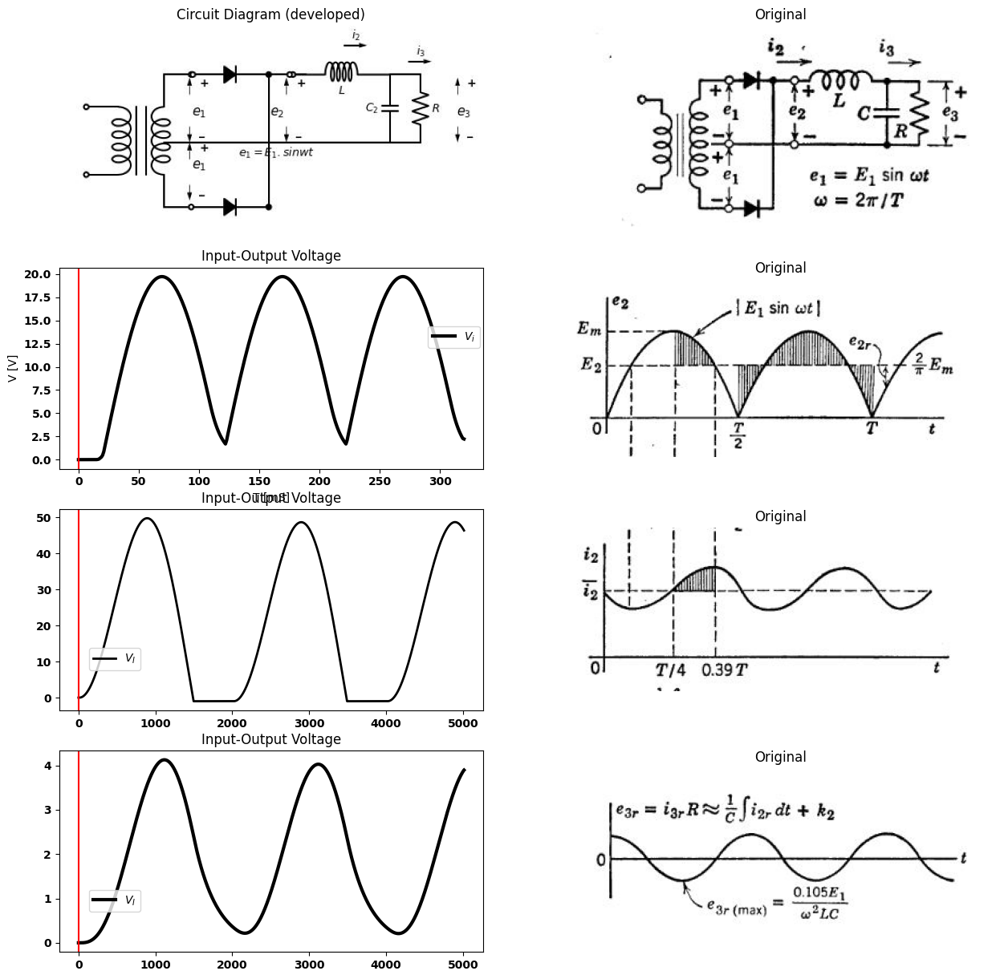

In [18]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
x = d.add(elm.Transformer(loop=True))
d+= elm.Line().left().length(1).at(x.p1).dot(open=True)
d+= elm.Line().left().length(1).at(x.p2).dot(open=True)
d+= elm.Line().up().length(1).at(x.s1)
d+= elm.Line().right().length(0.85).dot(open=True)
d+= (D1 := elm.Diode(fill=True)).right(d.unit*.8).dot()
d+= (l1 := elm.Line().right().length(0.75).dot(open=True))
d+= elm.Line().down().length(1).at(x.s2)
d+= elm.Line().right().length(0.85).dot(open=True)
d+= (D2 := elm.Diode(fill=True)).right(d.unit*.8).dot()
d+= elm.Line().up().length(4)
d+= (l2 := elm.Line().right().length(.4).at(l1.end))
    #d += (C1:= elm.Capacitor().down(d.unit*.7).label('$C_1$','bottom').at(l2.end))
d+= elm.Line().left().length(0.5).dot(open=True)
d+= elm.Line().left().length(3).dot(open=True)
d+= elm.Line().left().length(.75)
d += (L1:= elm.Inductor2().right(d.unit*1).label('$L$','bottom').at(l2.start))
d += (C2:= elm.Capacitor().down(d.unit*.7).label('$C_2$','top'))
d+= elm.Line().left().length(7).label('$e_1=E_1.sinwt$','bottom')
d+= elm.Line().right().length(.95).at(C2.start)
d += (R1:= elm.Resistor().down(d.unit*.7).label('$R$' , 'bot', ofst=.1))
d+= elm.Line().left().length(.95)
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((2.2,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2.2,1.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((.8,.65))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((2.2,.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((2.2,-.3))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((.8,-1))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((5.2,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5.2,1.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.2,.65))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10.5,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10.5,1.5))
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((9,.65))
    #d += elm.Arrow().right().length(.7).color('black').label('$i_1$', loc='top', color='black'). at((4,3.5))
d += elm.Arrow().right().length(.7).color('black').label('$i_2$', loc='top', color='black'). at((7,4))
d += elm.Arrow().right().length(.7).color('black').label('$i_3$', loc='top', color='black'). at((9,3.5))
d.save('Drawings/4-14.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-14.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-14a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('Full-wave rectifier')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=20@u_V)
circuit.SinusoidalVoltageSource(2, circuit.gnd, 'o1', amplitude=20@u_V)
circuit.D(1, '1','3', model = 'BAV21')
circuit.C(1, '3',circuit.gnd, 1@u_mF)
circuit.L(1, '3','4', 1@u_uH)
circuit.C(2, '4',circuit.gnd, 1@u_uF)
circuit.R(1, '4',circuit.gnd, 1@u_Ohm)
circuit.D(2, 'o1','3', model = 'BAV21')
#figure, ax1 = plt.subplots(figsize=(15, 5))
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.1@u_ms, end_time=0.03@u_s)

axs[1,0].plot(analysis['3'],'black',linewidth=3)
#axs[0,1].plot(analysis['o1'],'black',linewidth=5,linestyle='--') 
axs[1,0].legend(('$V_i$','$V_o$',), loc=(.87,.6)) 
axs[1,0].axvline(x=0, color='red') 
axs[1,0].set_title('Input-Output Voltage') 
#axs[0,1].grid()
axs[1,0].set_xlabel('T [mS]')
axs[1,0].set_ylabel('V [V]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-14b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
circuit.D(2, '2','4', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 30@u_uF)
circuit.L(1,'2', '3', 1@u_H)
circuit.R(1, '3',circuit.gnd, 100@u_Ohm)
#circuit.C(1, '2',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.05@u_s)

axs[2, 0].plot(u_mA(-analysis.V1), 'black', linestyle='-',linewidth=2)
#axs[2, 0].plot(analysis['2'],'black',linewidth=3) 
axs[2, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[2, 0].axvline(x=0, color='red') 
axs[2, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-14c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('shun')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm) 
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=10@u_V) 
circuit.D(1, '1','2', model = 'BAV21')
circuit.D(2, '2','4', model = 'BAV21')
circuit.C(2, '3',circuit.gnd, 30@u_uF)
circuit.L(1,'2', '3', 1@u_H)
circuit.R(1, '3',circuit.gnd, 100@u_Ohm)
#circuit.C(1, '2',circuit.gnd, 30@u_uF)
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.01@u_ms, end_time=0.05@u_s)

#axs[3, 0].plot(u_mA(-analysis.V1), 'black', linestyle='-',linewidth=2)
axs[3, 0].plot(analysis['3'],'black',linewidth=3) 
axs[3, 0].legend(('$V_I$','$V_O$',), loc=(.07,.2)) 
axs[3, 0].axvline(x=0, color='red') 
axs[3, 0].set_title('Input-Output Voltage') 
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-14d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### fig. 4.14.  Ripple filter with inductance input.

## 4.12	A Ripple Filter with Inductance Input

The capacitance-input filter described in the previous article requires large peak currents from the rectifying diodes in order to supply a nominal average or direct current. Since these peak currents are caused by the input capacitor $C_1$. let us remove $C_1$ from the filter of Fig. 4.13, leaving the configuration shown in Fig. 4.14. If the inductance $L$ is large enough to make the ripple amplitude $i_2$ $_r$ $_max$ smaller than the average value $i_2$, then the current $i_2$  is always positive, and one diode or the other is always conducting. In addition to assuming $i_2$ always positive, let us assume effective filtering so that $i_2$, is much greater than $i_3$ $_r$ and $e_2$ $_r$ , is much greater than$e_3$ $_r$, as in the previous discussion. Also as before, we have


$i_2$ = $i_3$ = $e_3$ / $R$

$e_3$ = $e_2$ 

but here


$e_2$ = 2$E_m$ / π 


As in the case of the capacitor-input filter, successive integrations of the ripple voltage $e_2$ $_r$. yield the output ripple waveform $e_3$ $_r$ :


$i_2$ $_r$ = 1/ $L$ ∫ $e_2$ $_r$ $dt$ + $K_1$


$i_2$ $_r$ = 1/ $C$ ∫ $i_2$ $_r$ $dt$ + $K_2$


A ripple filter with inductance input yields a d-c output voltage approxi- mating the average value of the rectified waveform; whereas, with capacitance input, the d-c output approaches the peak value of the rectified sine wave.
If the total ripple current $i_2$ $_r$. is assumed to be sinusoidal and much greater than $i_3$ $_r$ then it follows directly that the ripple output $e_3$ $_r$, is approximately sinusoidal (at frequency $2w$) and has an amplitude



$e_3$ $_r$ $max$ = $i_2$ $_r$ $max$ / 2$wC$

≈0.1 $E_1$/$wC$/$wL$


where $w$ is the angular frequency of $e_1$.
The ripple voltage $e_3$ $_r$ , is nominally independent of load current $i_3$ for the inductance-input filter. This means that the inductance-input filter is well suited to applications requiring high output currents. In contrast, the ripple output from a capacitor-input filter is directly proportional to the useful load current or inversely proportional to load resistance (assuming that d-c voltage remains nearly constant).

The inductance-input filter requires a minimum load to sustain the mode of operation just described. As shown in Fig. 4.15, the d-c output voltage tends to rise sharply below a certain critical load current. Below this value of current, the diodes are both off during part of the cycle and our analysis does not apply. For zero load current (infinite $R$), the d-c output voltage approaches $E_1$. The critical value of load resistance for which $i_2$ just reaches Eero at one point in each half-cycle corresponds to the condition


$i_2$=$i_2$ $_r$ $max$ 


from fig.4.14


$i_2$ $_r$ $max$ = 0.21 $E_2$ / $wL$


Text(0.5, 1.0, 'Original')

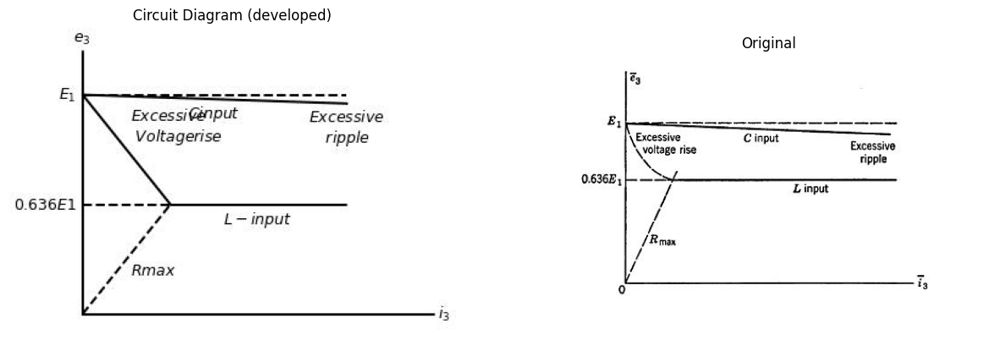

In [4]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d+=(l1 :=elm.Line().right().length(8).label('$i_3$ ','right' ))
d+=(l2:= elm.Line().up().length(6).label('$e_3$ ','right' ).at(l1.start))
d+=(l3:= elm.Line().right().length(2).label('$0.636E1$ ','left' ).at((0,2.5)).linestyle('--'))
d+=(l4:= elm.Line().right().length(4).label('$L-input$ ','bottom' ))
d+=(l5:= elm.Line().right().length(6).at((0,5)).linestyle('--').label('$E_1$ ','left' ))
d+=(l6:= elm.Line().right().length(0.02).at((6,4.8)).linestyle('--').label('$Excessive$\n $ripple$ ','bottom' ))
d+=(l7:= elm.Line().right().length(6).endpoints(l5.start,l6.end).label('$C input$ ','bottom' ))
d+=(l7:= elm.Line().right().length(6).endpoints(l5.start,l3.end).label('$Excessive$\n $Voltage rise$ ','top' ))
d+=(l7:= elm.Line().right().length(6).endpoints(l1.start,l3.end).linestyle('--').label('$Rmax$ ','bottom' ))
d.save('Drawings/4-15.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-15.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-15.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

### Fig.4.15.  Qualitative comparison of C-input and L_input filters.

The maximum value of load resistance which will maintain continuous diode conduction and thus good regulation and low ripple, as calculated from Eqs. 4.17—4.24, is


$R$ $max$ ≈ 3$wL$


Operation in the flat region of the curve of output voltage versus output current can be assured by permanently connecting a resistance $R$ $max$ in parallel with the useful load. Then, even if the load resistance becomes infinite, the inductor current never goes to zero.

## 4.13	Amplitude-Modulation Detector

The basic rectifier circuit is also the basic amplitude-modulation (mm) detector. Thus far we have considered several aspects of the behavior of this circuit, but always with a fixed-amplitude input signal. An amplitude-modulated sinusoid used as the input signal introduces another variable: namely, the time-varying peak value. The waveform and the mathematical representation of a simple amplitude-modulated voltage are shown in Fig. 4.16($a$). The wave has a sinusoidal “carrier” (frequency $w_c$,), the amplitude of which is varied or modulated by a signal

In [6]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm

@interact( Mode1=(True))
def response( Mode1=True ):
    with schemdraw.Drawing() as d:
        d += elm.SourceV().up(d.unit*1).label('$e$ ','top' )
        d+= (D1 := elm.Diode(fill=True)).right(d.unit*1).dot()
        d += (R1 :=elm.Resistor().down().label('$R$' , 'top').dot())
        d+= elm.Line().left().length(3)
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((3.5,2.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((3.5,.5))
        d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((2,.1))
        d.pop()
        d.push()
        if (Mode1):
            d+= elm.Line().right().length(2).at(R1.start)
            d += (C1:= elm.Capacitor().down(d.unit*1).label('$C$','bottom'))
            d+= elm.Line().left().length(2)
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,.5))
            d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((5,.1))

interactive(children=(Checkbox(value=True, description='Mode1'), Output()), _dom_classes=('widget-interact',))

![](images/p4-161.JPG)

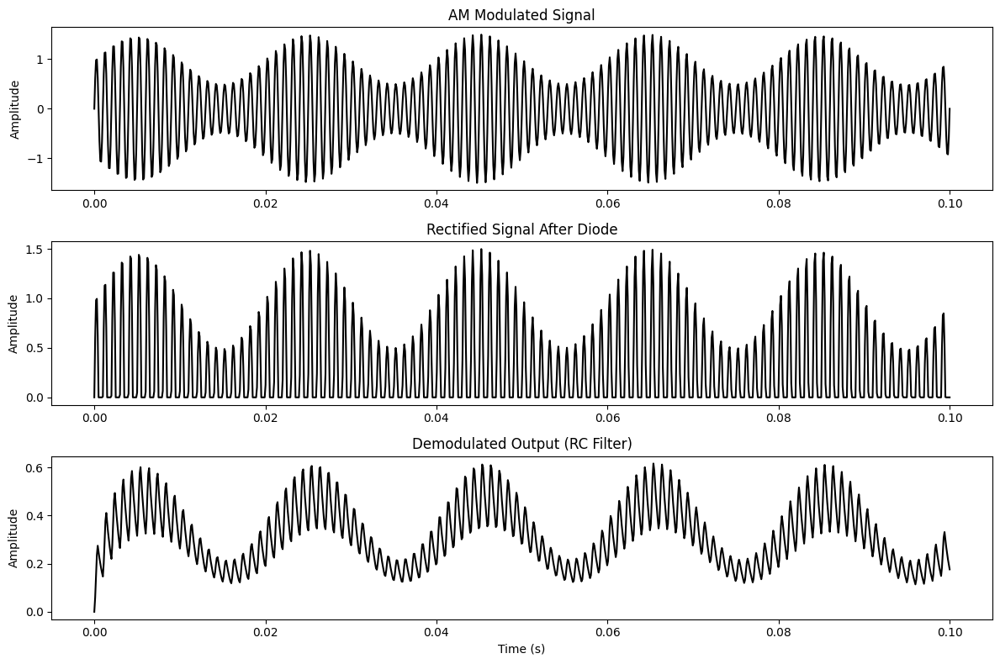

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
carrier_freq = 1000    # Hz (1 kHz carrier)
message_freq = 50      # Hz (50 Hz message)
mod_index = 0.5        # 50% modulation depth
sample_rate = 10000    # Samples per second
duration = 0.1         # Simulation duration (seconds)
R = 1000               # Resistor value (1kΩ)
C = 1e-6               # Capacitor value (1µF)

# Time array
t = np.linspace(0, duration, int(sample_rate * duration))

# Generate signals
message = np.sin(2 * np.pi * message_freq * t)        # Modulating signal
carrier = np.sin(2 * np.pi * carrier_freq * t)        # Carrier signal
am_signal = (1 + mod_index * message) * carrier       # AM modulated signal

# Diode rectification (half-wave)
rectified = np.clip(am_signal, 0, None)               # Simple diode model

# RC filter simulation
v_cap = np.zeros_like(rectified)
dt = 1 / sample_rate

for i in range(1, len(t)):
    dV = (rectified[i] - v_cap[i-1]) * dt / (R * C)
    v_cap[i] = v_cap[i-1] + dV

# Plot results
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, am_signal, color='black')
plt.title('AM Modulated Signal')
plt.ylabel('Amplitude')

plt.subplot(3, 1, 2)
plt.plot(t, rectified, color='black')
plt.title('Rectified Signal After Diode')
plt.ylabel('Amplitude')

plt.subplot(3, 1, 3)
plt.plot(t, v_cap, color='black')
plt.title('Demodulated Output (RC Filter)')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')

plt.tight_layout()
plt.show()


![](images/p4-164.JPG)

### Fig.4.16. Basic amplitude_modulation detector

of lower frequency $w_m$. The modulation index, $m$, is the fractional variation of $E$. For $m$ = 1 (100 per cent modulation), the envelope rises to 2$e_0$ and decreases to zero. The frequency spectrum shown in Fig. 4.16($b$) is a graph of the amplitude versus frequency of the three components of a simple a-m wave.

The basic rectifier circuit is a widely used a-m detector; almost every a-m radio receiver uses one. The output of a resistive rectifier circuit with an a-m signal input is shown in Fig. 4.16($c$).	Either the peak amplitude (envelope) or the average value of each half-cycle contains the variation due to the modulating signal. The use of a capacitor to smooth out the high-frequency variations is shown in Fig. 4.16($d$). To eliminate ripple and produce d-c output, we stated in Art. 4.3 that the capacitance $C$ should be made as large as possible. We now desire to remove as much of the ripple as possible while preserving the modulation frequency. This imposes conflicting requirements on the size of capaci- tance $C$, and therefore requires a compromise. As the amplitude of the modulated wave builds up, the capacitance $C$ is readily charged to nearly peak voltage by the diode. As the amplitude diminishes, the capacitance must discharge rapidly enough to follow the envelope.	Too large a capacitance results in $envelope distortion$, as indicated in Fig. 4.16($e$). Obviously, for $w_c$ >> $w_m$ op, the removal of ripple from the output can be made more complete without causing envelope distortion.

Let us consider in more detail the factors that in8uence the choice of an appropriate value for capacitance $C$.  To avoid envelope distortion, the downward slope of the exponential discharge of capacitance $C$ must exceed the downward slope of the modulation envelope. Assume the envelope to have reached a value $E_a$ at time $t_a$ during the downward swing as indicated in Fig. 4.17($a$), and assume that the capacitor $C$ has been charged to this peak value. Then the capacitor voltage during discharge is 


$e_c$=$E_a$ e$^-(t-$t_a$)$/$RC$  $(4.26)$

and the initial slope is


$d$ $e_c$ / $dt$ |$t$=$t_a$ = -$E_a$ /$RC$



= - $E$ (1+$m$ sin $w_m$ $t_a$) / $RC$   $(4.27)$


Let ua postulate that the design value of $RC$ will prove to be much larger than the period of the carrier frequency ($RC$ >> $T_c$, = 2π /$w_c$), so that the initial slope applies during the entire interval between carrier-frequency cycles. The slope of the modulation envelope is


$\frac {de}{dt}$=$m$ $w_m$ $E$ cos$w_m$t   $(4.28)$

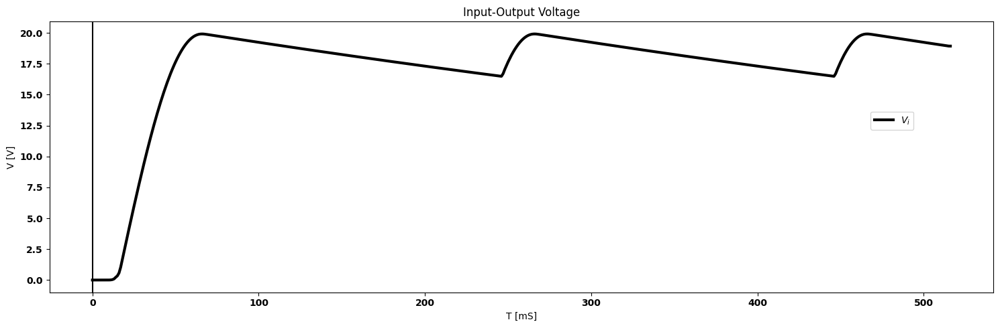

In [8]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
circuit = Circuit('Full-wave rectifier')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=20@u_V)
#circuit.SinusoidalVoltageSource(2, circuit.gnd, 'o1', amplitude=20@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.C(1, '2',circuit.gnd, 100@u_uF)
circuit.R(2, '2',circuit.gnd, 1@u_kOhm)
#circuit.C(2, '4',circuit.gnd, 1@u_uF)
#circuit.R(1, '4',circuit.gnd, 1@u_Ohm)
#circuit.D(2, 'o1','3', model = 'BAV21')
figure, ax1 = plt.subplots(figsize=(15, 5))
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.1@u_ms, end_time=0.05@u_s)

ax1.plot(analysis['2'],'black',linewidth=3)
#ax1.plot(analysis['o1'],'black',linewidth=5,linestyle='--') 
ax1.legend(('$V_i$','$V_o$',), loc=(.87,.6)) 
ax1.axvline(x=0, color='black') 
ax1.set_title('Input-Output Voltage') 

ax1.set_xlabel('T [mS]')
ax1.set_ylabel('V [V]')

plt.tight_layout()
plt.show()

![](images/p4-17.JPG)

To avoid distortion : $\frac {mw_m.Ecoswta}{-Ea/RC}$<1 ; $\frac {mw_m.Ecoswta}{-(1+msinwmta)}$<1

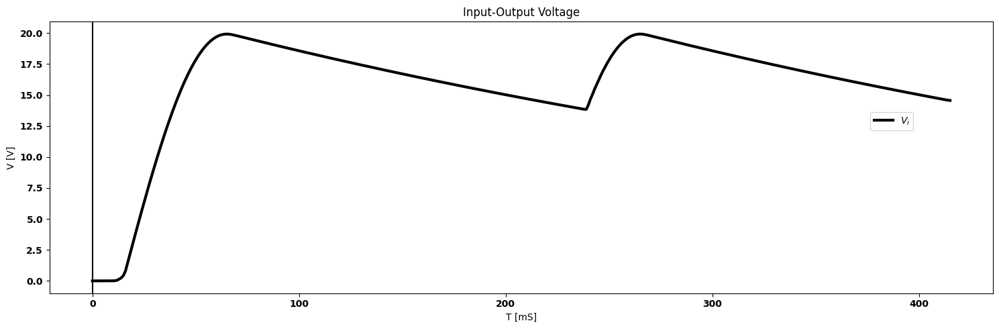

In [10]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()

from PySpice.Doc.ExampleTools import find_libraries
from PySpice.Probe.Plot import plot
from PySpice.Spice.Library import SpiceLibrary
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

rcParams['font.weight'] = 'bold'
circuit = Circuit('Full-wave rectifier')
circuit.model('BAV21','D' ,IS = 1@u_mA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm)
circuit.SinusoidalVoltageSource(1, '1', circuit.gnd, amplitude=20@u_V)
#circuit.SinusoidalVoltageSource(2, circuit.gnd, 'o1', amplitude=20@u_V)
circuit.D(1, '1','2', model = 'BAV21')
circuit.C(1, '2',circuit.gnd, 50@u_uF)
circuit.R(2, '2',circuit.gnd, 1000@u_Ohm)
#circuit.C(2, '4',circuit.gnd, 1@u_uF)
#circuit.R(1, '4',circuit.gnd, 1@u_Ohm)
#circuit.D(2, 'o1','3', model = 'BAV21')
figure, ax1 = plt.subplots(figsize=(15, 5))
simulator = circuit.simulator(temperature=25, nominal_temperature=25) 
analysis = simulator.transient(step_time=0.1@u_ms, end_time=0.04@u_s)

ax1.plot(analysis['2'],'black',linewidth=3)
#ax1.plot(analysis['o1'],'black',linewidth=5,linestyle='--') 
ax1.legend(('$V_i$','$V_o$',), loc=(.87,.6)) 
ax1.axvline(x=0, color='black') 
ax1.set_title('Input-Output Voltage') 

ax1.set_xlabel('T [mS]')
ax1.set_ylabel('V [V]')

plt.tight_layout()
plt.show()

![](images/p4-17a.JPG)

### fig.4.17.  Envelope distortion and ripple in diode detectors

To avoid distortion, therefore,


-$m$ $w_m$cos$w_m$ $t_a$ < 1+$m$ sin$w_m$ $t_a$ / $RC$   $(4.29)$


for the least favorable value of $w_m$, $t_a$




$RC$ ≤ $\frac {\sqrt{1-m^2}}{mw_m}$  $(4.30)$

Note that for $m$ = 1 the inequality cannot be satisfied no matter how small $RC$ is made ($RC$ = 0 is of no practical value). For $m$≈1, a small amount of envelope distortion will inevitably occur near minimum envelope amplitude, since the exponential slope approaches zero linearly with amplitude, whereas the slope of the envelope goes as a cosine function. The specific value of $RC$, then, is chosen on the basis of maximum modulation index $m$ and the maximum $w_m$ for which freedom from distortion is desired.
For $w_c$ ≫ $w_m$, ripple is relatively small; but if this condition does not hold, the ripple may dictate a lower limit for $RC$. The peak-to-peak ripple calculation is shown in Fig. 4.17($b$).


## 4.14	Square-Low Detection

Another method of detecting amplitude-modulated signals is called square-law detection. Any nonlinear curve can be represented by a power series expansion about a given point; and by proper selection of this operating point the square-law term can be enhanced. We shall therefore limit the present discussion to a square-law approximation. Introduction of higher-order terms refines the result, but adds to the algebraic complexity. Square-law detection is the fundamental process involved in frequency conversion or mixing. In addition, square-law analysis is useful for calculating harmonic distortion introduced by amplifiers or other circuits that are supposed to be linear.

Suppose the diode shown in Fig. 4.18 can be represented with reason- able accuracy by $i$ = $K$ $e^2$ over some range of $i$ and $e$. To obtain square- law detection the source and load resistances should be small so that the input voltage appears almost entirely across the diode and the current is proportional to the square of the voltage. (If $R$ were made very large, current and voltage would be nearly linearly related.)

Let us first consider a sine wave applied to the circuit. As shown in Fig. 4.18, a d-c bias is used to insure operation in the square-law region of the diode curve. The voltage $E_a$ produces a small d-c output voltage equal to $RKE_a^2$’. Application of the sinusoidal input of frequency $w_c$, results in an output at $w_c$ a double-frequency term at 2$w_c$ and an additional d-c term due to carrier rectification.

The sinusoidal input corresponds to an amplitude-modulated wave with $m$ = 0. Now, letting $m$ have nonzero values, we obtain more complicated waveforms and trigonometric expressions, as shown in Fig. 4.19. Considering the expression for $e_2$, after squaring the expres- sion within the bracket, we see that the first term $KRE_a^2$=$I_aR$ merely represents the quiescent d-c output. The next term is the original amplitude-modulated sine-wave input multiplied by 2$KRE_a^2$. For detection, the useful output comes from the last term designated by (A). The expansion for this term is shown in Fig. 4.19 as $e_2$ (A). The two terms in bold-face type represent the low-frequency output. The product terms, if fully expanded, would yield frequencies (2$w_c$ + $w_m$), (2$w_c$ - $w_m$) and (2$w_c$ + 2$w_m$), (2$w_c$ - 2$w_m$).	These, together with all

Text(0.5, 1.0, 'Original')

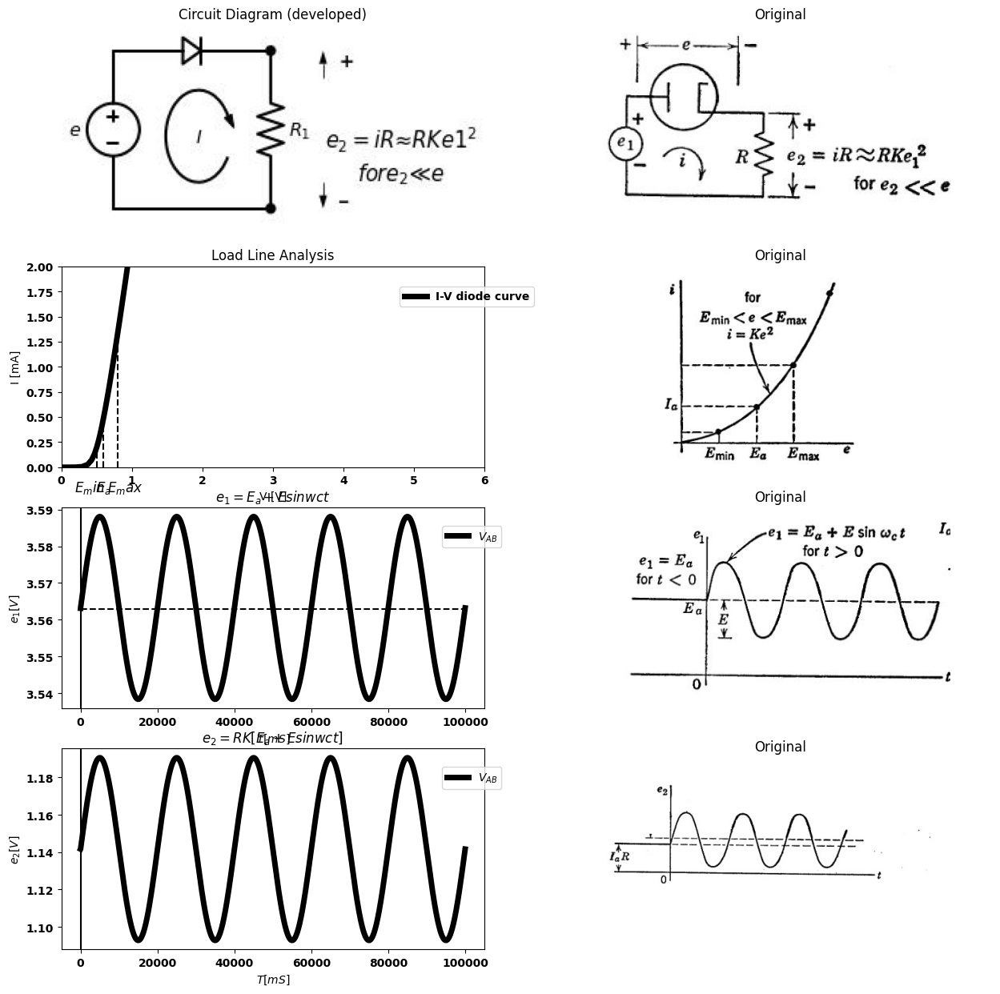

In [29]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e$ ','top' ))
d+= (D1 := elm.Diode()).right(d.unit*1).dot()
d += (R1 :=elm.Resistor().down().label('$R_1$' , 'bottom').dot())
d+= (L2:=elm.Line().left().length(3))
d += elm.LoopCurrent([D1,R1,L2,V] , pad = 0.5).label('$I$')
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,.5))
d += elm.Gap().up().label(  '$e_2= iR ≈ RK$$e1^2$\n$for e_2≪e$' , ofst=-3 , fontsize = 16).color('black').at((2.5,.1))
d.save('Drawings/4-18q.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-18q.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-18a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .7@u_V ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=5)

axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Load Line Analysis')
axs[1,0].text(.9,-.2, '$E_max$', ha='center', va='center', fontsize=12)
axs[1,0].text(.6,-.2, '$E_a$', ha='center', va='center', fontsize=12)
axs[1,0].text(.4,-.2, '$E_min$', ha='center', va='center', fontsize=12)
axs[1,0].plot([.8,.8],[0,1.25], color='black', linestyle='--', label='Membership = 0.9')
axs[1,0].plot([.6,.6],[0,.5], color='black', linestyle='--', label='Membership = 0.9')
axs[1,0].plot([.5,.5],[0,.25], color='black', linestyle='--', label='Membership = 0.9')
axs[1,0].set_xlim(0, 6)
axs[1,0].set_ylim(0, 2)
axs[1,0].set_xlabel('V [V]')
axs[1,0].set_ylabel('I [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-18b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
circuit.SinusoidalVoltageSource(1, 1, circuit.gnd, amplitude=0.05@u_V)
circuit.R(1, 1, 2, 1@u_kOhm)
circuit.I(1 ,circuit.gnd,2, 6@u_mA )
circuit.D(1, 2, '3', model = 'BAV21')
circuit.R(2, '3', 4, 1@u_kOhm)
circuit.V(2, 4, circuit.gnd, 1.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

axs[2,0].plot(analysis['3'],'black',linewidth=5)  
#axs[2,0].plot(analysis['4'],'black',linewidth=5,linestyle='--') 
axs[2,0].legend(('$V_{AB}$',), loc=(.9,.8))
axs[2,0].axvline(x=0, color='black')
axs[2,0].set_title('$e_1=E_a+Esinwct$')
axs[2,0].set_xlabel('$T [mS]$')
axs[2,0].plot([0,100000],[3.563,3.563], color='black', linestyle='--', label='Membership = 0.9')
axs[2,0].set_ylabel('$e_{1} [V]$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-18c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
rcParams['font.weight'] = 'bold'

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
circuit.SinusoidalVoltageSource(1, '1',' 11', amplitude=0.05@u_V)
circuit.R(1, '2',circuit.gnd, 1@u_kOhm)
#circuit.I(1 ,circuit.gnd,2, 6@u_mA )
circuit.D(1, '1', '2', model = 'BAV21')
#circuit.R(2, '3', 4, 1@u_kOhm)
circuit.V(2, 11, circuit.gnd, 1.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)

axs[3,0].plot(analysis['2'],'black',linewidth=5)  
axs[3,0].legend(('$V_{AB}$',), loc=(.9,.8))
axs[3,0].axvline(x=0, color='black')
axs[3,0].set_title('$e_2=RK[E_a+Esinwct]$')
axs[3,0].set_xlabel('$T [mS]$')
axs[3,0].set_ylabel('$e_{2} [V]$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-18d.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

### Fig.4.18.  Square-law rectification of a aine wave.

terms other than the two low-frequency terms and the d-c term, can be removed from the output by means of a low-pass filter. A capacitor $C$ with negligible reactance at carrier frequency (1/$w_c C$ ≪ $R$), but large reactance at modulation frequency (1/$w_c C$ ≫ $R$), would suffice. The frequency spectrum shown in Fig. 4.19 places in evidence each term of the trigonometric expansion of $e_2$ ($t$). It is much more readily drawn than the time function, and helps in visualizing the frequency distribu- tion and relative amplitudes of the individual sinusoidal terms.

Actually, the desired output is $KRE^2 m$ sin $w_m t$ sin nut. For a sinusoidal modulating signal, the second-harmonic term $KRE^2 m$($m^2/4$) cos 2$w_mt$ may often be largely eliminated from the output by a suitable filter. However, if the modulation extends over a range of frequencies (as, for example, the speech or music broadcast by a radio station), then harmonic distortion is inevitable. The ratio of the undesired term to the desired term is $m/4$; thus the square-law detector must be used in

Text(0.5, 1.0, 'Original')

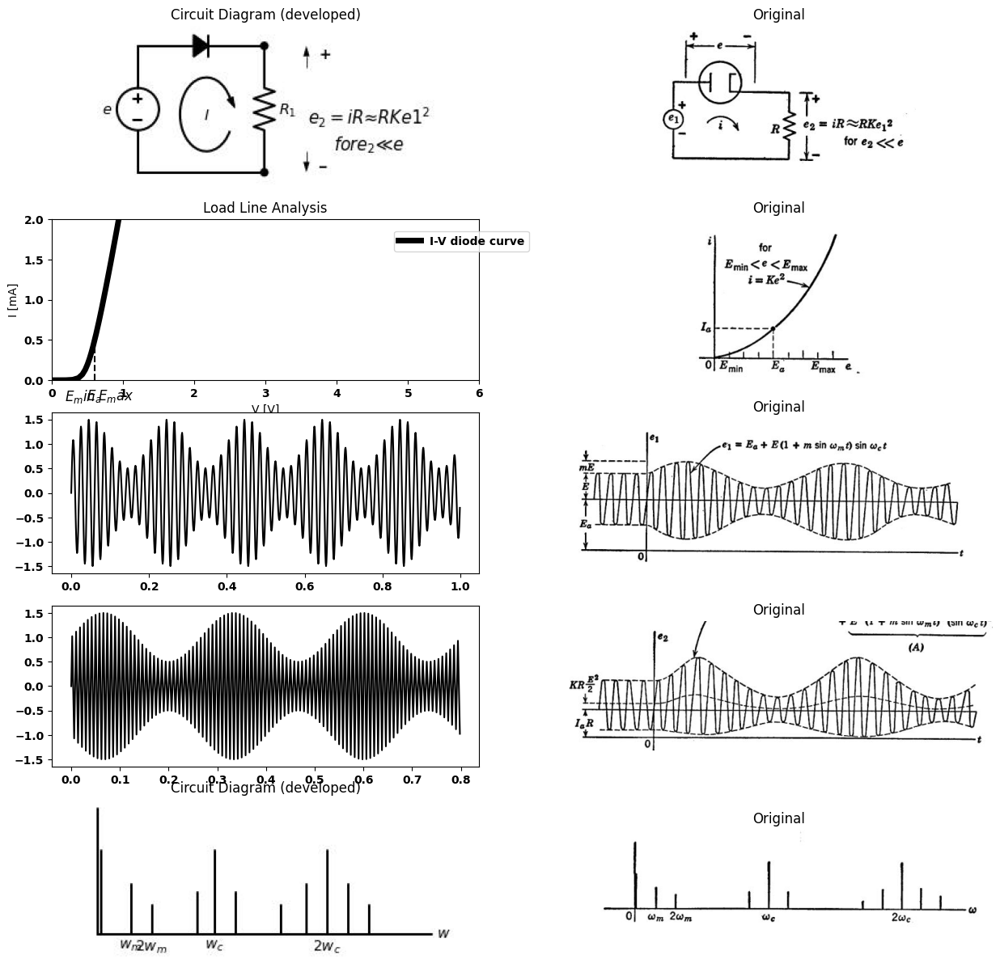

In [45]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(5, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e$ ','top' ))
d+= (D1 := elm.Diode(fill=True)).right(d.unit*1).dot()
d += (R1 :=elm.Resistor().down().label('$R_1$' , 'bottom').dot())
d+= (L2:=elm.Line().left().length(3))
d += elm.LoopCurrent([D1,R1,L2,V] , pad = 0.5).label('$I$')
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,.5))
d += elm.Gap().up().label(  '$e_2= iR ≈ RK$$e1^2$\n$for e_2≪e$' , ofst=-3 , fontsize = 16).color('black').at((2.5,.1))
d.save('Drawings/4-19.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-19.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-19.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'

circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 14.5@u_nA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = .7@u_V ,CJO = 7.048E-13 ,RS = 180@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 10@u_V)
circuit.R(1, '1', '2', 1@u_kOhm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 25, 0.1))
axs[1,0].plot(analysis['2'], u_mA(-analysis.Vi),'black',linewidth=5)

axs[1,0].legend(('I-V diode curve','diode equation'), loc=(.8,.8))
axs[1,0].set_title('Load Line Analysis')
axs[1,0].text(.9,-.2, '$E_max$', ha='center', va='center', fontsize=12)
axs[1,0].text(.6,-.2, '$E_a$', ha='center', va='center', fontsize=12)
axs[1,0].text(.4,-.2, '$E_min$', ha='center', va='center', fontsize=12)
#ax1.plot([.8,.8],[0,1.25], color='black', linestyle='--', label='Membership = 0.9')
axs[1,0].plot([.6,.6],[0,.5], color='black', linestyle='--', label='Membership = 0.9')
#ax1.plot([.5,.5],[0,.25], color='black', linestyle='--', label='Membership = 0.9')
axs[1,0].set_xlim(0, 6)
axs[1,0].set_ylim(0, 2)
axs[1,0].set_xlabel('V [V]')
axs[1,0].set_ylabel('I [mA]')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-19a.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
carrier_frequency = 50  # Hz
message_frequency = 5   # Hz
modulation_index = 0.5  # 50% modulation
sample_rate = 1000      # Hz
duration = 1            # second

# Generate time array
t = np.arange(0, duration, 1/sample_rate)

# Generate carrier signal
carrier_signal = np.sin(2 * np.pi * carrier_frequency * t)

# Generate message signal
message_signal = np.sin(2 * np.pi * message_frequency * t)

# Generate AM modulated signal
am_signal = carrier_signal * (1 + modulation_index * message_signal)

axs[2,0].plot(t, am_signal,color='black')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-19b.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
# Parameters
carrier_frequency = 50  # Hz
message_frequency = 1.5   # Hz
modulation_index = 0.5  # 50% modulation
sample_rate = 500      # Hz
duration = .8            # second

# Generate time array
t = np.arange(0, duration, 1/sample_rate)

# Generate carrier signal
carrier_signal = np.sin(5 * np.pi * carrier_frequency * t)

# Generate message signal
message_signal = np.sin(5 * np.pi * message_frequency * t)

# Generate AM modulated signal
am_signal = carrier_signal * (1 + modulation_index * message_signal)

# Plot signals
axs[3,0].plot(t, am_signal,color='black')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-19c.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')
d = schemdraw.Drawing()
d+=(l1 :=elm.Line().right().length(8).label('$w$ ','right' ))
d+=(l2:= elm.Line().up().length(3).at(l1.start))
d+=(l3:= elm.Line().up().length(2).at((0.08,0)))
d+=(l4:= elm.Line().up().length(1.2).at((0.8,0)).label('$w_m$ ','left' ))
d+=(l4:= elm.Line().up().length(0.7).at((1.3,0)).label('$2w_m$ ','left' ))
d+=(l3:= elm.Line().up().length(1).at((2.38,0)))
d+=(l4:= elm.Line().up().length(2).at((2.8,0)).label('$w_c$ ','left' ))
d+=(l4:= elm.Line().up().length(1).at((3.3,0)))
d+=(l3:= elm.Line().up().length(.7).at((4.38,0)))
d+=(l4:= elm.Line().up().length(1.2).at((5,0)))
d+=(l4:= elm.Line().up().length(2).at((5.5,0)).label('$2w_c$ ','left' ))
d+=(l4:= elm.Line().up().length(1.2).at((6,0)))
d+=(l4:= elm.Line().up().length(.7).at((6.5,0)))
d.save('Drawings/4-19f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/4-19f.jpg')
axs[4, 0].imshow(img)
axs[4, 0].axis('off')  # Hide axes for image display
axs[4, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-19d.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

$e2_A$= $RKE^2$ $[1+2msinwt+ \frac{m^2}{2}- \frac{m^2}{2}cos 2w_mt]$ $[\frac {1}{2}- \frac {1}{2}cos 2w_ct]$



= $RKE^2$ $[\frac {1}{2}+msinwt+ \frac{m^2}{4}- \frac{m^2}{4}cos 2w_ct - \frac {1}{2}cos 2w_ct-msinwt.cos 2w_ct- \frac{m^2}{4}cos 2w_ct +\frac{m^2}{4}cos 2w_mtcos 2w_ct]$


### Fig.4.19. Square-law detection of an a-m sine wave.

applications where the modulation index of the applied wave is likely to be small.


## 4.15 Balanced Modulotor Circuits

Modulation of a time function ct (t) by another time function ct(t) is a nonlinear process. The resulting modulated wave contains frequencies that were not present in the original time functions.  If the two time

In [7]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
        d+= (l1:=elm.Line().right().length(2))
        d += (L1:=elm.Inductor2().down(d.unit*1))
        d+= (l2:=elm.Line().left().length(2))
        d+= (l3:=elm.Line().down().length(4).at((2.5,3.5)))
        d+= (l4:=elm.Line().down().length(4).at((2.8,3.5)))
        d += (L2:=elm.Inductor2().down(d.unit*1).at((3.2,4)).reverse())
        d += (L3:=elm.Inductor2().down(d.unit*1))
        d += (R1 :=elm.Resistor().right(d.unit*1.5).label('$r_A$' , 'top').at(L2.start))
        d+= (D1 := elm.Diode(fill=True)).right(d.unit*1).label('$D_A$' , 'top')
        d += (V1:=elm.SourceV().right(d.unit*1.5).label('$e_2$ ','top' ).at(L2.end).reverse())
        d += (R2 :=elm.Resistor().right().label('$R_o$' , 'top').label('$-   e_o    +$' , 'bottom'))
        d += elm.Ground().at(V1.end)
        d+= (l5:=elm.Line().down().length(6).at(D1.end))
        d += (R2 :=elm.Resistor().left(d.unit*1.5).label('$r_B$' , 'top'))
        #d+= (D2 := elm.Diode(fill=True)).left(d.unit*1).label('$D_B$' , 'top')
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,3.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,1.5))
        d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,1))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,-1.5))
        d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,-1.5))
        if (Mode):
            d += elm.Diode(fill=True).left().label('$D_B$').dot().at(R2.end)
        else:
            d += elm.Diode(fill=True).left().reverse().label('$D_B$').dot().at(R2.end)

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

In [8]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
        d+= (l1:=elm.Line().right().length(2))
        d += (L1:=elm.Inductor2().down(d.unit*1))
        d+= (l2:=elm.Line().left().length(2))
        d+= (l3:=elm.Line().down().length(4).at((2.5,3.5)))
        d+= (l4:=elm.Line().down().length(4).at((2.8,3.5)))
        d += (L2:=elm.Inductor2().down(d.unit*1).at((3.2,4)).reverse())
        d += (L3:=elm.Inductor2().down(d.unit*1))
        d += (D1 :=elm.Diode(fill=True).right(d.unit*1.5).label('$D_A$' , 'top').at(L2.start))
        d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top'))
        d += (V1:=elm.SourceV().left(d.unit*1.5).label('$e_2$ ','top' ))
        d += elm.Ground().at(V1.start).up()
        d += (R2 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top').at(R1.end))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,3.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,1.5))
        d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,1))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((4,.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((4,-1.5))
        d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,-1.5))
        d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9,3))
        d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9,-1))
        d += elm.Gap().up().label(  '$e_0$' , ofst=-1.7 , fontsize = 16).color('black').at((7.5,0))
        if (Mode):
            d += elm.Diode(fill=True).left(d.unit*1.5).label('$D_B$').dot().at(R2.end).reverse()
        else:
            d += elm.Diode(fill=True).left(d.unit*1.5).label('$D_B$').dot().at(R2.end)

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/p4-20.JPG)

### Fig.4.20.   Balanced modulator and demodulator circuits

functions are sine waves of angular frequency $w_1$ and $w_2$, the modulated wave may contain frequencies $w_1$ and $w_2$, ($w_1$ + $w_2$) and ($w_1$ — $w_2$). 2$w_1$, 2$w_2$ and many others. The components present in the frequency spectrum of the output depend upon the circuit and the degree of nonlinearity.
Demodulation (detection) is a variation of the modulation process, usually aimed at recovering one of the signals in a modulated wave.


Both the diode detector and the square-law circuit carry out the demodulation process by rectifying and then filtering the modulated wave.  When a low-frequency signal is to be recovered, the required

Text(0.5, 1.0, 'Original')

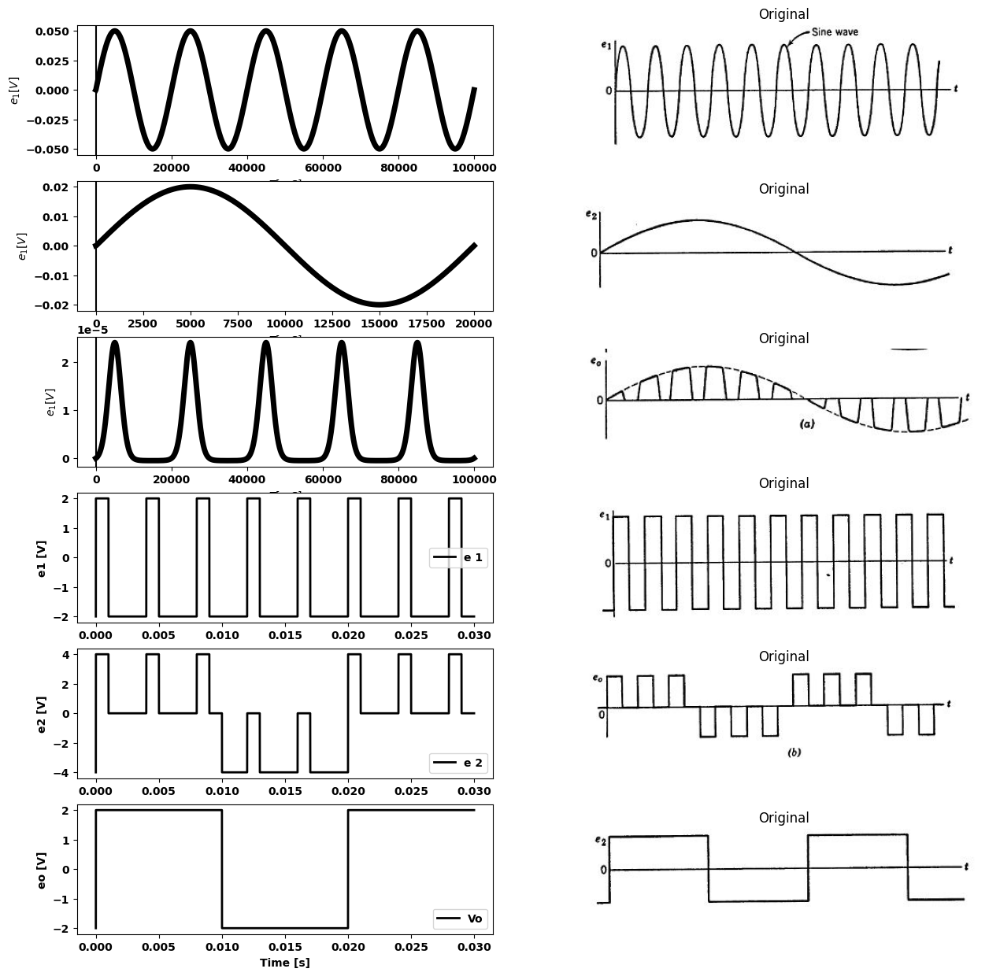

In [36]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(6, 2, figsize=(15, 15))
d = schemdraw.Drawing()
rcParams['font.weight'] = 'bold'

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
circuit.SinusoidalVoltageSource(1, 1, circuit.gnd, amplitude=0.05@u_V)
circuit.R(1, 1, 2, 1@u_kOhm)
circuit.I(1 ,circuit.gnd,2, 6@u_mA )
circuit.D(1, 2, '3', model = 'BAV21')
circuit.R(2, '3', 4, 1@u_kOhm)
circuit.V(2, 4, circuit.gnd, 1.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[0,0].plot(analysis['1'],'black',linewidth=5)  
axs[0,0].axvline(x=0, color='black')
axs[0,0].set_xlabel('$T [mS]$')
axs[0,0].set_ylabel('$e_{1} [V]$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21`a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
circuit.SinusoidalVoltageSource(1, 1, circuit.gnd, amplitude=0.02@u_V)
circuit.R(1, 1, 2, 1@u_kOhm)
circuit.I(1 ,circuit.gnd,2, 6@u_mA )
circuit.D(1, 2, '3', model = 'BAV21')
circuit.R(2, '3', 4, 1@u_kOhm)
circuit.V(2, 4, circuit.gnd, 1.5@u_V)
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.02@u_s)
axs[1,0].plot(analysis['1'],'black',linewidth=5)  
axs[1,0].axvline(x=0, color='black')
axs[1,0].set_xlabel('$T [mS]$')
axs[1,0].set_ylabel('$e_{1} [V]$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21b.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
rcParams['font.weight'] = 'bold'

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
circuit.SinusoidalVoltageSource(2, '1', circuit.gnd, amplitude=0.05@u_V)
circuit.SinusoidalVoltageSource(1, '2', '1', amplitude=0.05@u_V)
circuit.SinusoidalVoltageSource(3, '1', '6', amplitude=0.05@u_V)
circuit.R(1, '2', '3', 100@u_Ohm)
circuit.R(3, '4', '5', 200@u_Ohm)
circuit.D(1, '3', '4', model = 'BAV21')
circuit.R(2, '4',circuit.gnd, 500@u_Ohm)
circuit.D(2, '5', '6', model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=0.001@u_ms, end_time=0.1@u_s)
axs[2,0].plot(analysis['4'],'black',linewidth=5)  
axs[2,0].axvline(x=0, color='black')
axs[2,0].set_xlabel('$T [mS]$')
axs[2,0].set_ylabel('$e_{1} [V]$')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21c.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')

circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=1@u_ms, period=4@u_ms)
pulse2 = circuit.PulseVoltageSource('V2', '2', '1', initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
pulse1 = circuit.PulseVoltageSource('V3', '1', '6', initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=1@u_ms, period=4@u_ms)
pulse3 = circuit.PulseVoltageSource('V4', '8',  circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
circuit.R(1, '2', '3', 100@u_Ohm)
circuit.R(3, '4', '5', 200@u_Ohm)
circuit.D(1, '3', '4', model = 'BAV21')
circuit.R(2, '4',circuit.gnd, 500@u_Ohm)
circuit.D(2, '5', '6', model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=30@u_ms)
axs[3,0].plot(analysis.time, analysis['1'], 'black', linewidth=2, label='e 1')
axs[3,0].set_ylabel('e1 [V]', color='black', weight='black', fontsize=10)
axs[3,0].legend()

axs[4,0].plot(analysis.time, analysis['2'], 'black', linewidth=2, label='e 2')
axs[4,0].set_ylabel('e2 [V]', color='black', weight='black', fontsize=10)
axs[4,0].legend()

axs[5,0].plot(analysis.time, analysis['8'], 'black', linewidth=2, label='Vo')
axs[5,0].set_xlabel('Time [s]', color='black', weight='black', fontsize=10)
axs[5,0].set_ylabel('eo [V]', color='black', weight='black', fontsize=10)
axs[5,0].legend()
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21D.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21G.jpg')  # Load the PNG file
axs[4,1].imshow(img_sample)
axs[4,1].axis('off')  # Hide axes for image display
axs[4,1].set_title('Original')

# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21F.jpg')  # Load the PNG file
axs[5,1].imshow(img_sample)
axs[5,1].axis('off')  # Hide axes for image display
axs[5,1].set_title('Original')


### Fig. 4.21.  Waveforms for the circuit of Fig. 4.20($a$).

filter is low-pass and may be a simple smoothing capacitor. A band-pass filter is used if one desires to select a particular high-frequency component of the modulated wave.  Such a filter might well consist of a
parallel $RLC$ circuit resonant at the desired frequency.


Balanced modulator or demodulator circuits make use of symmetry to eliminate undesired frequency components. These circuits are sometimes called keyed rectifiers since they are full-wave rectifiers with two input signals. See Fig. 4.20. The important point to observe is that in all of the circuits one input is applied to the diodes symmetrically, whereas the other is applied antisymmetrically. The character of the input signals and the degree of diode nonlinearity determine which of several functions such a circuit performs. Among the possibilities are suppressed-carrier modulation, synchronous detection, pulse-amplitude modulation, waveform sampling, and phase sensing.

In the circuit of Fig. 4.20($a$) the source $e_1$ alone tends to switch both diodes on and off together. The small resistance $r_A$ and $r_B$ may be actual diode resistances or resistances added to the circuit to improve balance so that $e_1$ alone yields no output. The source $e_2$ alone appears directly at the output (or nearly so for $r_A$ and $r_B$ <<$R_0$). When $e_2$ is positive $D_A$  conducts and when $e_2$ is negative $D_B$ conducts.

With both $e_1$ and $e_2$ applied to the circuit at the same time we note that conduction through $D_A$ depends on ($e_1$ + $e_2$), whereas conduction through $D_B$  depends on ($e_1$ — $e_2$). Output waveforms for two different sets of input waveforms are shown in Fig. 4.21 ($a$) and ($b$). In both cases |$e_1$| > |$e_2$|.

The circuit of Fig. 4.20($b$) is like that of ($a$) but with ideal diode $D_B$ reversed. Reversing a diode, in effect, interchanges the roles of $e_1$ and $e_2$, since now $e_2$ drives the two diodes on and off simultaneously, while $e_1$, alternately causes conduction through one diode and then the other. With $e_2$ alone applied, $e_0$ is a half-wave rectified version of $e_2$, whereas
in the circuit of ($a$),   appears directly at $e_0$.  The circuits shown in
Fig. 4.20($a$) and ($b$) have a common ground terminal for the output and one of the sources. The circuits in ($c$) and ($d$) have a balanced output with respect to ground.

## SUPPLEMENTARY READING

L. B. Arguimbau, R. B. Adler, $Vacuum Tube Circuits and  Transistor$, John Wiley and Sons, New York, 1956.

B. Chance, $Waveforms$ , McGraw-Hill, New York, 1948.

T. S. Grey, $Applied Electronics$ , 2nd edition, John Wiley and Sons, New York, 1954.

E. A. Guillemin, $Introductory Circuit Theory$, John Wiley and Sons, New York, 1953.

J. Millman and H. Taub, $Pulse and Digital Circuits$, McGraw-Hill, New York, 1956. 

Samuel Seely, $Electronic Engineering$, McGraw-Hill, New York, 1956.

Samuel Seely, $Radio Electronics$, McGraw Hill, New York, 1956.

## PROBLEMS

4.1.	Given the input $e_1$($t$) of Fig. P4.1, find the steady-state waveform of $e_2$($t$) for each of the circuits shown in Figs. P4.2—P4.7.

Text(0.5, 1.0, 'Original')

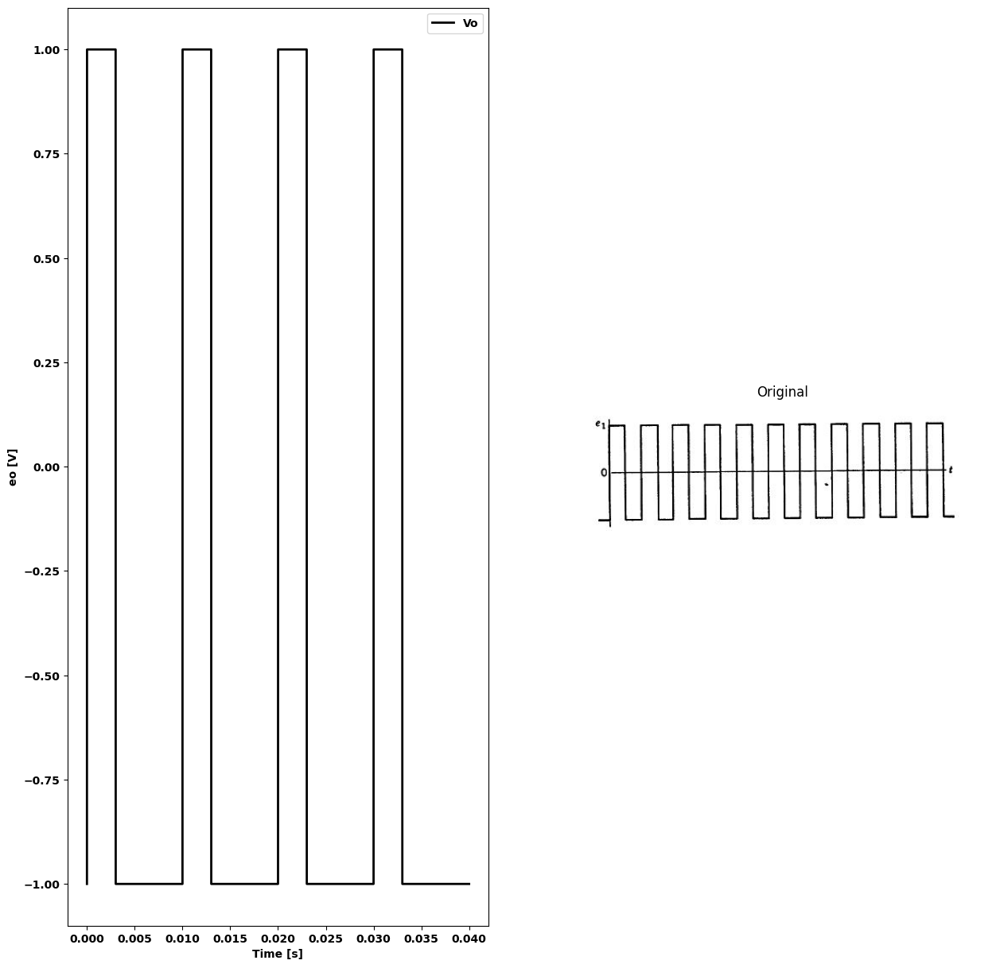

In [39]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
circuit = Circuit('Q3')
circuit.model('BAV21','D' ,IS = 1@u_nA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 0.001@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=1@u_ms, period=4@u_ms)
pulse2 = circuit.PulseVoltageSource('V2', '2', '1', initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=10@u_ms, period=20@u_ms)
pulse1 = circuit.PulseVoltageSource('V3', '1', '6', initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=1@u_ms, period=4@u_ms)
pulse3 = circuit.PulseVoltageSource('V4', '8',  circuit.gnd, initial_value=-1@u_V, pulsed_value=1@u_V, pulse_width=3@u_ms, period=10@u_ms)
circuit.R(1, '2', '3', 100@u_Ohm)
circuit.R(3, '4', '5', 200@u_Ohm)
circuit.D(1, '3', '4', model = 'BAV21')
circuit.R(2, '4',circuit.gnd, 500@u_Ohm)
circuit.D(2, '5', '6', model = 'BAV21')

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=40@u_ms)
axs[0].plot(analysis.time, analysis['8'], 'black', linewidth=2, label='Vo')
axs[0].set_xlabel('Time [s]', color='black', weight='black', fontsize=10)
axs[0].set_ylabel('eo [V]', color='black', weight='black', fontsize=10)
axs[0].legend()
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/p4-21D.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

In [9]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response(Mode=True):

    with schemdraw.Drawing() as d:
        d+= (l1:=elm.Line().right().length(.1).dot(open=True))
        d+= (l2:=elm.Line().right().length(1))
        d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top').at((5.6,0)))
        d+= (l3:=elm.Line().left().length(5.5).dot(open=True))
        d+= (l4:=elm.Line().right().length(1).dot(open=True).at(R1.start))
        d+= (l5:=elm.Line().right().length(1).dot(open=True).at(R1.end))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((0,-.7))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((0,-2.3))
        d += elm.Gap().up().label(  '$e_1$$_(t)$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.5,-2.75))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,-.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,-2.5))
        d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5,-2.75))
        if (Mode):
            d += (D1:= elm.Diode(fill=True).right(d.unit*1.5).at(l2.end).reverse())
        else:
            d +=(D1:= elm.Diode(fill=True).right(d.unit*1.5).at(l2.end))

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/K4-2.JPG)

In [10]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact(Mode=(True))
def response(  Mode=True):

    with schemdraw.Drawing() as d:
        d+= (l1:=elm.Line().right().length(.1).dot(open=True))
        d+= (l2:=elm.Line().right().length(1))
        d += (R1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top').at((5.6,0)))
        d+= (l3:=elm.Line().left().length(5.5).dot(open=True))
        d+= (l4:=elm.Line().right().length(1).dot(open=True).at(R1.start))
        d+= (l5:=elm.Line().right().length(1).dot(open=True).at(R1.end))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((0,-.7))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((0,-2.3))
        d += elm.Gap().up().label(  '$e_1$$_(t)$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.5,-2.75))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,-.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,-2.5))
        d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5,-2.75))
        if (Mode):
            d += (D1:= elm.Diode(fill=True).right(d.unit*1.5).at(l2.end).reverse())
        else:
            d +=(D1:= elm.Diode(fill=True).right(d.unit*1.5).at(l2.end))

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/P4-3.JPG)

In [11]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        d+= (l1:=elm.Line().right().length(.1).dot(open=True))
        d+= (l2:=elm.Line().right().length(1))
        d += (R1 :=elm.Capacitor().right(d.unit*1.5).label('$C$' , 'top'))
        d+= (l3:=elm.Line().left().length(5.5).dot(open=True).at((5.6,-3)))
        d+= (l4:=elm.Line().right().length(1).dot(open=True).at((5.6,0)))
        d+= (l5:=elm.Line().right().length(1).dot(open=True).at(l3.start))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((0,-.7))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((0,-2.3))
        d += elm.Gap().up().label(  '$e_1$$_(t)$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.5,-2.75))
        d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,-.5))
        d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,-2.5))
        d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((5,-2.75))
        if (Mode):
            d += (D1:= elm.Diode(fill=True).down(d.unit*1).at(R1.end))
        else:
            d +=(D1:= elm.Diode(fill=True).down(d.unit*1).at(R1.end).reverse())

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/P4-4.JPG)

4.2. Sketch $e_2$ ($t$) for the diode circuits shown in Figs. P4.8—P4.l4, assuming that $wRC$ is much larger than unity so that the capacitor ripple voltage is negligible.

Text(0.5, 1.0, 'Original')

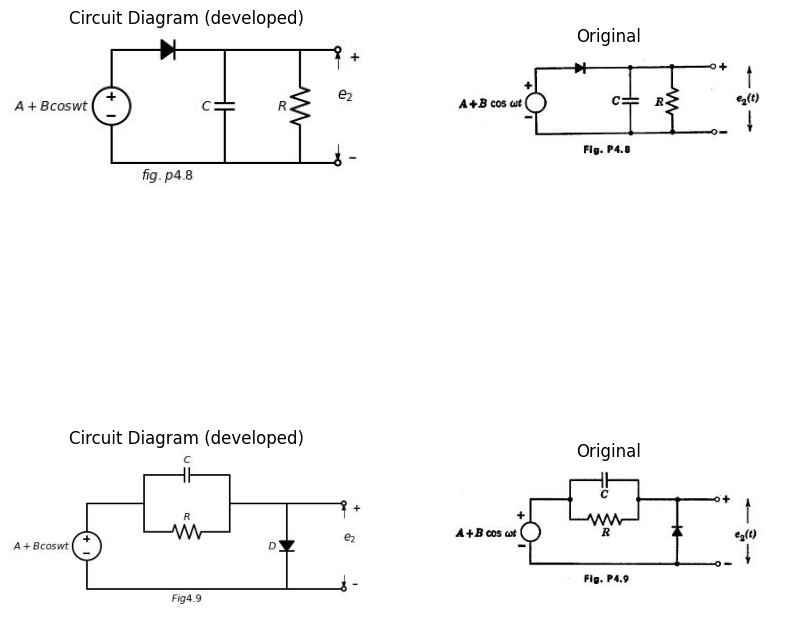

In [48]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
d+= (D1 := elm.Diode(fill=True)).right(d.unit*1)
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
d+= (l1:=elm.Line().left().length(3).label('$fig.p4.8$' , 'bottom'))
d+= (l2:=elm.Line().right().length(2).at(C1.start))
d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top'))
d+= (l3:=elm.Line().left().length(2))
d+= (l1:=elm.Line().right().length(1).dot(open=True).at(R1.start))
d+= (l1:=elm.Line().right().length(1).dot(open=True).at(R1.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.5,.5))
d.save('Drawings/P4-8.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/P4-8.jpg')
axs[0, 0].imshow(img)
axs[0, 0].axis('off')  # Hide axes for image display
axs[0, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/Fp4-8.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
d+= (l1:=elm.Line().right().length(2))
d+= (l2:=elm.Line().up().length(1))
d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$' , 'top'))
d+= (l3:=elm.Line().down().length(1))
d+= (l4:=elm.Line().down().length(1))
d += (R1 :=elm.Resistor().left(d.unit*1).label('$R$' , 'top'))
d+= (l5:=elm.Line().up().length(1))
d+= (l6:=elm.Line().right().length(2).at(l3.end))
d += (D1 :=elm.Diode(fill=True).down(d.unit*1).label('$D$' , 'top'))
d+= (l7:=elm.Line().left().length(7).label('$Fig4.9$' , 'bottom'))
d+= (l8:=elm.Line().right().length(2).at(D1.start).dot(open=True))
d+= (l9:=elm.Line().right().length(2).at(D1.end).dot(open=True))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((7.5,.5))
d.save('Drawings/P4-9.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/P4-9.jpg')
axs[1, 0].imshow(img)
axs[1, 0].axis('off')  # Hide axes for image display
axs[1, 0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/Fp4-9.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

In [12]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        if (Mode):
            d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
            d += (C1 :=elm.Capacitor().right(d.unit*1.5).label('$C$' , 'top'))
            d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top'))
            d+= (l1:=elm.Line().left().length(4.5).label('$Fig4.10$' , 'bottom'))
            d+= (l2:=elm.Line().right().length(2).at(R1.start).dot(open=True))
            d+= (l2:=elm.Line().right().length(2).at(R1.end).dot(open=True))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.5,.5))

        else: 
            d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
            d += (R1 :=elm.Resistor().right(d.unit*1.5).label('$R$' , 'top'))
            d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
            d+= (l1:=elm.Line().left().length(4.5).label('$Fig4.11$' , 'bottom'))
            d+= (l2:=elm.Line().right().length(2).at(C1.start).dot(open=True))
            d+= (l2:=elm.Line().right().length(2).at(C1.end).dot(open=True))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((6.5,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((6.5,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((4.5,.5))
     

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/FP4-10.JPG)

Text(0.5, 1.0, 'Original')

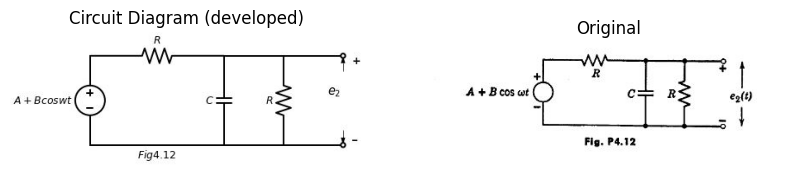

In [50]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
d += (R1 :=elm.Resistor().right(d.unit*1.5).label('$R$' , 'top'))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
d+= (l1:=elm.Line().left().length(4.5).label('$Fig4.12$' , 'bottom'))
d+= (l2:=elm.Line().right().length(2).at(C1.start))
d += (R2 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top'))
d+= (l2:=elm.Line().left().length(2))
d+= (l2:=elm.Line().right().length(2).at(R2.start).dot(open=True))
d+= (l2:=elm.Line().right().length(2).at(R2.end).dot(open=True))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((8.5,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((8.5,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,.5))
d.save('Drawings/5FP4-12.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-12.jpg')
axs[ 0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/FP4-12.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

In [13]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        if (Mode):
            d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
            d+= (l1:=elm.Line().right().length(2))
            d+= (l2:=elm.Line().up().length(1))
            d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$' , 'top'))
            d+= (l3:=elm.Line().down().length(1))
            d+= (l4:=elm.Line().down().length(1))
            d += (R1 :=elm.Resistor().left(d.unit*1).label('$R$' , 'top'))
            d+= (l5:=elm.Line().up().length(1))
            d+= (l6:=elm.Line().right().length(2).at(l3.end))
            d += (D1 :=elm.Diode(fill=True).down(d.unit*1).label('$D$' , 'top').reverse())
            d+= (l7:=elm.Line().left().length(7).label('$Fig4.13$' , 'bottom'))
            d += (R2 :=elm.Resistor().right(d.unit*1).label('$R$' , 'top').at(D1.start))
            d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
            d+= (l8:=elm.Line().left().length(3))
            d+= (l2:=elm.Line().right().length(2).at(C2.start).dot(open=True))
            d+= (l2:=elm.Line().right().length(2).at(C2.end).dot(open=True))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((12,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((12,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((10.5,.5))
        else:
            d += (V:=elm.SourceV().up(d.unit*1).label('$A+Bcoswt$ ','top' ))
            d+= (l1:=elm.Line().right().length(2))
            d+= (l2:=elm.Line().up().length(1))
            d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$' , 'top'))
            d+= (l3:=elm.Line().down().length(1))
            d+= (l4:=elm.Line().down().length(1))
            d += (R1 :=elm.Resistor().left(d.unit*1).label('$R$' , 'top'))
            d+= (l5:=elm.Line().up().length(1))
            d+= (l6:=elm.Line().right().length(2).at(l3.end))
            d += (D1 :=elm.Diode(fill=True).down(d.unit*1).label('$D$' , 'top').reverse())
            d+= (l7:=elm.Line().left().length(7).label('$Fig4.14$' , 'bottom'))
            d += (D2 :=elm.Diode(fill=True).right(d.unit*1).label('$D$' , 'top').at(D1.start))
            d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
            d+= (l8:=elm.Line().left().length(3))
            d+= (l2:=elm.Line().right().length(2).at(C2.start))
            d += (R2 :=elm.Resistor().down(d.unit*1).label('$R$' , 'top'))
            d+= (l8:=elm.Line().left().length(3))
            d+= (l2:=elm.Line().right().length(2).at(R2.start).dot(open=True))
            d+= (l2:=elm.Line().right().length(2).at(R2.end).dot(open=True))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((14,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((14,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((12.5,.5))
             
          


interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/5FP4-14.JPG)

4.3.	The input voltage $e_1$,($t$) is a periodic square wave of peak-to-peak am- plitude 2$E_1$, and period $T$. Assume that $RC$ is many times larger than the period of the square wave. Find the approximate peak-to-peak ripple voltage in the output $e_2$($t$), expressed as a percentage of the d-c output voltage for ($a$) the circuit of Fig. P4.15, ($b$) the circuit of Fig. P4.15 with a resistance $R$ in parallel with the capacitor, ($c$) the circuit of Fig. P4.15 with a resistance $R$ in parallel with the diode, ($d$) the circuit of Fig. P4.16, and ($e$) the circuit of Fig. P4.16 with an additional resistance $R$ across the $e_2$ terminals.


In [14]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        if (Mode):
            d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
            d+= (l1:=elm.Line().right().length(1).dot(open=True))
            d+= (l2:=elm.Line().right().length(1).at(V.start).dot(open=True))
            d += (D1 :=elm.Diode(fill=True).right(d.unit*1).at(l1.end))
            d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
            d+= (l3:=elm.Line().left().length(3).label('$Fig4.15$' , 'bottom'))
            d+= (l4:=elm.Line().right().length(1).at(C1.start))
            d+= (l5:=elm.Line().right().length(1).at(C1.end))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((5,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((3.5,.5))
        else:
            d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
            d+= (l1:=elm.Line().right().length(1).dot(open=True))
            d+= (l2:=elm.Line().right().length(1).at(V.start).dot(open=True))
            d += (C1 :=elm.Capacitor().right(d.unit*1).at(l1.end).label('$C$' , 'top'))
            d += (D1 :=elm.Diode(fill=True).down(d.unit*1).reverse())
            d+= (l3:=elm.Line().left().length(3).label('$Fig4.16$' , 'bottom'))
            d += (R1 :=elm.Resistor().right(d.unit*1).at(D1.start).label('$R$' , 'top'))
            d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
            d+= (l3:=elm.Line().left().length(3))
            d+= (l4:=elm.Line().right().length(1).at(C2.start))
            d+= (l5:=elm.Line().right().length(1).at(C2.end))
            d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((8,2.5))
            d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((8,.5))
            d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,.5))


interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/5FP4-15.JPG)

4.4.	The voltage pulse $e_1$($t$) shown in Pig. P4.17 is applied to the circuit of Fig. P4.18. Find $e_2$($t$).

Text(0.5, 1.0, 'Original')

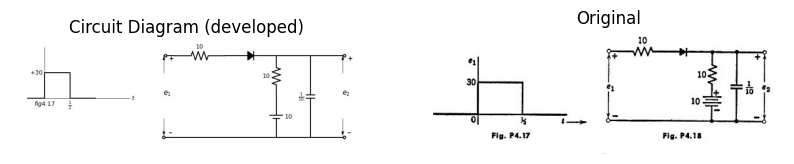

In [58]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().linewidth(.75).length(5).label('$t$' , 'right'))
d+= (l2:=elm.Line().up().length(3).linewidth(.75).at(l1.start).label('$fig4.17$' , 'left'))
d+= (l3:=elm.Line().right().at((-1,0)).length(1))
d+= (l4:=elm.Line().up().length(1.5))
d+= (l5:=elm.Line().right().length(1.5).label('$+30$' , 'left'))
d+= (l6:=elm.Line().down().length(1.5).label(r'$\frac {1}{2}$' , 'left'))
d+= (l4:=elm.Line().right().length(1.5))
d+= (l1:=elm.Line().right().length(.1).dot(open=True).at((7,2.5)))
d+= (l2:=elm.Line().right().length(.5))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$10$' , 'top'))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1))
d += (R2 :=elm.Resistor().down(d.unit*.8).label('$10$' , 'top'))
V1 = d.add(elm.BatteryCell().down(d.unit*.8).label('$10$', 'bottom'))
d+= (l2:=elm.Line().left().length(6.6).dot(open=True))
d+= (l3:=elm.Line().right().length(2).at(R2.start))
d += (C1 :=elm.Capacitor().down(d.unit*1.6).label(r'$\frac {1}{10}$' , 'top'))
d+= (l2:=elm.Line().left().length(2))
d+= (l2:=elm.Line().right().length(2).dot(open=True).at(C1.start))
d+= (l2:=elm.Line().right().length(2).dot(open=True).at(C1.end))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((7,1.5))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((7,-1.2))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((5.5,-1))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((17.5,1.5))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((17.5,-1.2))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((16,-1))
d.save('Drawings/5FP4-15F.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-15F.jpg')
axs[ 0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-16JPG.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.5.	The waveform  $e_1$ ($t$) in Fig. P4.19 is applied to the circuit of Fig. P4.20. Sketch $e_2$ ($t$).

Text(0.5, 1.0, 'Original')

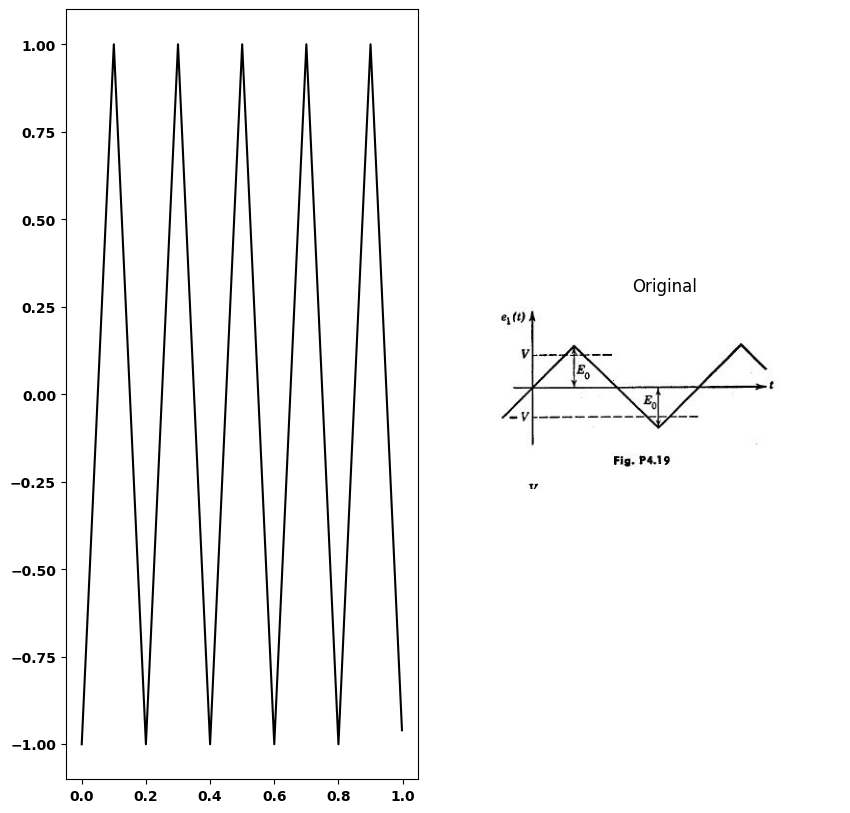

In [68]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
frequency = 5  # Frequency of the triangular wave in Hz
amplitude = 1  # Amplitude of the wave
duration = 1   # Duration in seconds
sampling_rate = 500  # Number of samples per second

# Generate time values
t = np.linspace(0, duration, int(sampling_rate * duration), endpoint=False)

# Generate the triangular waveform
triangle_wave = amplitude * signal.sawtooth(2 * np.pi * frequency * t, width=0.5)

axs[0].plot(t, triangle_wave,color='black')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/fp4-19.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


Text(0.5, 1.0, 'Original')

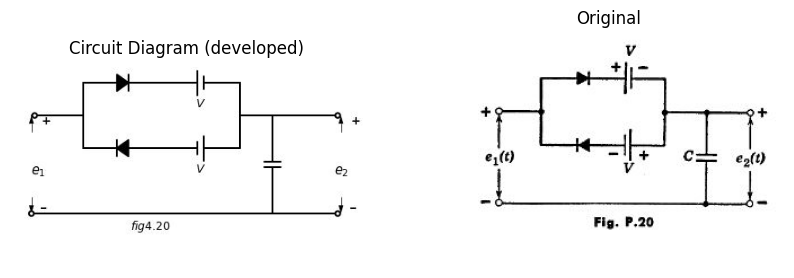

In [70]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().length(.1).dot(open=True))
d+= (l2:=elm.Line().right().length(1.5))
d+= (l3:=elm.Line().up().length(1))
d += (D1 :=elm.Diode(fill=True).right(d.unit*.8))
V1 = d.add(elm.BatteryCell().right(d.unit*.8).label('$V$', 'bottom'))
d+= (l4:=elm.Line().down().length(1))
d+= (l5:=elm.Line().down().length(1))
V1 = d.add(elm.BatteryCell().left(d.unit*.8).label('$V$', 'bottom'))
d += (D1 :=elm.Diode(fill=True).left(d.unit*.8))
d+= (l6:=elm.Line().up().length(1))
d+= (l7:=elm.Line().right().length(1).at(l4.end))
d += (C1 :=elm.Capacitor().down(d.unit*1))
d+= (l8:=elm.Line().left().length(7.4).dot(open=True).label('$fig4.20$', 'bottom'))
d+= (l8:=elm.Line().right().length(2).dot(open=True).at(C1.start))
d+= (l8:=elm.Line().right().length(2).dot(open=True).at(C1.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9.5,-.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9.5,-2.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((7.8,-3))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((0,-.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((0,-2.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.5,-3))
d.save('Drawings/5FP4-21.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-21.jpg')
axs[ 0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-20.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.6.	For the circuit of Fig. P4.21, sketch and dimension the waveforms $e_1$($t$) and $e_2$($t$) when a aingle brief pulse of current $i_1$($t$) is applied ( $δ_1$ <<+√$LC_1$  )

Text(0.5, 1.0, 'Original')

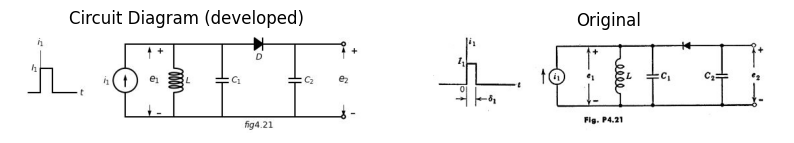

In [71]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().length(.5))
d+= (l2:=elm.Line().up().length(1))
d+= (l3:=elm.Line().right().length(.5).label('$I_1$','left'))
d+= (l4:=elm.Line().down().length(1))
d+= (l5:=elm.Line().right().length(.5))
d+= (l6:=elm.Line().up().length(.75).linewidth(.75).at(l3.start).label('$i_1$','right'))
d+= (l7:=elm.Line().right().length(.5).at(l5.end).label('$t$','right'))
d += (I1:=elm.SourceI().up(d.unit*1).label('$i_1$ ','top' ).at((4,-1)))
d+= (l8:=elm.Line().right().length(2))
d += (L1 :=elm.Inductor2().down(d.unit*1).label('$L$','bottom'))
d+= (l9:=elm.Line().left().length(2))
d+= (l10:=elm.Line().right().length(2).at(L1.start))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C_1$','bottom'))
d+= (l11:=elm.Line().left().length(2))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1).label('$D$','bottom').at(C1.start))
d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C_2$','bottom'))
d+= (l12:=elm.Line().left().length(3).label('$fig4.21$', 'bottom'))
d+= (l13:=elm.Line().right().length(2).dot(open=True).at(C2.start))
d+= (l14:=elm.Line().right().length(2).dot(open=True).at(C2.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((13,1.4))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((13,-.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((11.3,-.75))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((5,1.4))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5,-.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((3.5,-.75))
d.save('Drawings/5FP4-22.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-22.jpg')
axs[ 0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-21.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.7.	A full-wave rectifier is driven by an ideal transformer, supplying 100 volts at a frequency of 200/π cps to each half of the circuit shown in Fig. P4.22. The diodes are assumed to be ideal rectifiers. The capacitor $C$ is 1 microfarad. For a certain value of $R$ each diode conducts for 1/10 of each half period. (Note: sin $x$ ≈ $x$ for small values of $x$.)

Text(0.5, 1.0, 'Original')

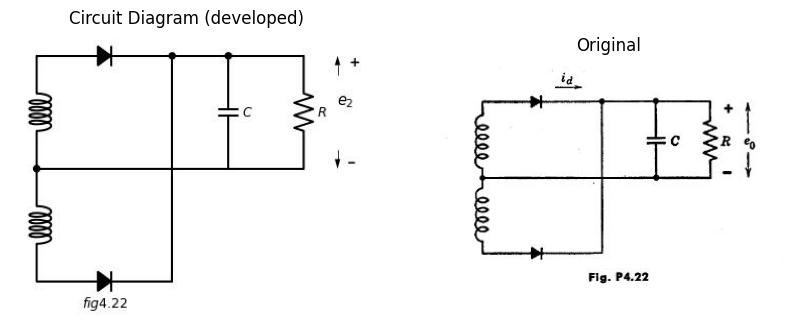

In [73]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (L1 :=elm.Inductor2().down(d.unit*1))
d += (L2 :=elm.Inductor2().down(d.unit*1))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1.2).at(L1.start))
d+= (l1:=elm.Line().right().length(1.5).dot())
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$','bottom'))
d+= (l2:=elm.Line().left().length(5.1).dot())
d += (D2 :=elm.Diode(fill=True).right(d.unit*1.2).at(L2.end).label('$fig4.22$','bottom'))
d+= (l3:=elm.Line().left().length(5.1).dot().endpoints(D2.end,D1.end))
d+= (l4:=elm.Line().right().length(2).at(C1.start))
d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$','bottom'))
d+= (l5:=elm.Line().left().length(2))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((8,-.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((8,-2.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,-2.5))
d.save('Drawings/5FP4-22`a.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-22`a.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-22.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

($a$) Sketch and dimension the diode current $i_d$ as a function of time.


($b$)	Find the average value of $i_d$.


($c$)	Find the value of $R$.


($d$) Find the ripple voltage.



($e$) Find the rma value of $i_d$.


4.8. The circuit shown in Fig. P4.23 is used to demodulate an amplitude modulated signal$e_1$.The carrier frequency is $10^6$ cps, the highest modulation frequency 5000 cps. The modulation factor $m$ is never larger than 0.8.

Text(0.5, 1.0, 'Original')

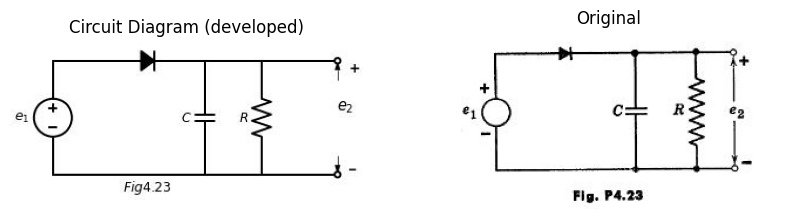

In [74]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
d+= (l1:=elm.Line().right().length(1))
d+= (l2:=elm.Line().right().length(1).at(V.start))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1).at(l1.end))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$' , 'top'))
d+= (l3:=elm.Line().left().length(3).label('$Fig4.23$' , 'bottom'))
d+= (l4:=elm.Line().right().length(1.5).at(C1.start))
d+= (l5:=elm.Line().right().length(1.5).at(C1.end))
d += (R1 :=elm.Resistor().up(d.unit*1).label('$R$' , 'top'))
d+= (l6:=elm.Line().right().length(2).dot(open=True).at(R1.start))
d+= (l7:=elm.Line().right().length(2).dot(open=True).at(R1.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((7.5,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((7.5,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((6,.5))
d.save('Drawings/5FP4-23.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-23.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-23.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

($a$) Determinethemaximum allowable value for the product $RC$ when the circle k reduired to detect the modulation without incurring envelope distortion.



($b$) For a carrier signal of 10 volts peak, modulated with 1000 cps at $m$ = 0.3, list the approximate (average) ripple and audio output voltages under the following conditions:

                RC= 0.5 times critical value 

                RC= 0.1 times critical value 

                RC= 0.01 times critical value.

                
4.9.	In Fig. P4.24,  i is a square wave that jumps between plus and minus 75 volts every $T$/2 seconds. 

($a$) Plot $e_2$ as a time function if $T$ << $RC$.

($b$) Repeat ($a$) if $T$ >> $RC$.


Text(0.5, 1.0, 'Original')

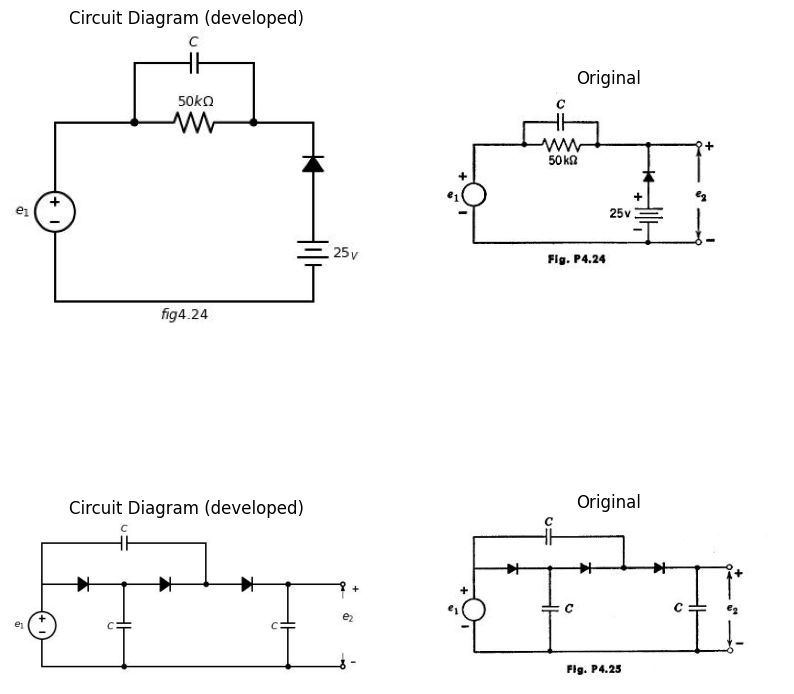

In [76]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1.5).label('$e_1$ ','top' ))
d+= (l1:=elm.Line().right().length(2).dot())
d += (R1 :=elm.Resistor().right(d.unit*1).label('$50kΩ$' , 'top').dot())
d+= (l2:=elm.Line().up().length(1.5).at(l1.end))
d+= (l3:=elm.Line().up().length(1.5).at(R1.end))
d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$' , 'top').at(l2.end))
d+= (l4:=elm.Line().right().length(1.5).at(R1.end))
d += (D1 :=elm.Diode(fill=True).down(d.unit*.7).reverse())
V1 = d.add(elm.Battery().down(d.unit*.8).label('$25_V$', 'bottom'))
d+= (l5:=elm.Line().left().length(1.5).endpoints(V1.end,V.start).label('$fig4.24$', 'bottom'))
d.save('Drawings/5FP4-24.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-24.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5FP4-24.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (V:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','top' ).dot())
d+= (l1:=elm.Line().left().length(3))
d += (D2 :=elm.Diode(fill=True).right(d.unit*1).at(C1.start).dot())
d += (D3 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C$ ','top' ).dot())
d+= (l2:=elm.Line().left().length(3).endpoints(C1.end,C2.end))
d+= (l3:=elm.Line().up().length(1.5).at(D1.start))
d+= (l4:=elm.Line().up().length(1.5).at(D2.end))
d += (C3 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l3.end,l4.end))
d+= (l5:=elm.Line().right().length(2).dot(open=True).at(C2.start))
d+= (l6:=elm.Line().right().length(2).dot(open=True).at(C2.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((11,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((11,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((9.5,.5))
d.save('Drawings/5FP4-25f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-25f.jpg')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-25.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

4.10.	In Fig. P4.25, $e_1$ in a rectangular wave that jumps between ±$E_1$ every $T$/2 seconds starting at $t$ = 0. Plot $e_2$ as a function of time until steady- state conditions exist.	Assume ideal diodes, and the capacitors initially uncharged.

4.11.	In the circuit shown in Fig. P4.26,

Text(0.5, 1.0, 'Original')

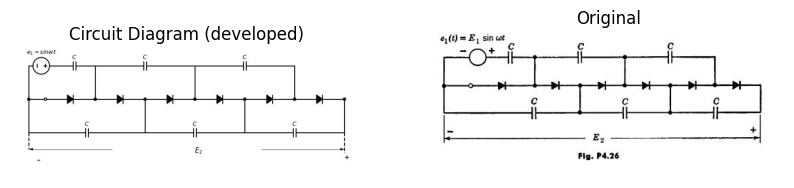

In [79]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().up().length(2).dot())
d+= (l2:=elm.Line().right().length(1).dot(open=True))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (D2 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (D3 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (D4 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (D5 :=elm.Diode(fill=True).right(d.unit*1).dot())
d += (D6 :=elm.Diode(fill=True).right(d.unit*1).dot())
d+= (l3:=elm.Line().down().length(2).at(D6.end))
d+= (l4:=elm.Line().down().length(2).at(D4.end))
d+= (l5:=elm.Line().down().length(2).at(D2.end))
d+= (l6:=elm.Line().up().length(2).at(D5.end))
d+= (l7:=elm.Line().up().length(2).at(D3.end))
d+= (l8:=elm.Line().up().length(2).at(D1.end))
d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l3.end,l4.end))
d += (C2 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l5.end,l4.end))
d += (C3 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l5.end,l1.start))
d += (C4 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l6.end,l7.end))
d += (C5 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(l7.end,l8.end))
d+= (l9:=elm.Line().up().length(2).at(l1.end))
d += (V:=elm.SourceV().right(d.unit*.5).label('$e_1=sinwt$ ','top' ))
d += (C6 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ).endpoints(V.end,l8.end))
d+= (l10:=elm.Line().down().length(1).at(D1.end).linestyle('--').at(l1.start))
d+= (l11:=elm.Line().down().length(1.2).at(D1.end).linestyle('--').at(l3.end))
d += elm.Arrow().right().length(5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((14,-1))
d += elm.Arrow().left().length(5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((5,-1))
d += elm.Gap().up().label(  '$E_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8.5,-2.3))
d.save('Drawings/5FP4-26.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-26.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-26JPG.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

($a$)	Find the steady-state value of $E_2$.

($b$) What is the maximum peak inverse voltage the diodes have to stand?

($c$) What is the maximum voltage on each capacitor?

Text(0.5, 1.0, 'Original')

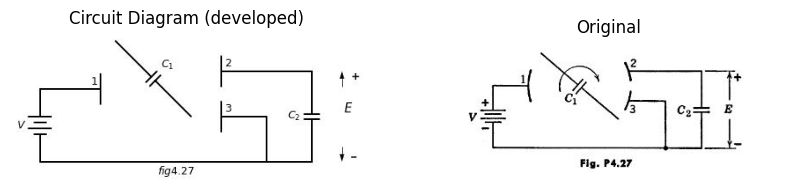

In [80]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
V1 = d.add(elm.Battery().up(d.unit*.8).label('$V$', 'top').reverse())
d+= (l1:=elm.Line().right().length(2))
d+= (l2:=elm.Line().up().length(.5).label('$1$', 'top'))
d+= (l3:=elm.Line().down().length(.5).at(l1.end))
d+= (l4:=elm.Line().up().length(.0005).at((2.5,4)))
d+= (l5:=elm.Line().up().length(.0005).at((5,1.5)))
d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C_1$ ','top' ).endpoints(l5.end,l4.end))
d+= (l6:=elm.Line().up().length(.5).label('$2$', 'bottom').at((6,3)))
d+= (l7:=elm.Line().down().length(.5).at(l6.start))
d+= (l8:=elm.Line().right().length(3).at(l7.start))
d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C_2$ ','top' ))
d+= (l9:=elm.Line().left().length(3).endpoints(C2.end,V1.start).label('$fig4.27$', 'bottom'))
d+= (l10:=elm.Line().up().length(.5).label('$3$', 'bottom').at((6,1.5)))
d+= (l11:=elm.Line().down().length(.5).at(l10.start))
d+= (l12:=elm.Line().right().length(1.5).at(l11.start))
d+= (l13:=elm.Line().down().length(1.5))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10,.5))
d += elm.Gap().up().label(  '$E$' , ofst=-1.7 , fontsize = 16).color('black').at((8.5,.5))
d.save('Drawings/5FP4-27.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-27.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-27.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.12.	The capacitor $C_1$ in Fig. P4.27 rotates about an axis normal to the plane of the diagram, its terminals alternately making contacts 1, 2 and 1, 3.

($a$) Find the steady-state value of $E$.

Text(0.5, 1.0, 'Original')

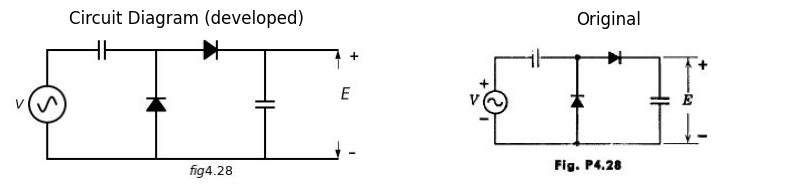

In [81]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceSin().up(d.unit*1).label('$V$ ','top' ))
d += (C1 :=elm.Capacitor().right(d.unit*1))
d += (D1 :=elm.Diode(fill=True).down(d.unit*1).reverse())
d+= (l1:=elm.Line().left().length(3))
d += (D2 :=elm.Diode(fill=True).right(d.unit*1).at(D1.start))
d += (C2 :=elm.Capacitor().down(d.unit*1))
d+= (l2:=elm.Line().left().length(3).label('$fig4.28$', 'bottom'))
d+= (l3:=elm.Line().right().length(2).at(C2.start))
d+= (l4:=elm.Line().right().length(2).at(C2.end))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((8,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((8,.5))
d += elm.Gap().up().label(  '$E$' , ofst=-1.7 , fontsize = 16).color('black').at((6.5,.5))
d.save('Drawings/5FP4-28.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-28.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-28.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

($b$)Show the analogy between the switching circuit of Fig. P4.27 and the rectifier circuit of Fig. P4.28, which produces a steady-state output $E$ when attached to a sinusoidal voltage $V$.

Text(0.5, 1.0, 'Original')

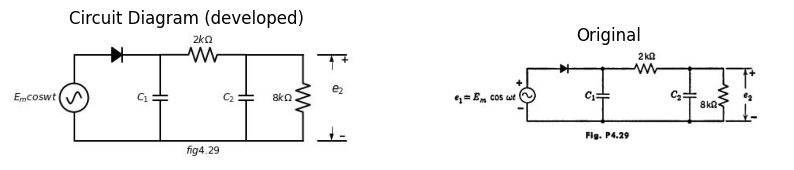

In [82]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceSin().up(d.unit*1).label('$E_m$$coswt$ ','top' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C_1$ ','top' ))
d+= (l1:=elm.Line().left().length(3))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$2kΩ$ ','top' ).at(C1.start))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C_2$ ','top' ))
d+= (l2:=elm.Line().left().length(3).label('$fig4.29$', 'bottom'))
d+= (l3:=elm.Line().right().length(2).at(C2.start))
d += (R2 :=elm.Resistor().down(d.unit*1).label('$8kΩ$ ','top' ))
d+= (l4:=elm.Line().left().length(2))
d+= (l5:=elm.Line().right().length(1).at((8.5,0)))
d+= (l6:=elm.Line().right().length(1).at((8.5,3)))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9,2.5))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9,.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((7.5,.5))
d.save('Drawings/5FP4-29.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-29.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-29.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.13.	The rectifier circuit shown in Fig. P4.29 produces a steady-state output voltage $e_2$ containing a time-average component $e_2$ and a periodic ripple component. The design specifications require the peak-to-peak ripple to be no more than 0.001$e_2$ . Consider two designs. First let $C_2$ be zero and find the required value of	$C_1$.Second, find $C_1$, and $C_2$ such that the specifications are satisfied and at the same time  $C_1$+$C_2$ is minimized. Which design requires less total capacitance?

4.14.	The circuit shown in Fig. P4.30 is at rest when the square wave shown in Fig. P4.31 is suddenly applied. Assume that the capacitor $C$ is sufficiently large so that the periodic ripple in the output voltage is small and $e_2$ may be replaced by a ripple-free average value $E_2$ .  At an arbitrary time $t$ the value of $E_2$  in undetermined. Formulate, in terms of $E_1, r, R, T$, and $E_2$ ,

($a$) The net charge per cycle flowing through resistances $r$ and $R$.

($b$) The net charge per cycle delivered to $C$.

($c$)Using the results of parts ($a$) and ($b$), formulate and solve a differential equation to find $e_2(t)$

($d$)What is the value of $E_2$?

Text(0.5, 1.0, 'Original')

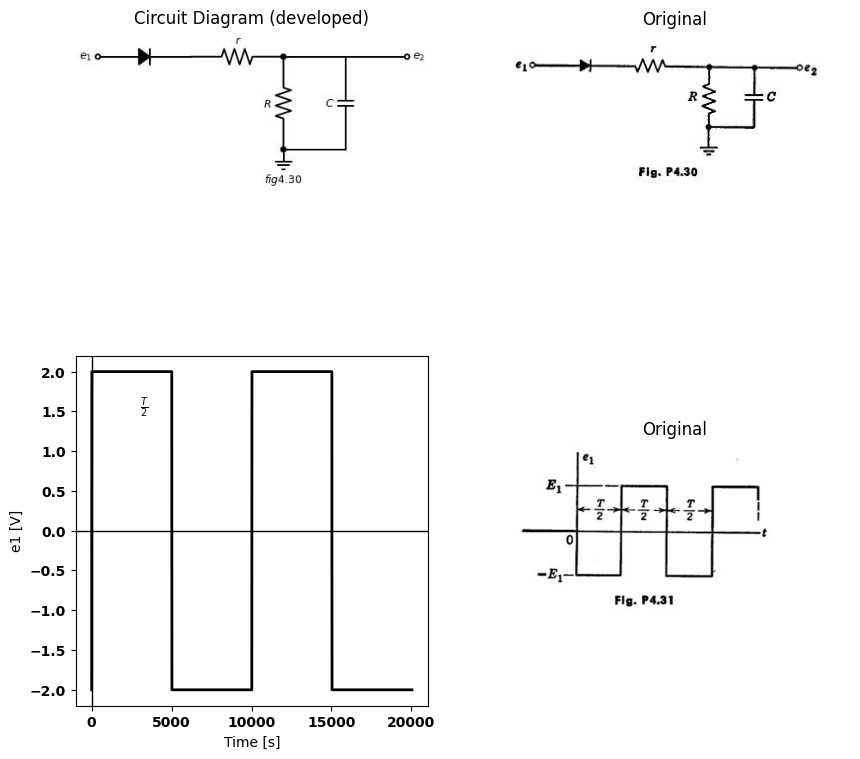

In [87]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().left().length(.3).dot(open=True).label('$e_1$ ','left' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$r$ ','top' ).dot())
d += (R2 :=elm.Resistor().down(d.unit*1).label('$R$ ','top' ).dot())
d+= (l2:=elm.Line().right().length(2).at(R2.start))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','top' ))
d+= (l3:=elm.Line().left().length(2))
d+= (l4:=elm.Line().right().length(2).dot(open=True).at(C1.start).label('$e_2$ ','right' ))
d += elm.Ground().at(R2.end).label('$fig4.30$', 'bottom')
d.save('Drawings/5FP4-30.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-30.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-30.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) ,
axs[1,0].set_xlabel('Time [s]')
axs[1,0].text(3000,1.5, r'$\frac {T}{2}$ ', fontsize=10)
#axs[0].text(7500,-3, ' $40$ ', fontsize=10)
axs[1,0].annotate('', xy=(6000, -2.5), xytext=(10000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(0, -2.5), xytext=(6000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p4-31.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

($e$)On the basis of the charge delivered to $C$ during the firat and second halves of the cycle, what is the approximate peak-to-peak steady-state ripple?


4.15. It is desired to supply a current $i$ to an instrument $m$ whose resistance is negligibly small. The direct component of $i$ is to be as large as possible and the ripple (ratio of a-c amplitude to d-c) must not exceed some specified

Text(0.5, 1.0, 'Original')

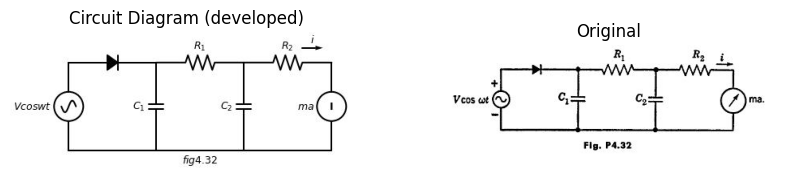

In [89]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V:=elm.SourceSin().up(d.unit*1).label('$V$$coswt$ ','top' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C_1$ ','top' ))
d+= (l1:=elm.Line().left().length(3))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$R_1$ ','top' ).at(C1.start))
d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C_2$ ','top' ))
d+= (l2:=elm.Line().left().length(3).label('$fig4.32$', 'bottom'))
d += (R2 :=elm.Resistor().right(d.unit*1).label('$R_2$ ','top' ).at(C2.start))
I = d.add(elm.MeterI().down(d.unit*1).label('$ ma$', 'top'))
d+= (l2:=elm.Line().left().length(3))
d += elm.Arrow().right().length(.7).color('black').label('$i$', loc='top', color='black'). at((8,3.5))
d.save('Drawings/5FP4-31.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-31.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-32.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

limit, say one-tenth per cent.  Quantities $V, w,$ and the total capacitance $C = C_1 + C_2 $ are known constants, being fixed by cost and convenience considerations.  Find optimum values of $ R_1 , R_2 , C_1$  and $C_2$ in Fig. P4.32. Use any approximations which appear reasonable.

4.17. in the detector circuit of Fig. P4.33 the product $wRC$ is so large that capacitor ripple voltage may be ignored. Sketch and dimension the curve of

($a$) $E$ versus $A$, with $B$ positive and fixed.

($b$) $E$ versus $B$, with $A$ positive and fixed.


4.17. The circuit shown in Pig. P4.34 is a piecewise-linear model of a microwave detector. For simplicity of analysis, assume that the high-frequency input voltage $e_1(t)$ is a square wave of amplitude ($E_1$),. Capacitance $C$ and inductance $L$ are so large that the ripple voltage across $C$ and the ripple current in $L$ are negligible. Hence $i_1(t)$ must be a square wave of aome amplitude $i_1$. Derive relations giving $I_1$ and $I_2$ in terms of $E_1$ and $E_2$.  Show that


Text(0.5, 1.0, 'Original')

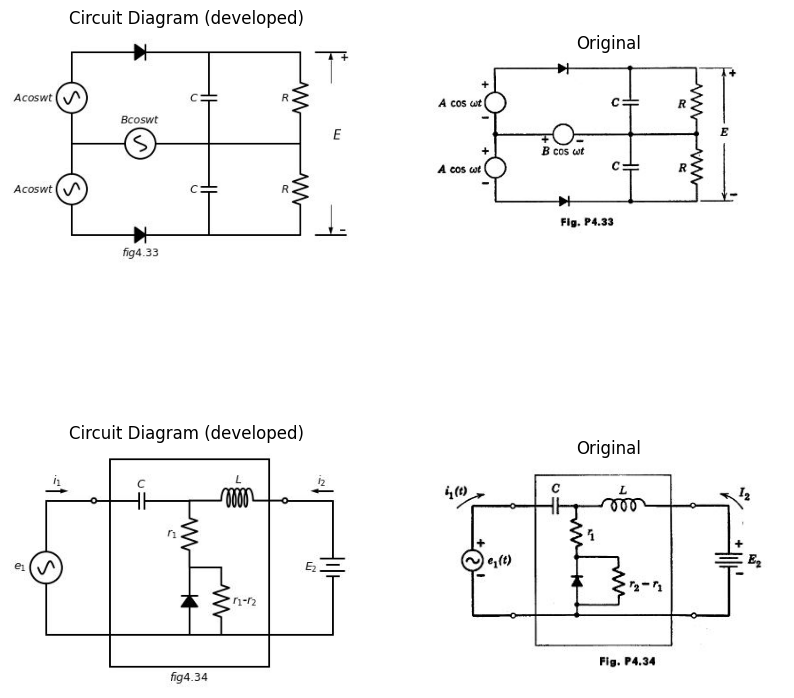

In [91]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (V1:=elm.SourceSin().up(d.unit*1).label('$A$$coswt$ ','top' ))
d += (V2:=elm.SourceSin().up(d.unit*1).label('$A$$coswt$ ','top' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1.5))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','top' ))
d += (V3:=elm.SourceSin().left(d.unit*1.5).label('$B$$coswt$ ','top' ))
d += (D2 :=elm.Diode(fill=True).right(d.unit*1.5).at(V1.start).label('$fig4.33$', 'bottom'))
d += (C2 :=elm.Capacitor().up(d.unit*1).label('$C$ ','top' ))
d+= (l1:=elm.Line().right().length(3).at(C1.start))
d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$ ','top' ))
d += (R2 :=elm.Resistor().down(d.unit*1).label('$R$ ','top' ))
d+= (l2:=elm.Line().left().length(3))
d+= (l3:=elm.Line().left().length(3).endpoints(R2.start,C1.end))
d+= (l4:=elm.Line().right().length(1).at((8,0)))
d+= (l5:=elm.Line().right().length(1).at((8,6)))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((8.5,5))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((8.5,1))
d += elm.Gap().up().label(  '$E$' , ofst=-1.7 , fontsize = 16).color('black').at((7,2))
d.save('Drawings/5FP4-33.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-33.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-33.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (V1:=elm.SourceSin().up(d.unit*1.4).label('$e_1$ ','top' ))
d+= (l1:=elm.Line().right().length(1.5).dot(open=True))
d += (C1 :=elm.Capacitor().right(d.unit*1).label('$C$ ','top' ))
d += (R1 :=elm.Resistor().down(d.unit*.7).label('$r_1$ ','top' ))
d += (D1 :=elm.Diode(fill=True).down(d.unit*.7).reverse())
d+= (l2:=elm.Line().left().length(1.5).endpoints(D1.end,V1.start))
d+= (l3:=elm.Line().right().length(1).at(D1.start))
d+= (l4:=elm.Line().right().length(1).at(D1.end))
d += (R2 :=elm.Resistor().down(d.unit*.7).label('$r_1$-$r_2$','bottom' ).endpoints(l3.end,l4.end))
d += (L1 :=elm.Inductor2().right(d.unit*1).label('$L$ ','top' ).at(R1.start).dot(open=True))
d+= (l4:=elm.Line().right().length(1.5))
V1 = d.add(elm.Battery().down(d.unit*1.4).label('$E_2$', 'top'))
d+= (l5:=elm.Line().left().length(3.5))
d += elm.Arrow().right().length(.7).color('black').label('$i_1$', loc='top', color='black'). at((0,4.5))
d += elm.Arrow().left().length(.7).color('black').label('$i_2$', loc='top', color='black'). at((9,4.5))
d+= (l6:=elm.Line().left().length(5).at((7,5.5)))
d+= (l7:=elm.Line().left().length(5).at((7,-1)).label('$fig4.34$', 'bottom'))
d+= (l8:=elm.Line().left().length(5).endpoints(l6.end,l7.end))
d+= (l9:=elm.Line().left().length(5).endpoints(l6.start,l7.start))
d.save('Drawings/5FP4-34.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-34.jpg')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-34.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

these relations may be represented as the d-c circuit (Fig. P4.35). Find $r_a$, $r_b$, and $r_c$ in terms of $r_1$ and $r_2$. Now let source $e_1(t)$ have a series resistance $R_1$, and let $E_2$ be replaced by a resistance $R_2$ i. Find $R_1$ and $R_2$ in terms of $r_1$ and $r_2$ so as to maximise the load power $I_2^2 R_2$ per unit available source power $E_1^2 / 4R_1$.


Text(0.5, 1.0, 'Original')

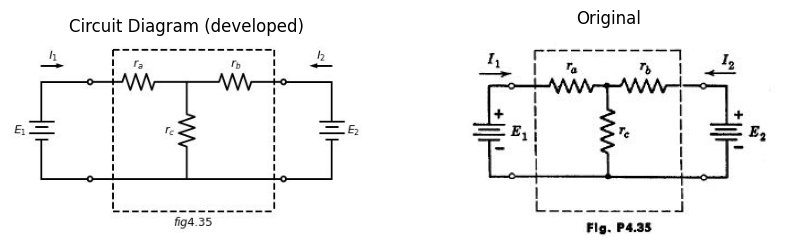

In [92]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(10, 10))
d = schemdraw.Drawing()
V1 = d.add(elm.Battery().up(d.unit*1).label('$E_1$', 'top').reverse())
d+= (l1:=elm.Line().right().length(1.5).dot(open=True))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$r_a$ ','top' ))
d += (R2 :=elm.Resistor().down(d.unit*1).label('$r_c$ ','top' ))
d += (R3 :=elm.Resistor().right(d.unit*1).label('$r_b$ ','top' ).at(R1.end).dot(open=True))
d+= (l2:=elm.Line().right().length(1.5))
V2 = d.add(elm.Battery().down(d.unit*1).label('$E_2$', 'bottom'))
d+= (l3:=elm.Line().left().length(1.5).dot(open=True))
d+= (l4:=elm.Line().right().length(1.5).dot(open=True).at(V1.start))
d+= (l5:=elm.Line().left().length(1.5).endpoints(l3.end,l4.end))
d += elm.Arrow().right().length(.7).color('black').label('$I_1$', loc='top', color='black'). at((0,3.5))
d += elm.Arrow().left().length(.7).color('black').label('$I_2$', loc='top', color='black'). at((9,3.5))
d+= (l6:=elm.Line().right().length(5).at((2.2,4)).linestyle('--'))
d+= (l7:=elm.Line().right().length(5).at((2.2,-1)).linestyle('--').label('$fig4.35$', 'bottom'))
d+= (l5:=elm.Line().left().length(1.5).endpoints(l6.end,l7.end).linestyle('--'))
d+= (l5:=elm.Line().left().length(1.5).endpoints(l6.start,l7.start).linestyle('--'))
d.save('Drawings/5FP4-35f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-35f.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-35.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

4.18. The square waves of voltage $e_1(t)$ and $e_2(t)$ in Fig. P4.36 are applied to the circuit in Fig. P4.37. Sketch the output waveform $e_3(t)$.


4.19. For the circuit shown in Fig. P4.38 with $e_1(t)$ = 100 sin $wt$, 

($a$)Sketch and dimension as a function of time the voltage $e_2(t)$ with switch open.

($b$)Find the approximate peak-to-peak ripple voltage component of $e_3$ after the Switch has been closed a long time, (Assume $wRC$>>1.)

Text(0.5, 1.0, 'Original')

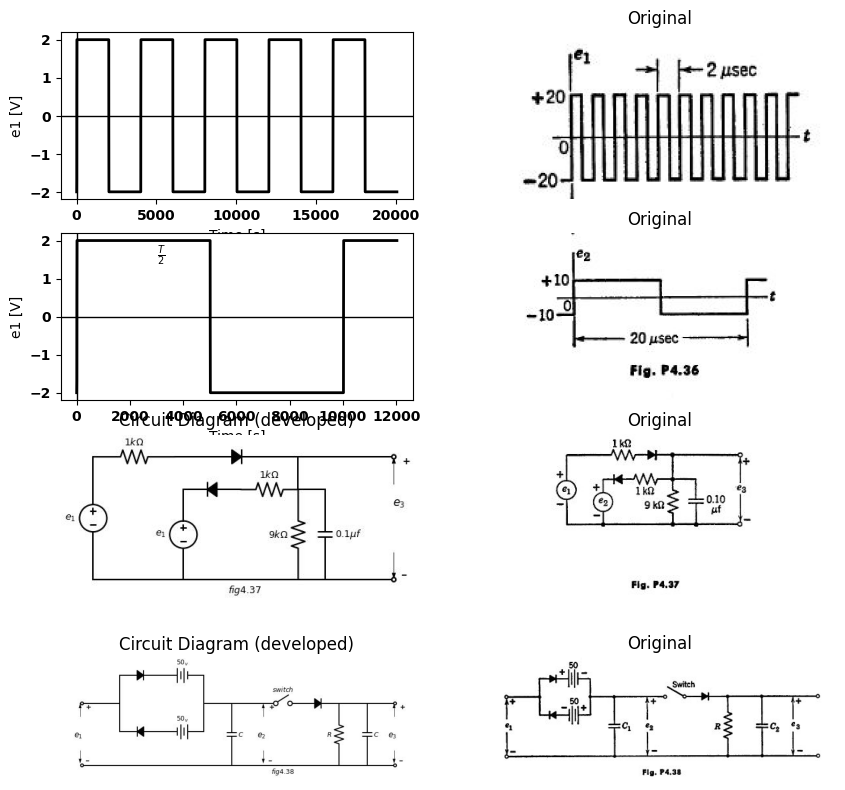

In [99]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(4, 2, figsize=(10, 10))
d = schemdraw.Drawing()
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=2@u_ms, period=4@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[0,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[0,0].set_xlabel('Time [s]')
#axs[0].text(3000,1.5, '$2us$ ', fontsize=10)
#axs[0].text(7500,-3, ' $40$ ', fontsize=10)
axs[0,0].annotate('', xy=(6000, -2.5), xytext=(10000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[0,0].annotate('', xy=(0, -2.5), xytext=(6000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[0,0].set_ylabel('e1 [V]')
axs[0,0].axhline(0, color='black', linewidth=1)
axs[0,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/fp4-36`a.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'

rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=5@u_ms, period=10@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=12@u_ms)
axs[1,0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[1,0].set_xlabel('Time [s]')
axs[1,0].text(3000,1.5, r'$\frac {T}{2}$ ', fontsize=10)
#axs[0].text(7500,-3, ' $40$ ', fontsize=10)
axs[1,0].annotate('', xy=(6000, -2.5), xytext=(10000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].annotate('', xy=(0, -2.5), xytext=(6000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[1,0].set_ylabel('e1 [V]')
axs[1,0].axhline(0, color='black', linewidth=1)
axs[1,0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/p4-36j.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1.5).label('$e_1$ ','top' ))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$1kΩ$ ','top' ))
d += (D1 :=elm.Diode(fill=True).right(d.unit*1.5))
d+= (l1:=elm.Line().down().length(1.2))
d += (R2 :=elm.Resistor().left(d.unit*.7).label('$1kΩ$ ','top' ))
d += (D2 :=elm.Diode(fill=True).left(d.unit*.7))
d += (V2:=elm.SourceV().down(d.unit*1.1).label('$e_1$ ','top' ).reverse())
d += (R3 :=elm.Resistor().down(d.unit*1.1).label('$9kΩ$ ','top' ).at(R2.start))
d+= (l2:=elm.Line().right().length(1).at(R3.start))
d += (C1 :=elm.Capacitor().down(d.unit*1.1).label('$0.1μf$ ','bottom' ))
d+= (l3:=elm.Line().right().length(11).at(V1.start).dot(open=True).label('$fig4.37$', 'bottom'))
d+= (l4:=elm.Line().right().length(3.5).at(D1.end).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((11,3.5))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((11,1))
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((9.5,1.5))
d.save('Drawings/5FP4-36j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-36j.jpg')
axs[2,0].imshow(img)
axs[2,0].axis('off')  # Hide axes for image display
axs[2,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-36j.jpg')  # Load the PNG file
axs[2,1].imshow(img_sample)
axs[2,1].axis('off')  # Hide axes for image display
axs[2,1].set_title('Original')
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().length(.1).dot(open=True))
d+= (l2:=elm.Line().right().length(2))
d+= (l3:=elm.Line().up().length(1.5))
d += (D1 :=elm.Diode(fill=True).right(d.unit*.75))
V1 = d.add(elm.Battery().right(d.unit*.75).label('$50_v$', 'top'))
d+= (l4:=elm.Line().down().length(1.5))
d+= (l3:=elm.Line().down().length(1.5))
V2 = d.add(elm.Battery().left(d.unit*.75).label('$50_v$', 'top'))
d += (D2 :=elm.Diode(fill=True).left(d.unit*.75))
d+= (l5:=elm.Line().up().length(1.5))
d+= (l6:=elm.Line().right().length(1.5).at(l4.end))
d += (C1 :=elm.Capacitor().down(d.unit*1.1).label('$C$ ','bottom' ))
d+= (l7:=elm.Line().left().length(8).dot(open=True))
d+= (l8:=elm.Line().right().length(2).at(l6.end))
d+= (l9:=elm.Switch().right().length(1.5).label('$switch$ ','top' ))
d += (D2 :=elm.Diode(fill=True).right(d.unit*.75))
d += (R1 :=elm.Resistor().down(d.unit*1.1).label('$R$ ','top' ))
d+= (l10:=elm.Line().left().length(6).label('$fig4.38$', 'bottom'))
d+= (l11:=elm.Line().right().length(1.5).at(D2.end))
d += (C2 :=elm.Capacitor().down(d.unit*1.1).label('$C$ ','bottom' ))
d+= (l12:=elm.Line().left().length(1.5))
d+= (l13:=elm.Line().right().length(1.5).dot(open=True).at(C2.start))
d+= (l14:=elm.Line().right().length(1.5).dot(open=True).at(C2.end))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((9.8,-.7))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((9.8,-2.5))
d += elm.Gap().up().label(  '$e_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8,-3))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((0,-.7))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((0,-2.5))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((-1.8,-3))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((16.8,-.7))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((16.8,-2.5))
d += elm.Gap().up().label(  '$e_3$' , ofst=-1.7 , fontsize = 16).color('black').at((15,-3))
d.save('Drawings/5FP4-38.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-38.jpg')
axs[3,0].imshow(img)
axs[3,0].axis('off')  # Hide axes for image display
axs[3,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-38.jpg')  # Load the PNG file
axs[3,1].imshow(img_sample)
axs[3,1].axis('off')  # Hide axes for image display
axs[3,1].set_title('Original')

4.20. From the circuit ahown in Fig. P4.39:

($a$)Determine approximately the secondary voltage required in the input transformer for $E_d$ $_c$ = 400 v and $I_d$ $_c$ = 0.030 amp.

($b$)Determine approximately the output rms hum voltage for power frequencies of 60 cpg and 800 cps.
Justify all approximations clearly.

Text(0.5, 1.0, 'Original')

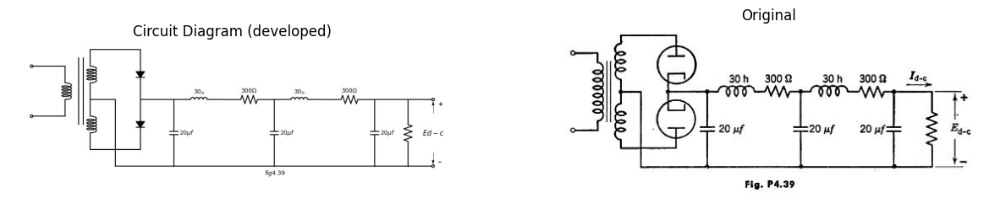

In [101]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (L1:=elm.Inductor2().down(d.unit*1).at((1.7,3)))
d+= (l2:=elm.Line().left().length(2).dot(open=True))
d+= (l3:=elm.Line().down().length(4).at((2.5,3.5)))
d+= (l4:=elm.Line().down().length(4).at((2.8,3.5)))
d += (L2:=elm.Inductor2().down(d.unit*1).at((3.2,4)).reverse())
d += (L3:=elm.Inductor2().down(d.unit*1))
d+= (l1:=elm.Line().left().length(2).at(L1.start).dot(open=True))
d+= (l5:=elm.Line().right().length(3).at(L2.start))
d += (D1 :=elm.Diode(fill=True).down(d.unit*1))
d += (D2 :=elm.Diode(fill=True).down(d.unit*1))
d+= (l6:=elm.Line().left().length(3))
d+= (l7:=elm.Line().right().length(1.5).at(L2.end))
d+= (l8:=elm.Line().down().length(4))
d+= (l9:=elm.Line().right().length(2).at(D1.end))
d += (C1 :=elm.Capacitor().down(d.unit*1.34).label('$20μf$ ','bottom' ))
d+= (l10:=elm.Line().right().length(19).at(l8.end).dot(open=True).label('$fig4.39$', 'bottom'))
d += (L3:=elm.Inductor().right(d.unit*1).at(C1.start).label('$30_h$ ','top' ))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$300Ω$ ','top' ))
d += (C2 :=elm.Capacitor().down(d.unit*1.34).label('$20μf$ ','bottom' ))
d += (L4:=elm.Inductor().right(d.unit*1).at(C2.start).label('$30_h$ ','top' ))
d += (R2 :=elm.Resistor().right(d.unit*1).label('$300Ω$ ','top' ))
d += (C3 :=elm.Capacitor().down(d.unit*1.34).label('$20μf$ ','bottom' ))
d+= (l11:=elm.Line().right().length(2).at(C3.start))
d += (R3 :=elm.Resistor().down(d.unit*1.34))
d+= (l12:=elm.Line().right().length(1.5).at(R3.start).dot(open=True))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((23.7,0.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((23.7,-2.2))
d += elm.Gap().up().label(  '$Ed-c$' , ofst=-1.7 , fontsize = 16).color('black').at((22,-2.3))
d.save('Drawings/5FP4-39f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-39f.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-39.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


4.21. From Figs. P4.40 and P4.41 (making reasonable approximations)

($a$) Determine the direct output voltage for a load current of 125 ma.

($b$) Determine the value of the 120 cps hum voltage.

($c$)Determine the minimum load current for which $E_d$ $_c$ a relatively independent of $I_d$ $_c$ we the load resistance is varied.


Text(0.5, 1.0, 'Original')

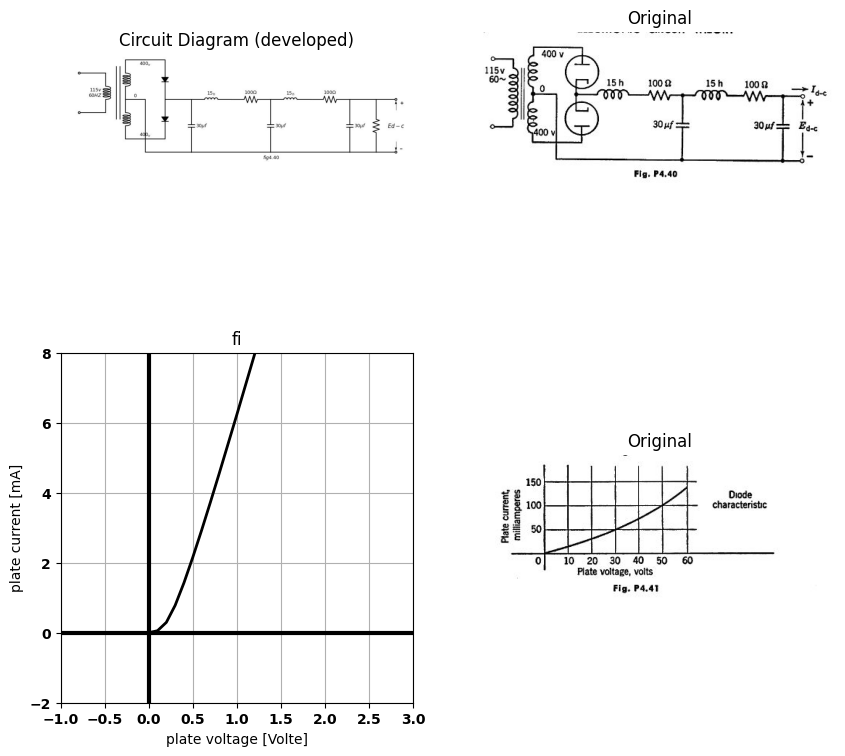

In [104]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
d = schemdraw.Drawing()
d += (L1:=elm.Inductor2().down(d.unit*1).at((1.7,3)).label('$115v$\n$60HZ$ ','top' ))
d+= (l2:=elm.Line().left().length(2).dot(open=True))
d+= (l3:=elm.Line().down().length(4).at((2.5,3.5)))
d+= (l4:=elm.Line().down().length(4).at((2.8,3.5)))
d += (L2:=elm.Inductor2().down(d.unit*1).at((3.2,4)).reverse())
d += (L3:=elm.Inductor2().down(d.unit*1))
d+= (l1:=elm.Line().left().length(2).at(L1.start).dot(open=True))
d+= (l5:=elm.Line().right().length(3).at(L2.start).label('$400_v$ ','bottom' ))
d += (D1 :=elm.Diode(fill=True).down(d.unit*1))
d += (D2 :=elm.Diode(fill=True).down(d.unit*1))
d+= (l6:=elm.Line().left().length(3).label('$400_v$ ','top' ))
d+= (l7:=elm.Line().right().length(1.5).at(L2.end).label('$0$ ','top' ))
d+= (l8:=elm.Line().down().length(4))
d+= (l9:=elm.Line().right().length(2).at(D1.end))
d += (C1 :=elm.Capacitor().down(d.unit*1.34).label('$30μf$ ','bottom' ))
d+= (l10:=elm.Line().right().length(19).at(l8.end).dot(open=True).label('$fig4.40$', 'bottom'))
d += (L3:=elm.Inductor().right(d.unit*1).at(C1.start).label('$15_h$ ','top' ))
d += (R1 :=elm.Resistor().right(d.unit*1).label('$100Ω$ ','top' ))
d += (C2 :=elm.Capacitor().down(d.unit*1.34).label('$30μf$ ','bottom' ))
d += (L4:=elm.Inductor().right(d.unit*1).at(C2.start).label('$15_h$ ','top' ))
d += (R2 :=elm.Resistor().right(d.unit*1).label('$100Ω$ ','top' ))
d += (C3 :=elm.Capacitor().down(d.unit*1.34).label('$30μf$ ','bottom' ))
d+= (l11:=elm.Line().right().length(2).at(C3.start))
d += (R3 :=elm.Resistor().down(d.unit*1.34))
d+= (l12:=elm.Line().right().length(1.5).at(R3.start).dot(open=True))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((23.7,0.2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((23.7,-2.2))
d += elm.Gap().up().label(  '$Ed-c$' , ofst=-1.7 , fontsize = 16).color('black').at((22,-2.3))
d.save('Drawings/5FP4-40.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-40.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-40.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
rcParams['font.weight'] = 'bold'
circuit = Circuit('v-i curve')
circuit.model('BAV21','D' ,IS = 10@u_uA , N = 1.906  ,BV = 110@u_V, IBV = 0.0001@u_V,  VJ = 0.7@u_V ,CJO = 7.048E-13 ,RS = 40@u_Ohm ,TT = 3.48E-9)
Vi = circuit.V('i', '1', circuit.gnd, 0@u_V)
circuit.R(1, '1', '2', 70@u_Ohm)
circuit.D(1, '2',circuit.gnd , model = 'BAV21')
simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.dc(Vi=slice(0, 50, 0.1))
axs[1,0].plot(analysis['1'], u_mA(-analysis.Vi),'black',linestyle='-',linewidth=2)
# resistance
axs[1,0].set_title('fi')
axs[1,0].grid()
axs[1,0].set_xlim(-1, 3)
axs[1,0].set_ylim(-2, 8)
axs[1,0].set_xlabel('plate voltage [Volte]')
axs[1,0].set_ylabel('plate current [mA]')
axs[1,0].axhline(0, color='black', linewidth=3)
axs[1,0].axvline(0, color='black', linewidth=3)
img_sample = mpimg.imread('images/5fp4-41.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

4.22. For the circuit shown in Fig. P4.42, what can be said in general about the relationship of the output voltage e$_0$ to the three input voltages $v_a, v_b$, and $v_c$?

Text(0.5, 1.0, 'Original')

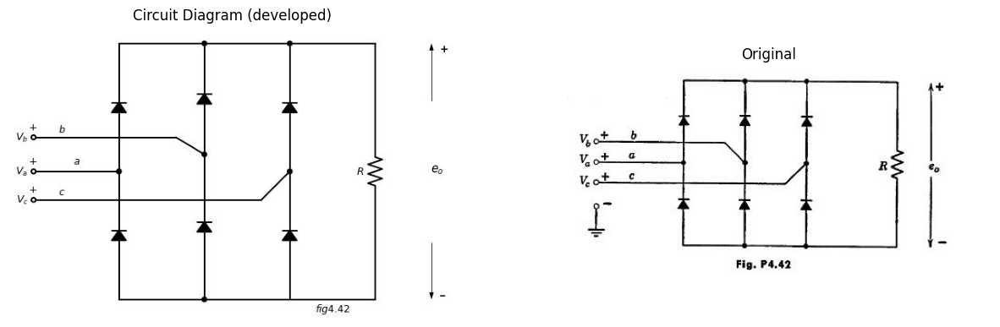

In [106]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().length(0.02).dot(open=True).label('$V_a$ ','left' ).label('$+$ ','top' ))
d+= (l2:=elm.Line().right().length(3).label('$a$ ','top' ).dot())
d += (D1 :=elm.Diode(fill=True).up(d.unit*1.5))
d += (D2 :=elm.Diode(fill=True).down(d.unit*1.5).reverse().at(l2.end))
d+= (l3:=elm.Line().right().length(3).dot())
d += (D3 :=elm.Diode(fill=True).up(d.unit*1.7).dot())
d+= (l4:=elm.Line().right().length(0.02).dot(open=True).label('$V_b$ ','left' ).label('$+$ ','top' ).at((0,1.2)))
d+= (l5:=elm.Line().right().length(2).label('$b$ ','top' ))
d+= (l6:=elm.Line().right().length(3))
d+= (l7:=elm.Line().right().length(3).endpoints(l6.end,D3.end))
d += (D4 :=elm.Diode(fill=True).up(d.unit*1.3).dot().at(D3.end))
d+= (l8:=elm.Line().right().length(9).at(D1.end))
d+= (l9:=elm.Line().right().length(3).at(D3.start))
d += (D5 :=elm.Diode(fill=True).up(d.unit*1.5).dot().at(l9.end))
d += (D4 :=elm.Diode(fill=True).up(d.unit*1.5).dot())
d+= (l10:=elm.Line().right().length(0.02).dot(open=True).label('$V_c$ ','left' ).label('$+$ ','top' ).at((0,-1)))
d+= (l11:=elm.Line().right().length(2).label('$c$ ','top' ))
d+= (l12:=elm.Line().right().length(6))
d+= (l13:=elm.Line().right().length(3).endpoints(l12.end,D5.end))
d+= (l14:=elm.Line().right().length(3).at(D5.start).label('$fig4.42$', 'bottom'))
d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$ ','top' ).endpoints(l14.end,l8.end))
d += elm.Arrow().up().length(2).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((14,2.5))
d += elm.Arrow().down().length(2).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((14,-2.5))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((12.5,-1.2))
d.save('Drawings/5FP4-42.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-42.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-42.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


4.23.($a$) Sketch the output voltage $e_0$, for the circuit of Problem 4.22, if the input voltages are balanced three phase voltages, that is,

$v_1 = v_b - v_a = V sin wt$

$v_2 = v_c - v_b = V sin (wt-120)$

$v_3 = v_a - v_c = V sin (wt-240)$

($b$)What is the fundamental frequency of the ripple voltage in the output with the input of ($a$)?

($c$)What is the per-unit ripple?

4.24. The elements in the circuit of Fig. P4.43($a$) are ideal.  In addition, √$L/C$ is small enough so that the tuned circuit voltage is, for all practical purposes, sinusoidal, and $wR_1 C_1$ >> 1. As far as can be determined from bridge measurements over a range of frequencies in the vicinity of the tuned circuit resonant frequency, the terminal behavior of the circuit facing the current source is the same as that of the circuit shown in Fig. P4.43($b$).


In [15]:
import ipywidgets as widgets 
from ipywidgets import *
import schemdraw
import schemdraw.elements as elm
@interact( Mode=(True))
def response( Mode=True):

    with schemdraw.Drawing() as d:
        if (Mode):
            d += (V1:=elm.SourceSin().up(d.unit*1.4).label('$I$$coswt$ ','top' ))
            d+= (l1:=elm.Line().right().length(4))
            d+= (l2:=elm.Line().down().length(.7))
            d+= (l3:=elm.Line().right().length(.5))
            d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','bottom' ))
            d+= (l4:=elm.Line().left().length(.5).at(l2.end))
            d += (L1:=elm.Inductor().down(d.unit*1).label('$L$ ','top' ))
            d+= (l5:=elm.Line().right().length(.5))
            d+= (l6:=elm.Line().right().length(.5))
            d+= (l7:=elm.Line().down().length(.5).at(l5.end))
            d+= (l8:=elm.Line().right().length(10.5).at(V1.start).label('$(a)$ ','bottom' ))
            d += (D1 :=elm.Diode(fill=True).right(d.unit*1.5).at(l1.end).dot())
            d += (C1 :=elm.Capacitor().down(d.unit*1.4).label('$C_1$ ','bottom' ))
            d+= (l9:=elm.Line().right().length(2).at(D1.end))
            d += (R1 :=elm.Resistor().down(d.unit*1.4).label('$R_1$ ','top' ))
            d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((5.5,3.5))
            d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .1)). at((5.5,.8))
            d += elm.Gap().up().label(  '$E$$coswt$' , ofst=-1.7 , fontsize = 16).color('black').at((4,1.5))
        else:
            d+= (l1:=elm.Line().right().length(0.02).dot(open=True))
            d+= (l2:=elm.Line().right().length(4))
            d+= (l3:=elm.Line().down().length(1))
            d+= (l4:=elm.Line().right().length(1))
            d+= (l5:=elm.Line().left().length(1).at(l3.end))
            d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','bottom' ).at(l4.end))
            d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$ ','bottom' ).at(l3.end))
            d += (L1 :=elm.Inductor().down(d.unit*1).label('$L$ ','bottom' ).at(l5.end))
            d+= (l6:=elm.Line().left().length(1).endpoints(C1.end,L1.end))
            d+= (l7:=elm.Line().down().length(1).at(R1.end))
            d+= (l8:=elm.Line().left().length(4).dot(open=True).label('$(b)$ ','bottom' ))
          
    

interactive(children=(Checkbox(value=True, description='Mode'), Output()), _dom_classes=('widget-interact',))

![](images/5fp4-43.JPG)

($a$) What power is dissipated in $R_1$ ?

($b$) What power is dissipated in the diode?

($c$)Relate $I$ to $E$.

($d$)What value of $R$ was determined from the bridge measurements?


4.25. In Fig. P4.44, voltage $e_1$, is a square wave of amplitude $E_1$ and capacitor $C$ is so large that ripple in the output voltage $E_2$ may be ignored. Derive the relation between $E_1$, and $E_2$ Show that $E_2=f (E_1^2)$  is asymptotic to a 

Text(0.5, 1.0, 'Original')

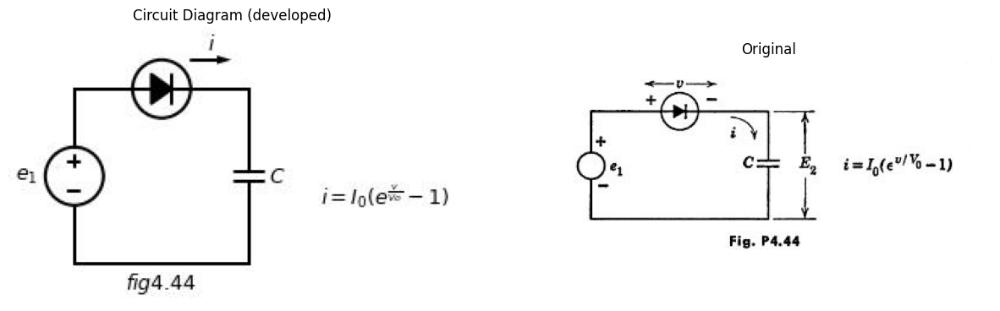

In [108]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label('$e_1$ ','top' ))
D1 = d.add(elm.Diode(fill=True).right())
ss1 = d.add(elm.Source().right().at(D1.start))
d += (C1 :=elm.Capacitor().down(d.unit*1).label('$C$ ','bottom' ))
d+= (l2:=elm.Line().left().length(3).label('$fig4.44$', 'bottom'))
d += elm.Arrow().right().length(.7).color('black').label('$i$', loc='top', color='black'). at((2,3.5))
d += elm.Arrow().right().length(.7).color('white').label(r'$i=$$I_0$$(e^\frac{v}{Vo} -1)$', loc='bottom', color='black'). at((5,1.5))
d.save('Drawings/5FP4-44.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-44.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-44.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


parabola for small $E_1$ and to a straight line for large $E_1$. Plot the two asymptotes in the $E_2/V_0$  versus $E_1/V_0$ plane. Find one or two points in the transition region between asymptotes, and sketch the curve $E_2=f (E_1^2)$ .

4.26. The process called frequency conversion is a form of modulation used in superhetrodyne radio receivers and in other parts of communication systems where the sum or difference of two frequencies is needed. The use of a square-law curve for the diode in Pig. P4.45 simplifies the determination of output voltage $e_0$.  The square-law approximation can be justified by noting that this term (of a series representation of the diode curve) yields the desired difierence frequency. In a practical circuit, resistance $R$ is replaced by a filter to enhance the desired frequency component and reject all others, including those generated by the terms other than square law. Find all of the frequencies generated in the output, assuming $E_a > E_1 + E_2$.

4.27. For the balanced modulator circuit shown in Fig. P4.46, assume $e_1 = E_1  sin w_1 t$ and $e_2 = E_2 sin w_2 t$ , with $E_2 >> E_1$ and $w_2 >> w_1$. Sketch the wave- form of output voltage $e_0$.

Text(0.5, 1.0, 'Original')

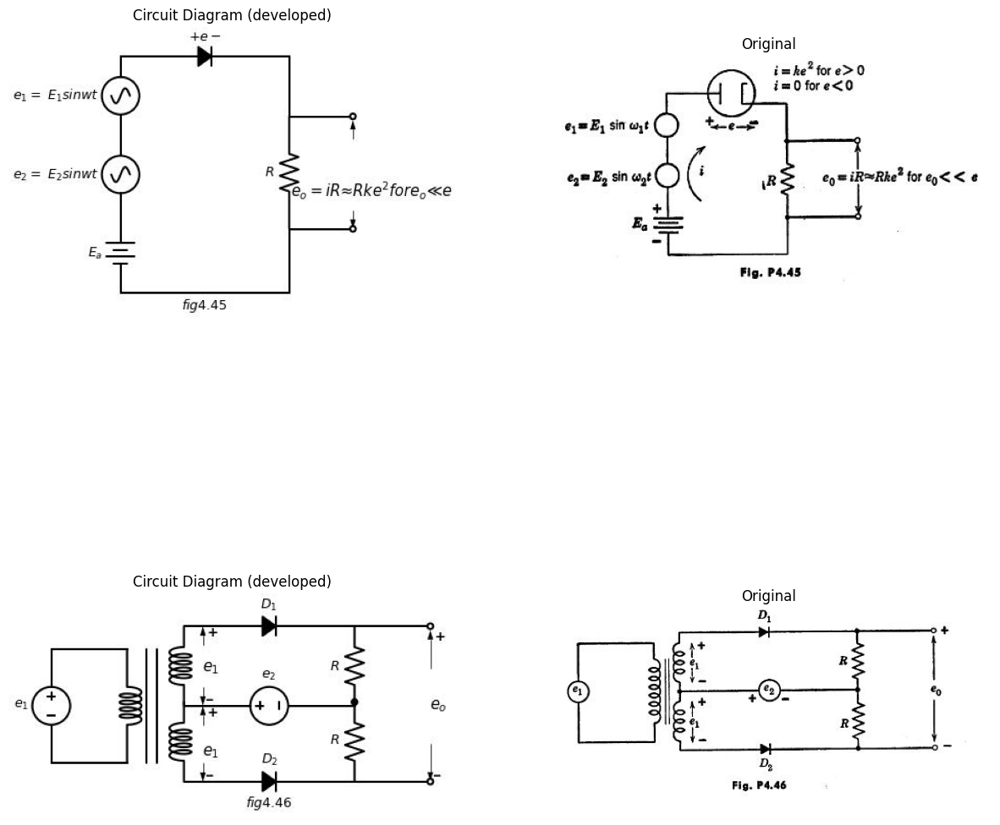

In [110]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(2, 2, figsize=(15, 15))
d = schemdraw.Drawing()
V1 = d.add(elm.Battery().up(d.unit*.7).label('$E_a$', 'top').reverse())
d += (V2:=elm.SourceSin().up(d.unit*.7).label(r'$e_2=$ $E_2$$sinwt$','top' ))
d += (V3:=elm.SourceSin().up(d.unit*.7).label(r'$e_1=$ $E_1$$sinwt$','top' ))
D1 = d.add(elm.Diode(fill=True).right(d.unit*1.5).label('$+   e   -$', 'top'))
d+= (l1:=elm.Line().down().length(1.6))
d += (R1 :=elm.Resistor().down(d.unit*1).label('$R$ ','top' ))
d+= (l2:=elm.Line().down().length(1.7))
d+= (l3:=elm.Line().left().length(4.5).label('$fig4.45$', 'bottom'))
d+= (l4:=elm.Line().right().length(1.7).at(R1.start).dot(open=True))
d+= (l5:=elm.Line().right().length(1.7).at(R1.end).dot(open=True))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black'). at((6.2,4.1))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black'). at((6.2,2.2))
d += elm.Gap().up().label(  '$e_o=$$iR≈$$Rke^2$$for e_o≪e$' , ofst=-1.7 , fontsize = 16).color('black').at((5,1.5))
d.save('Drawings/5FP4-45f.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-45f.jpg')
axs[0,0].imshow(img)
axs[0,0].axis('off')  # Hide axes for image display
axs[0,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-45f.jpg')  # Load the PNG file
axs[0,1].imshow(img_sample)
axs[0,1].axis('off')  # Hide axes for image display
axs[0,1].set_title('Original')
d = schemdraw.Drawing()
d += (V1:=elm.SourceV().up(d.unit*1).label('$e_1$','top' ))
d+= (l1:=elm.Line().right().length(2))
d += (L1:=elm.Inductor2().down(d.unit*1))
d+= (l2:=elm.Line().left().length(2))
d+= (l3:=elm.Line().up().length(3).at((2.5,0)))
d+= (l4:=elm.Line().up().length(3).at((2.8,0)))
d += (L2:=elm.Inductor2().up(d.unit*.7).at((3.5,1.5)))
d += (L3:=elm.Inductor2().up(d.unit*.7).at((3.5,-.5)))
D1 = d.add(elm.Diode(fill=True).right(d.unit*1.5).label('$D_1$', 'top').at(L2.end))
d += (R1 :=elm.Resistor().down(d.unit*.7).label('$R$ ','top' ))
d += (V1:=elm.SourceV().left(d.unit*1.5).label('$e_2$','top' ))
D2 = d.add(elm.Diode(fill=True).right(d.unit*1.5).label('$D_2$', 'top').at(L3.start).label('$fig4.46$', 'bottom'))
d += (R2 :=elm.Resistor().up(d.unit*.7).label('$R$ ','top' ).dot())
d+= (l5:=elm.Line().right().length(2).at(R1.start).dot(open=True))
d+= (l6:=elm.Line().right().length(2).at(R2.start).dot(open=True))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((4,3.1))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .1)). at((4,2))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,1.2))
d += elm.Arrow().up().length(.5).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((4,1))
d += elm.Arrow().down().length(.5).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .1)). at((4,-.01))
d += elm.Gap().up().label(  '$e_1$' , ofst=-1.7 , fontsize = 16).color('black').at((2.5,-1))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((10,2.5))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .1)). at((10,.5))
d += elm.Gap().up().label(  '$e_o$' , ofst=-1.7 , fontsize = 16).color('black').at((8.5,.2))
d.save('Drawings/5FP4-46j.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-46j.jpg')
axs[1,0].imshow(img)
axs[1,0].axis('off')  # Hide axes for image display
axs[1,0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-46j.jpg')  # Load the PNG file
axs[1,1].imshow(img_sample)
axs[1,1].axis('off')  # Hide axes for image display
axs[1,1].set_title('Original')

4.28. Repeat Problem 4.27 with $e_2$ consisting of brief rectangular pu1gea as shown in Fig. P4.47.  Assume the repetition frequency $f_2= 1/δ_2 $ exceeds


Text(0.5, 1.0, 'Original')

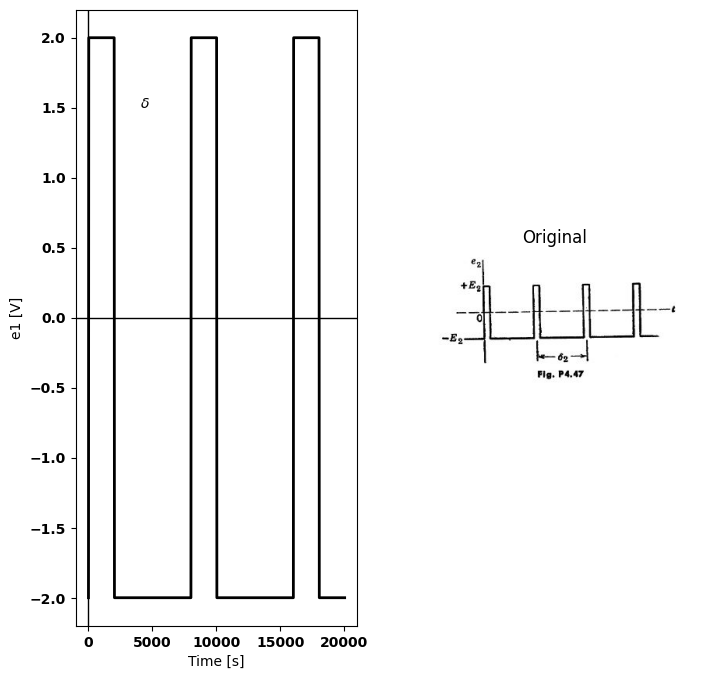

In [112]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
rcParams['font.weight'] = 'bold'
fig, axs = plt.subplots(1, 2, figsize=(8, 8))
rcParams['font.weight'] = 'bold'
circuit = Circuit('Transitional characteristic1')
#circuit.model('BAV21','D' ,IS = 1@u_uA   ,BV = 293.10@u_V, IBV = 0.001293@u_A , RS = 10@u_Ohm )
pulse1 = circuit.PulseVoltageSource('V1', '1', circuit.gnd, initial_value=-2@u_V, pulsed_value=2@u_V, pulse_width=2@u_ms, period=8@u_ms)
circuit.R(1, '1', 'e2', 25@u_kOhm)
circuit.C(1, 'e2',circuit.gnd,0.1@u_uF )

simulator = circuit.simulator(temperature=25, nominal_temperature=25)
analysis = simulator.transient(step_time=1@u_us, end_time=20@u_ms)
axs[0].plot(analysis['1'],'black',linestyle='-',linewidth=2) 
axs[0].set_xlabel('Time [s]')
axs[0].text(4000,1.5, r'$δ$ ', fontsize=10)
#axs[0].text(7500,-3, ' $40$ ', fontsize=10)
axs[0].annotate('', xy=(6000, -2.5), xytext=(10000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[0].annotate('', xy=(0, -2.5), xytext=(6000,-2.5), arrowprops=dict(arrowstyle='<->'))
axs[0].set_ylabel('e1 [V]')
axs[0].axhline(0, color='black', linewidth=1)
axs[0].axvline(0, color='black', linewidth=1)
img_sample = mpimg.imread('images/5fp4-47.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')

$f_1 = w_1t/2π$.  Note that the output consists of “samples” of the input taken at the time of each rectangular pulse.


4.29. The phase sensitive detector shown in Fig. P4.48 is driven by a reference voltage $v_r$ and a signal voltage $v_s$, where

$v_r = V_r cos 800 πt $

Assume ideal diodes and investigate the circuit's characteristics under the following conditions.

($a$) Plot the output voltage as a time function if $v_r  = 100 cos 800πt$ volts and $v_s = 50 cos 800πt $volts.

($b$) Plot the output voltage as a time function if $v_r  = 100 cos 800πt$ volts and$v_s = 50 cos 800πt $ volts.


Text(0.5, 1.0, 'Original')

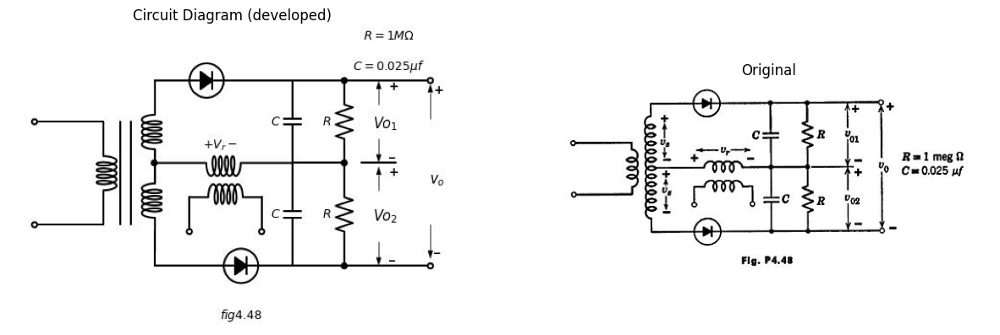

In [113]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib.image as mpimg
import numpy as np
from schemdraw import dsp
import schemdraw
import schemdraw.elements as elm
import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging()
from PySpice.Probe.Plot import plot
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *
# Create the figure and subplots
fig, axs = plt.subplots(1, 2, figsize=(15, 15))
d = schemdraw.Drawing()
d+= (l1:=elm.Line().right().length(0.002).dot(open=True))
d+= (l2:=elm.Line().right().length(2))
d += (L1:=elm.Inductor2().down(d.unit*1))
d+= (l3:=elm.Line().left().length(2).dot(open=True))
d+= (l4:=elm.Line().up().length(3).at((2.5,-3)))
d+= (l5:=elm.Line().up().length(3).at((2.8,-3)))
d += (L2:=elm.Inductor2().up(d.unit*1).at((3.5,-1.8)))
d += (L3:=elm.Inductor2().up(d.unit*1).at((3.5,-3.8)))
D1 = d.add(elm.Diode(fill=True).right().at(L2.end))
ss1 = d.add(elm.Source().right().at(D1.start))
d+= (l6:=elm.Line().right().length(1))
d += (C1 :=elm.Capacitor().down(d.unit*.8).label('$C$ ','top' ))
d += (L4:=elm.Inductor2().left(d.unit*1.34).dot().label('$+ V_r  -$ ','top' ))
d += (C2 :=elm.Capacitor().down(d.unit*1).label('$C$ ','top' ).at(C1.end))
D1 = d.add(elm.Diode(fill=True).left().reverse().label('\n\n$fig4.48$', 'bottom'))
ss1 = d.add(elm.Source().left().at(D1.start))
d+= (l8:=elm.Line().left().length(1))
d+= (l9:=elm.Line().up().length(1))
d += (L5:=elm.Inductor2().right(d.unit*.7).at((4.5,-2.2)))
d+= (l10:=elm.Line().down().length(1).at(L5.end).dot(open=True))
d+= (l11:=elm.Line().down().length(1).at(L5.start).dot(open=True))
d+= (l12:=elm.Line().right().length(1.5).at(C1.start).dot())
d+= (l13:=elm.Line().right().length(1.5).at(C1.end).dot())
d+= (l14:=elm.Line().right().length(1.5).at(C2.end).dot())
d += (R1 :=elm.Resistor().down(d.unit*.7).label('$R$ ','top' ).endpoints(l12.end,l13.end))
d += (R2 :=elm.Resistor().down(d.unit*.7).label('$R$ ','top' ).endpoints(l13.end,l14.end))
d+= (l15:=elm.Line().right().length(2.5).at(R1.start).dot(open=True).label('$R=1MΩ$\n\n$C=0.025μf$ ','top' ))
d+= (l16:=elm.Line().right().length(2.5).at(R2.end).dot(open=True))
d += elm.Arrow().up().length(1).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.1). at((11.5,0.1))
d += elm.Arrow().down().length(1).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .1)). at((11.5,-3))
d += elm.Gap().up().label(  '$v_o$' , ofst=-1.7 , fontsize = 16).color('black').at((10,-3))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10,-2))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10,-3.5))
d += elm.Gap().up().label(  '$Vo_2$' , ofst=-1.7 , fontsize = 16).color('black').at((8.5,-4))
d+= (l17:=elm.Line().right().length(1).at((9.5,-1.2)))
d += elm.Arrow().up().length(.7).linewidth(.75).color('black').label('+',loc='end', color='black',ofst=-.3). at((10,.5))
d += elm.Arrow().down().length(.7).linewidth(.75).color('black').label(r'_', loc='end', color='black',ofst=(-.5, .3)). at((10,-.5))
d += elm.Gap().up().label(  '$Vo_1$' , ofst=-1.7 , fontsize = 16).color('black').at((8.5,-1.3))
d.save('Drawings/5FP4-48.jpg')  # Save the drawing to a PNG file
img = mpimg.imread('Drawings/5FP4-48.jpg')
axs[0].imshow(img)
axs[0].axis('off')  # Hide axes for image display
axs[0].set_title('Circuit Diagram (developed)')
# **Subplot (1, 2): PNG Sample File**
img_sample = mpimg.imread('images/5fp4-48.jpg')  # Load the PNG file
axs[1].imshow(img_sample)
axs[1].axis('off')  # Hide axes for image display
axs[1].set_title('Original')


($c$) Plot a vector diagram that illustrates how the output of this circuit varies with the phase angle  $ ϕ $ for

$v_s = V_s  cos (800πt + ϕ )$

$v_r = V_r  cos 800πt $

<!--NAVIGATION-->
( Previous: [**3.1 Resistive Diode Circuits**](../Chapter.3/chapter3.ipynb)( [**TOC**](../TOC.md) | Next: [**5.1 Transistor Models and Circuits**](../chapter.5/chapter5.ipynb) )


[**This file as MS Word (docx)**](./Docs/chapter4.docx) 
